# Pengolahan Citra Digital
**Kadek Diah Purnama Lestari R. - 2505551044** || 
**Ramadhan Maulana Fahlevy - 2505551016** || 
**Ni Putu Ayu Sundari - 2505551015**

## Sel 0 - Preparation

In [23]:
%pip install numpy matplotlib pillow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\yori\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## Sel 1 - Import + konfigurasi + semua fungsi
Satu-satunya sel berisi `import` dan definisi fungsi. Ganti nama file di dict `FILE`.

In [24]:
# =====================================================================
#  SEL 1 - SEMUA IMPORT + KONFIGURASI + SEMUA FUNGSI
#  Sel-sel Tugas di bawah hanya MEMANGGIL fungsi dari sel ini.
#
#  ATURAN YANG DIPAKAI (sesuai permintaan dosen):
#  - TIDAK memakai cv2 / skimage / scipy.
#  - Setiap operasi ditulis dengan RUMUS BUKU (bukan fungsi siap pakai
#    seperti rotate(), flip(), resize(), threshold(), median(), histogram()).
#  - numpy hanya dipakai sebagai "wadah matriks" + operasi + - x / per piksel.
#  - PIL hanya untuk MEMBUKA file png/jpg (decode) dan MENYIMPAN gambar.
#    Properti (lebar, tinggi, depth) dibaca MANUAL dari header file.
# =====================================================================
import math
import os

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ---------------------------------------------------------------------
# KONFIGURASI: ganti nama file di sini saja (bmp / png / jpg boleh)
# ---------------------------------------------------------------------
FILE = {
    "tugas1"    : "try_to_up.bmp",      # ekstrak resolusi & nilai f(x,y)
    "tugas2"    : "try_to_up.bmp",      # operasi titik
    "geometri"  : "image_rgb_1.bmp",    # operasi geometri
    "citra_a"   : "meng1.bmp",          # multi image (A)
    "citra_b"   : "meng2.bmp",          # multi image (B)
    "ekualisasi": "low_contrast.bmp",   # operasi global
    "tetangga"  : "Coba.bmp",           # operasi bertetangga
    "threshold" : "image_rgb_1.bmp",    # thresholding
    "blur"      : "Blur.png",           # studi kasus
    "noise"     : "Noise.png",          # studi kasus
    "kontras"   : "low_contrast.bmp",   # studi kasus
}
BATAS_TXT = None           # None = SEMUA citra ditulis lengkap ke txt (isi angka mis. 2000 bila mau dibatasi)
CETAK_MAKS = 100           # citra <= 100 x 100 -> semua nilai f(x,y) dicetak juga ke layar (Tugas 1)
FOLDER_OUT = "hasil"       # semua output (txt, gambar) masuk ke sini
os.makedirs(FOLDER_OUT, exist_ok=True)

def out(nama):
    """Path file output di dalam folder hasil."""
    return os.path.join(FOLDER_OUT, nama)


# =====================================================================
# A. PROPERTI CITRA - DIBACA MANUAL DARI HEADER (BMP, PNG, JPG)
#    -> lebar (w) dan tinggi (h) DIAMBIL DARI PROPERTI FILE, bukan ditebak
# =====================================================================
def _int_le(b):  # little-endian (BMP)
    return int.from_bytes(b, "little")

def _int_be(b):  # big-endian (PNG, JPG)
    return int.from_bytes(b, "big")

def baca_properti(nama_file, cetak=True):
    """
    Membaca properti citra langsung dari byte header:
        BMP : tanda 'BM'; lebar = byte 18-21, tinggi = byte 22-25, depth = byte 28-29
        PNG : tanda 89 50 4E 47; chunk IHDR -> lebar byte 16-19, tinggi 20-23,
            bit depth byte 24, color type byte 25 (0=gray,2=RGB,3=palet,4=gray+alpha,6=RGBA)
        JPG : tanda FF D8; cari marker SOF (FF C0..C2) -> presisi, tinggi, lebar, jumlah komponen
    Depth color (bit per piksel) = bit per kanal x jumlah kanal.
    """
    if not os.path.exists(nama_file):
        raise FileNotFoundError(f"File '{nama_file}' tidak ditemukan. Cek dict FILE di Sel 1.")
    with open(nama_file, "rb") as f:
        data = f.read()
    info = {"file": nama_file, "ukuran_file_byte": len(data)}

    if data[:2] == b"BM":
        info["format"] = "BMP"
        info["lebar"] = _int_le(data[18:22])
        tinggi_asli = int.from_bytes(data[22:26], "little", signed=True)
        info["tinggi"] = abs(tinggi_asli)
        info["depth"] = _int_le(data[28:30])
        info["kanal"] = {1: 1, 4: 1, 8: 1, 24: 3, 32: 4}.get(info["depth"], "?")
        info["offset_data"] = _int_le(data[10:14])
        info["kompresi"] = _int_le(data[30:34])
        ppm = _int_le(data[38:42])                    # piksel per meter
        info["dpi"] = round(ppm * 0.0254) if ppm else None

    elif data[:8] == b"\x89PNG\r\n\x1a\n":
        info["format"] = "PNG"
        info["lebar"] = _int_be(data[16:20])
        info["tinggi"] = _int_be(data[20:24])
        bit_kanal = data[24]
        tipe = data[25]
        kanal = {0: 1, 2: 3, 3: 1, 4: 2, 6: 4}[tipe]
        info["tipe_warna"] = {0: "Grayscale", 2: "RGB", 3: "Berindeks (palet)",
                            4: "Grayscale + alpha", 6: "RGBA"}[tipe]
        info["kanal"] = kanal
        info["bit_per_kanal"] = bit_kanal
        info["depth"] = bit_kanal * kanal
        info["dpi"] = None

    elif data[:2] == b"\xff\xd8":
        info["format"] = "JPEG"
        i = 2
        while i < len(data) - 9:
            if data[i] != 0xFF:
                i += 1
                continue
            marker = data[i + 1]
            panjang = _int_be(data[i + 2:i + 4])
            if marker in (0xC0, 0xC1, 0xC2):          # SOF = Start Of Frame
                presisi = data[i + 4]
                info["tinggi"] = _int_be(data[i + 5:i + 7])
                info["lebar"] = _int_be(data[i + 7:i + 9])
                info["kanal"] = data[i + 9]
                info["bit_per_kanal"] = presisi
                info["depth"] = presisi * data[i + 9]
                break
            i += 2 + panjang
        info["dpi"] = None
    else:
        img = Image.open(nama_file)                   # format lain: cadangan lewat PIL
        info["format"] = img.format
        info["lebar"], info["tinggi"] = img.size
        info["depth"] = {"1": 1, "L": 8, "P": 8, "RGB": 24, "RGBA": 32}.get(img.mode, "?")
        info["dpi"] = None

    info["jumlah_piksel"] = info["lebar"] * info["tinggi"]
    if isinstance(info["depth"], int):
        info["jumlah_warna"] = 2 ** info["depth"] if info["depth"] <= 24 else 2 ** 24
        info["memori_byte"] = info["lebar"] * info["tinggi"] * info["depth"] // 8
    if cetak:
        print("=" * 60)
        print(f"Nama file      : {nama_file}")
        print(f"Format         : {info['format']}")
        print(f"Resolusi       : {info['lebar']} x {info['tinggi']} piksel (lebar w x tinggi h)")
        print(f"Jumlah piksel  : {info['jumlah_piksel']:,}")
        print(f"Depth color    : {info['depth']} bit/piksel", end="")
        if "tipe_warna" in info:
            print(f"  ({info['tipe_warna']})", end="")
        print()
        if "jumlah_warna" in info:
            print(f"Jumlah warna   : 2^{min(info['depth'], 24)} = {info['jumlah_warna']:,}")
            print(f"Memori data    : {info['lebar']} x {info['tinggi']} x {info['depth']} bit "
                f"= {info['memori_byte']:,} byte ({info['memori_byte'] / 1024:.1f} KB)")
        print(f"Ukuran file    : {info['ukuran_file_byte']:,} byte")
        if info.get("dpi"):
            print(f"Resolusi cetak : {info['dpi']} dpi")
        print("=" * 60)
    return info


def baca_citra(nama_file, mode="rgb"):
    """
    mode 'rgb'  -> matriks (h, w, 3)  nilai 0..255
    mode 'gray' -> matriks (h, w)     (dikonversi pakai rumus grayscale di bawah)
    PIL hanya dipakai untuk men-decode isi file (png/jpg terkompresi).
    """
    if not os.path.exists(nama_file):
        raise FileNotFoundError(f"File '{nama_file}' tidak ditemukan. Cek dict FILE di Sel 1.")
    rgb = np.array(Image.open(nama_file).convert("RGB")).astype(np.uint8)
    if mode == "gray":
        return grayscale(rgb)
    return rgb


# =====================================================================
# B. HISTOGRAM & DISTRIBUSI KUMULATIF - MANUAL (loop, tanpa fungsi histogram)
# =====================================================================
def histogram(citra_2d, level=256):
    """h[i] = banyaknya piksel yang bernilai i  (dihitung satu per satu)."""
    h = [0] * level
    for v in citra_2d.ravel().tolist():
        h[int(v)] += 1
    return np.array(h)

def kumulatif(h):
    """C[i] = C[i-1] + h[i]   (distribusi kumulatif)."""
    C = [0] * len(h)
    jalan = 0
    for i in range(len(h)):
        jalan += int(h[i])
        C[i] = jalan
    return np.array(C)

def potong_0_255(m):
    """Clipping: < 0 -> 0, > 255 -> 255, lalu dibulatkan."""
    m = np.asarray(m, dtype=np.float64)
    m = np.where(m < 0, 0, m)
    m = np.where(m > 255, 255, m)
    return np.floor(m + 0.5).astype(np.uint8)        # round half up (>= 0,5 naik)

ke_uint8 = potong_0_255


# =====================================================================
# C. OUTPUT: TXT, SIMPAN GAMBAR, TAMPIL CITRA + HISTOGRAM
# =====================================================================
def _str_nilai(v):
    if isinstance(v, np.ndarray):
        return "(" + ",".join(str(int(c)) for c in v) + ")"
    return str(int(v)) if float(v).is_integer() else f"{float(v):.2f}"

def simpan_ke_txt(nama_file, judul, daftar_data, paksa=False):
    """
    daftar_data = [(jenis, nama, array), ...]  (array 2D gray/biner atau 3D RGB)
    Ditulis sebagai matriks berkoordinat (x di atas, y di kiri).
    """
    if not paksa and BATAS_TXT and any(max(a.shape[:2]) > BATAS_TXT for _, _, a in daftar_data):
        print(f"[dilewati] {nama_file}: citra > {BATAS_TXT} px. Pakai citra kecil atau paksa=True.")
        return
    with open(nama_file, "w", encoding="utf-8") as f:
        f.write(f"=== {judul} ===\n\n")
        for jenis, nama, arr in daftar_data:
            arr = np.asarray(arr)
            tinggi, lebar = arr.shape[:2]
            f.write(f"{jenis} : {nama} | lebar w = {lebar}, tinggi h = {tinggi}\n" + "-" * 60 + "\n")
            if arr.ndim == 2:
                f.write("      " + "".join(f"x={x:<5d}" for x in range(lebar)) + "\n")
                for y in range(tinggi):
                    f.write(f"y={y:<3d}| " + " ".join(f"{_str_nilai(v):>6}" for v in arr[y]) + "\n")
            else:
                for y in range(tinggi):
                    f.write(f"y={y:<3d}| " + " ".join(_str_nilai(arr[y, x]) for x in range(lebar)) + "\n")
            f.write("\n" + "=" * 60 + "\n\n")
    print(f"Matriks piksel disimpan: {nama_file}")

def tulis_sebelum_sesudah(nama_file, judul, awal, hasil):
    """
    Format seperti tugas sebelumnya (01_fungsi_grayscale.txt dst):
        NILAI CITRA SEBELUM PROSES -> f(x,y) = nilai   (satu baris citra = satu baris teks)
        NILAI CITRA SESUDAH PROSES -> f(x,y) = nilai
    """
    with open(nama_file, "w", encoding="utf-8") as f:
        f.write(f"=== {judul} ===\n\n")
        for label, arr in (("SEBELUM", awal), ("SESUDAH", hasil)):
            arr = np.asarray(arr)
            f.write(f"NILAI CITRA {label} PROSES  (lebar {arr.shape[1]} x tinggi {arr.shape[0]})\n" + "=" * 60 + "\n\n")
            for y in range(arr.shape[0]):
                f.write("  ".join(f"f({x},{y}) = {_str_nilai(arr[y, x])}" for x in range(arr.shape[1])) + "\n")
            f.write("\n")
    print(f"Nilai sebelum & sesudah disimpan: {nama_file}")

def info_citra(citra, nama="Citra"):
    """Ringkasan nilai citra (seperti versi lama)."""
    citra = np.asarray(citra)
    print("\n" + "=" * 50)
    print(f"INFORMASI: {nama}")
    print("=" * 50)
    print(f"Ukuran citra   : lebar {citra.shape[1]} x tinggi {citra.shape[0]}"
        + (f" x {citra.shape[2]} kanal" if citra.ndim == 3 else " (1 kanal)"))
    print(f"Nilai minimum  : {citra.min()}")
    print(f"Nilai maksimum : {citra.max()}")

def cetak_nilai(daftar, n=6, x0=0, y0=0):
    """
    Cetak nilai piksel ke layar, berdampingan: [(judul, citra), ...]
    Default pojok kiri atas n x n piksel (ubah x0, y0 untuk melihat bagian lain).
    Nilai LENGKAP semua piksel ada di file txt.
    """
    for judul, c in daftar:
        c = np.asarray(c)
        h, w = c.shape[:2]
        print(f"\n--- {judul} ({w} x {h}) | nilai f(x,y) untuk x={x0}..{min(w, x0 + n) - 1}, "
            f"y={y0}..{min(h, y0 + n) - 1} ---")
        print("        " + "".join(f"{'x=' + str(x):>15}" for x in range(x0, min(w, x0 + n))))
        for y in range(y0, min(h, y0 + n)):
            print(f"y={y:<5}" + "".join(f"{_str_nilai(c[y, x]):>15}" for x in range(x0, min(w, x0 + n))))

def simpan_gambar(nama_file, arr):
    """Simpan array ke file gambar. Citra biner 0/1 otomatis diskalakan ke 0/255."""
    a = np.asarray(arr)
    if a.dtype != np.uint8:
        a = potong_0_255(a)
    if a.max() <= 1:
        a = (a * 255).astype(np.uint8)
    Image.fromarray(a).save(nama_file)
    print(f"Gambar disimpan: {nama_file}")

def _tampil_gambar(ax, citra, judul):
    citra = np.asarray(citra)
    if citra.ndim == 2:
        vmax = 1 if citra.max() <= 1 else 255
        ax.imshow(citra, cmap="gray", vmin=0, vmax=vmax)
    else:
        ax.imshow(citra)
    ax.set_title(judul, fontsize=10)
    ax.axis("off")

def _tampil_hist(ax, citra, judul, ymax=None):
    """Batang histogram dari hasil hitung MANUAL (fungsi histogram di atas)."""
    citra = np.asarray(citra)
    x = np.arange(256)
    if citra.ndim == 2:
        if citra.max() <= 1:                                  # citra biner 0/1
            h = histogram(citra, 2)
            ax.bar([0, 1], h, color="gray", width=0.6)
            ax.set_xticks([0, 1])
        else:
            ax.bar(x, histogram(potong_0_255(citra)), color="gray", width=1.0)
            ax.set_xlim(0, 255)
    else:
        for k, warna in enumerate(["red", "green", "blue"]):
            ax.plot(x, histogram(citra[:, :, k]), color=warna, lw=1, label="RGB"[k])
        ax.set_xlim(0, 255)
        ax.legend(fontsize=8)
    if ymax is not None:
        ax.set_ylim(0, ymax)
    ax.set_title(f"Histogram {judul}", fontsize=9)
    ax.set_xlabel("Nilai intensitas")
    ax.set_ylabel("Frekuensi")

def tampil_citra_hist(daftar, judul_besar="", sumbu_y_sama=False, simpan=None, lebar_kolom=4.5):
    """daftar = [(judul, citra), ...]  -> baris atas: citra, baris bawah: histogram."""
    ymax = None
    if sumbu_y_sama:
        ymax = 0
        for _, c in daftar:
            c = np.asarray(c)
            kanal = [c] if c.ndim == 2 else [c[:, :, k] for k in range(3)]
            for k in kanal:
                ymax = max(ymax, histogram(potong_0_255(k)).max())
        ymax *= 1.05
    n = len(daftar)
    fig, ax = plt.subplots(2, n, figsize=(lebar_kolom * n, 8), squeeze=False)
    for i, (judul, c) in enumerate(daftar):
        _tampil_gambar(ax[0, i], c, judul)
        _tampil_hist(ax[1, i], c, judul, ymax)
    if judul_besar:
        fig.suptitle(judul_besar, fontweight="bold")
    plt.tight_layout()
    if simpan:
        fig.savefig(simpan, dpi=120, bbox_inches="tight")
    plt.show()

def cetak_histogram(citra, judul="Citra", per_baris=8):
    """
    Nilai histogram (hasil hitung manual): hanya nilai yang frekuensinya > 0.
    Gray -> satu tabel; RGB -> tabel R, G, B.
    """
    citra = np.asarray(citra)
    kanal = [("Gray", citra)] if citra.ndim == 2 else [(nm, citra[:, :, k]) for k, nm in enumerate("RGB")]
    print(f"\n--- NILAI HISTOGRAM {judul} (nilai: jumlah piksel) ---")
    for nm, c in kanal:
        level = 2 if c.max() <= 1 else 256
        h = histogram(potong_0_255(c) if level == 256 else c, level)
        isi = [f"{i:>3}:{int(h[i]):<5}" for i in range(level) if h[i] > 0]
        print(f"[{nm}] {len(isi)} nilai berbeda, total {int(sum(h))} piksel, "
            f"puncak di {int(np.argmax(h))} ({int(h.max())} piksel)")
        for i in range(0, len(isi), per_baris):
            print("   " + "  ".join(isi[i:i + per_baris]))

def _hist_teks(citra):
    citra = np.asarray(citra)
    kanal = [("Gray", citra)] if citra.ndim == 2 else [(nm, citra[:, :, k]) for k, nm in enumerate("RGB")]
    baris = []
    for nm, c in kanal:
        level = 2 if c.max() <= 1 else 256
        h = histogram(potong_0_255(c) if level == 256 else c, level)
        baris.append(f"[{nm}] " + "  ".join(f"{i}:{int(h[i])}" for i in range(level) if h[i] > 0))
    return "\n".join(baris)

def tampil_operasi(awal, hasil, judul_awal="Citra Awal", judul_hasil="Citra Hasil", n=6, txt=None, judul_txt=None):
    """
    Seperti versi lama: 3 panel -> [citra awal] [citra hasil] [histogram].
    Panel histogram: histogram HASIL (garis tebal) + histogram AWAL (garis putus-putus) supaya
    perubahannya langsung kelihatan. Lalu dicetak: informasi, nilai piksel awal & hasil,
    dan nilai histogram awal & hasil. txt -> semua nilai + histogram disimpan ke file.
    """
    awal, hasil = np.asarray(awal), np.asarray(hasil)
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    _tampil_gambar(ax[0], awal, judul_awal)
    _tampil_gambar(ax[1], hasil, judul_hasil)
    x = np.arange(256)
    def garis(c, gaya, label):
        if c.ndim == 2:
            if c.max() <= 1:
                h = histogram(c, 2)
                ax[2].bar([0, 255], h, width=12, color="gray" if gaya == "-" else "none",
                        edgecolor="black", ls=gaya, label=f"{label} (0 / 1)")
            else:
                ax[2].plot(x, histogram(potong_0_255(c)), color="black", ls=gaya, lw=1, label=label)
        else:
            for k, w in enumerate(["red", "green", "blue"]):
                ax[2].plot(x, histogram(c[:, :, k]), color=w, ls=gaya, lw=1.2 if gaya == "-" else 0.8,
                        label=f"{label} {'RGB'[k]}")
    garis(awal, ":", "awal")
    garis(hasil, "-", "hasil")
    ax[2].set_xlim(-5, 260)
    ax[2].set_title(f"Histogram {judul_hasil} (titik-titik = {judul_awal})", fontsize=10)
    ax[2].set_xlabel("Nilai intensitas"); ax[2].set_ylabel("Jumlah piksel")
    ax[2].grid(alpha=0.3); ax[2].legend(fontsize=7, ncol=2)
    plt.tight_layout(); plt.show()

    info_citra(awal, judul_awal)
    info_citra(hasil, judul_hasil)
    cetak_nilai([(judul_awal, awal), (judul_hasil, hasil)], n=n)
    cetak_histogram(awal, judul_awal)
    cetak_histogram(hasil, judul_hasil)
    if txt:
        tulis_sebelum_sesudah(txt, judul_txt or judul_hasil, awal, hasil)
        with open(txt, "a", encoding="utf-8") as f:
            f.write("=" * 60 + "\nNILAI HISTOGRAM SEBELUM PROSES (nilai:jumlah piksel)\n" + "=" * 60 + "\n")
            f.write(_hist_teks(awal) + "\n\n")
            f.write("=" * 60 + "\nNILAI HISTOGRAM SESUDAH PROSES (nilai:jumlah piksel)\n" + "=" * 60 + "\n")
            f.write(_hist_teks(hasil) + "\n")

def tampil_awal(citra, judul="Citra Awal"):
    """2 panel: citra awal + histogram citra awal (+ nilai histogramnya)."""
    citra = np.asarray(citra)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    _tampil_gambar(ax[0], citra, judul)
    _tampil_hist(ax[1], citra, judul)
    ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    info_citra(citra, judul)
    cetak_nilai([(judul, citra)])
    cetak_histogram(citra, judul)

def tampil_citra_saja(daftar, judul_besar="", lebar_kolom=4.5, simpan=None):
    n = len(daftar)
    fig, ax = plt.subplots(1, n, figsize=(lebar_kolom * n, 4.5), squeeze=False)
    for i, (judul, c) in enumerate(daftar):
        _tampil_gambar(ax[0, i], c, judul)
    if judul_besar:
        fig.suptitle(judul_besar, fontweight="bold")
    plt.tight_layout()
    if simpan:
        fig.savefig(simpan, dpi=120, bbox_inches="tight")
    plt.show()


# =====================================================================
# D. OPERASI TITIK  (rumus buku: Ko = f(Ki); RGB -> diterapkan ke tiap kanal)
# =====================================================================
def grayscale(citra, cara="ntsc"):
    """
    cara 'rata' : Ko = (R + G + B) / 3
    cara 'ntsc' : Ko = 0.299 R + 0.587 G + 0.114 B
    (Di buku tertulis wb = 0.144 -> salah ketik; 0.299+0.587+0.144 = 1.03 > 1.
    Bobot NTSC yang benar 0.114 sehingga jumlah bobot = 1.)
    """
    if citra.ndim == 2:
        return citra.astype(np.uint8)
    R = citra[:, :, 0].astype(np.float64)
    G = citra[:, :, 1].astype(np.float64)
    B = citra[:, :, 2].astype(np.float64)
    if cara == "rata":
        return potong_0_255((R + G + B) / 3)
    return potong_0_255(0.299 * R + 0.587 * G + 0.114 * B)

def brightness(citra, C=50):
    """Ko = Ki + C   (C > 0 lebih terang, C < 0 lebih gelap)"""
    return potong_0_255(citra.astype(np.float64) + C)

def contrast(citra, G=1.5, P=128):
    """Ko = G (Ki - P) + P   (G > 1 kontras naik, 0 < G < 1 kontras turun)"""
    return potong_0_255(G * (citra.astype(np.float64) - P) + P)

def negatif(citra, Kmax=255):
    """Ko = Kmax - Ki   (Kmax = 2^k - 1 = 255 untuk 8 bit/kanal)"""
    return (Kmax - citra.astype(np.int16)).astype(np.uint8)

def ambang_tunggal(abu, T):
    """Rumus 1 buku:  Ko = 0 jika Ki < T ;  Ko = 1 jika Ki >= T"""
    return np.where(abu >= T, 1, 0).astype(np.uint8)

def ambang_ganda(abu, T_bawah, T_atas):
    """Rumus 1 buku:  Ko = 0 jika T_bawah <= Ki <= T_atas ;  Ko = 1 lainnya"""
    return np.where((abu >= T_bawah) & (abu <= T_atas), 0, 1).astype(np.uint8)

def properti_array(citra, nama="Citra"):
    tinggi, lebar = citra.shape[:2]
    kanal = 1 if citra.ndim == 2 else citra.shape[2]
    print(f"[{nama}] resolusi {lebar} x {tinggi} | kanal {kanal} | depth {8 * kanal} bit/piksel "
        f"| min {citra.min()} | max {citra.max()}")

def cek_negasi(awal, hasil, titik=(0, 0), Kmax=255):
    """
    Pengecekan negasi (arahan dosen):
        1. properti citra awal vs hasil (resolusi & depth harus SAMA)
        2. nilai R,G,B satu piksel: awal -> akhir, Ko = 255 - Ki
        3. histogram hasil = histogram awal DIBALIK: h_hasil[i] = h_awal[255 - i]
        4. min/maks: min_hasil = 255 - maks_awal, maks_hasil = 255 - min_awal
    """
    properti_array(awal, "Citra awal  ")
    properti_array(hasil, "Citra negasi")
    x, y = titik
    nama = ["Gray"] if awal.ndim == 2 else ["R", "G", "B"]
    ka = [awal] if awal.ndim == 2 else [awal[:, :, k] for k in range(3)]
    kh = [hasil] if hasil.ndim == 2 else [hasil[:, :, k] for k in range(3)]
    print(f"\n--- Nilai satu piksel f(x={x}, y={y}) ---")
    for nm, a, h in zip(nama, ka, kh):
        ki, ko = int(a[y, x]), int(h[y, x])
        print(f"{nm}: awal Ki = {ki:3d} -> hasil Ko = {ko:3d}   ({Kmax} - {ki} = {Kmax - ki})  "
            f"{'OK' if ko == Kmax - ki else 'SALAH'}")
    print("\n--- Histogram harus saling berkebalikan ---")
    for nm, a, h in zip(nama, ka, kh):
        ha, hh = histogram(a), histogram(h)
        ok = all(hh[i] == ha[Kmax - i] for i in range(256))
        contoh = int(np.argmax(ha))
        print(f"{nm}: h_hasil[i] == h_awal[255-i] untuk semua i -> {'OK' if ok else 'SALAH'} | "
            f"contoh: puncak awal di {contoh} ({ha[contoh]} piksel) -> di hasil pindah ke "
            f"{Kmax - contoh} ({hh[Kmax - contoh]} piksel) | "
            f"rentang awal [{a.min()}..{a.max()}] -> hasil [{h.min()}..{h.max()}]")


# =====================================================================
# E. OPERASI GEOMETRI  (rumus koordinat buku; berlaku untuk gray 2D & RGB 3D)
#    Setiap piksel (x,y) dipindah ke (x',y') sesuai rumus. Lebar w & tinggi h
#    diambil dari ukuran matriks = properti citra (w = kolom, h = baris).
# =====================================================================
def _koordinat(img):
    h, w = img.shape[:2]
    ys, xs = np.mgrid[0:h, 0:w]          # semua pasangan (y, x)
    return h, w, ys, xs

def pencerminan_horizontal(img):
    """x' = w - 1 - x ;  y' = y"""
    h, w, ys, xs = _koordinat(img)
    hasil = np.zeros_like(img)
    hasil[ys, w - 1 - xs] = img[ys, xs]
    return hasil

def pencerminan_vertikal(img):
    """y' = h - 1 - y ;  x' = x"""
    h, w, ys, xs = _koordinat(img)
    hasil = np.zeros_like(img)
    hasil[h - 1 - ys, xs] = img[ys, xs]
    return hasil

def pencerminan_kombinasi(img):
    """x' = w - 1 - x ;  y' = h - 1 - y"""
    h, w, ys, xs = _koordinat(img)
    hasil = np.zeros_like(img)
    hasil[h - 1 - ys, w - 1 - xs] = img[ys, xs]
    return hasil

def rotasi_90_cw(img):
    """1/4 putaran searah jarum jam:  w' = h, h' = w ;  x' = w' - 1 - y ;  y' = x  (tanpa sin/cos)"""
    h, w, ys, xs = _koordinat(img)
    w_b, h_b = h, w
    hasil = np.zeros((h_b, w_b) + img.shape[2:], dtype=img.dtype)
    hasil[xs, w_b - 1 - ys] = img[ys, xs]
    return hasil

def rotasi_90_ccw(img):
    """1/4 putaran berlawanan jarum jam:  w' = h, h' = w ;  x' = y ;  y' = h' - 1 - x"""
    h, w, ys, xs = _koordinat(img)
    w_b, h_b = h, w
    hasil = np.zeros((h_b, w_b) + img.shape[2:], dtype=img.dtype)
    hasil[h_b - 1 - xs, ys] = img[ys, xs]
    return hasil

def rotasi_180(img):
    """1/2 putaran:  x' = w' - 1 - x ;  y' = h' - 1 - y   (w' = w, h' = h, tanpa sin/cos)"""
    h, w, ys, xs = _koordinat(img)
    hasil = np.zeros_like(img)
    hasil[h - 1 - ys, w - 1 - xs] = img[ys, xs]
    return hasil

rotasi_90 = rotasi_90_cw

def rotasi_bebas(img, sudut, arah="ccw", latar=0):
    """
    Rotasi bebas (rumus buku, CCW):
        x' =  x cos(t) + y sin(t)
        y' = -x sin(t) + y cos(t)
        w' = |w cos(t)| + |h sin(t)|      h' = |w sin(t)| + |h cos(t)|
    arah='cw' -> sudut dibalik (t = -sudut).
    Diputar terhadap titik pusat citra. Dipetakan MUNDUR (tiap piksel hasil mencari
    asalnya dengan rumus kebalikan) supaya hasilnya tidak berlubang.
    Sudut kelipatan 90 sebaiknya pakai rotasi_90/180 (rumus tanpa sin cos).
    """
    t = math.radians(sudut if arah.lower() == "ccw" else -sudut)
    c, s = math.cos(t), math.sin(t)
    h, w = img.shape[:2]
    w_b = int(round(abs(w * c) + abs(h * s)))
    h_b = int(round(abs(w * s) + abs(h * c)))
    hasil = np.full((h_b, w_b) + img.shape[2:], latar, dtype=img.dtype)
    xc, yc = (w - 1) / 2.0, (h - 1) / 2.0                 # pusat citra asal
    xcb, ycb = (w_b - 1) / 2.0, (h_b - 1) / 2.0           # pusat citra hasil
    yb, xb = np.mgrid[0:h_b, 0:w_b]
    xr, yr = xb - xcb, yb - ycb                           # koordinat relatif pusat (x', y')
    # kebalikan rumus buku:  x = x' cos(t) - y' sin(t) ;  y = x' sin(t) + y' cos(t)
    x_asal = np.floor(xr * c - yr * s + xc + 0.5).astype(int)
    y_asal = np.floor(xr * s + yr * c + yc + 0.5).astype(int)
    ok = (x_asal >= 0) & (x_asal < w) & (y_asal >= 0) & (y_asal < h)
    hasil[yb[ok], xb[ok]] = img[y_asal[ok], x_asal[ok]]
    return hasil

def cropping(img, xL, yT, xR, yB):
    """x' = x - xL (x = xL..xR-1) ;  y' = y - yT (y = yT..yB-1) ;  w' = xR - xL, h' = yB - yT"""
    w_c, h_c = xR - xL, yB - yT
    hasil = np.zeros((h_c, w_c) + img.shape[2:], dtype=img.dtype)
    ys, xs = np.mgrid[yT:yB, xL:xR]
    hasil[ys - yT, xs - xL] = img[ys, xs]
    return hasil

def scaling(img, Sh, Sv):
    """
    x' = Sh x ;  y' = Sv y ;  w' = Sh w ;  h' = Sv h
    Dipetakan mundur: x = x' / Sh (dibulatkan ke bawah) -> zoom-in faktor 2 = tiap piksel disalin 4x.
    """
    h, w = img.shape[:2]
    w_b, h_b = int(w * Sh), int(h * Sv)
    yb, xb = np.mgrid[0:h_b, 0:w_b]
    x_asal = np.minimum((xb / Sh).astype(int), w - 1)
    y_asal = np.minimum((yb / Sv).astype(int), h - 1)
    return img[y_asal, x_asal]

def ubah_ukuran(img, w_baru, h_baru):
    """Samakan ukuran citra (dipakai multi image) dengan rumus scaling Sh = w'/w, Sv = h'/h."""
    h, w = img.shape[:2]
    return scaling(img, w_baru / w, h_baru / h)[:h_baru, :w_baru]


# ---- Tambahan setelah kelas: POTONG di suatu titik -> ROTASI -> GABUNG ----
def potong(img, arah="vertikal", titik=None):
    """
    arah='vertikal'  : garis potong TEGAK di x = titik  -> bagian 1 = kiri, bagian 2 = kanan
    arah='horizontal': garis potong MENDATAR di y = titik -> bagian 1 = atas, bagian 2 = bawah
    titik=None -> titik tengah = w // 2 (vertikal) atau h // 2 (horizontal), w/h dari properti.
        GENAP  (mis. h = 500): tengah = 250 -> atas y 0..249 (250 baris), bawah y 250..499 (250 baris)
        GANJIL (mis. h = 501): tengah = 250 -> atas y 0..249 (250 baris), bawah y 250..500 (251 baris)
            -> baris/kolom tengah (ke-250) ikut ke bagian 2, jadi bagian 2 lebih 1 piksel.
    Dipotong dengan rumus cropping: x' = x - xL, y' = y - yT.
    """
    h, w = img.shape[:2]
    if arah == "vertikal":
        t = w // 2 if titik is None else int(titik)
        return cropping(img, 0, 0, t, h), cropping(img, t, 0, w, h), t
    t = h // 2 if titik is None else int(titik)
    return cropping(img, 0, 0, w, t), cropping(img, 0, t, w, h), t

def putar(img, cara):
    """cara: '90cw' | '90ccw' | '180' | 'flip_h' | 'flip_v' | 'tetap' | angka (rotasi bebas CCW)"""
    if cara == "90cw":   return rotasi_90_cw(img)
    if cara == "90ccw":  return rotasi_90_ccw(img)
    if cara == "180":    return rotasi_180(img)
    if cara == "flip_h": return pencerminan_horizontal(img)
    if cara == "flip_v": return pencerminan_vertikal(img)
    if cara == "tetap":  return img
    return rotasi_bebas(img, float(cara), "ccw")

def gabung(A, B, letak_A="atas", rata="kiri", latar=255):
    """
    Menempel A dan B pada kanvas baru (tanpa resize -> tidak terdistorsi).
        letak_A : posisi A terhadap B -> 'atas' | 'bawah' | 'kiri' | 'kanan'
        rata    : untuk 'atas'/'bawah' -> 'kiri' | 'tengah' | 'kanan'
                untuk 'kiri'/'kanan' -> 'atas' | 'tengah' | 'bawah'
        latar   : warna sisa kanvas (255 = putih, 0 = hitam)
    Contoh papan tulis: citra 1000x500 dipotong mendatar di y=250, bagian atas diputar 90
    lalu diletakkan di ATAS bagian bawah, rata KIRI -> berbentuk huruf L.
    """
    hA, wA = A.shape[:2]
    hB, wB = B.shape[:2]
    if letak_A in ("atas", "bawah"):
        W, H = max(wA, wB), hA + hB
        def geser(wX):
            return {"kiri": 0, "tengah": (W - wX) // 2, "kanan": W - wX}[rata]
        yA, yB = (0, hA) if letak_A == "atas" else (hB, 0)
        xA, xB = geser(wA), geser(wB)
    else:
        W, H = wA + wB, max(hA, hB)
        def geser(hX):
            return {"atas": 0, "tengah": (H - hX) // 2, "bawah": H - hX}[rata]
        xA, xB = (0, wA) if letak_A == "kiri" else (wB, 0)
        yA, yB = geser(hA), geser(hB)
    kanvas = np.full((H, W) + A.shape[2:], latar, dtype=A.dtype)
    kanvas[yA:yA + hA, xA:xA + wA] = A           # tempel = rumus translasi x' = x + dx, y' = y + dy
    kanvas[yB:yB + hB, xB:xB + wB] = B
    return kanvas

def potong_putar_gabung(img, arah="vertikal", titik=None, bagian_diputar=1,
                        cara_putar="90cw", letak="kiri", rata="atas", latar=255, tampil=True):
    """
    Studi kasus dosen dalam satu fungsi:
        1) potong citra pada titik (default tengah),
        2) putar/flip bagian 1 (atau 2),
        3) gabungkan bagian yang diputar dengan bagian lain sesuai letak & rata.
    """
    b1, b2, t = potong(img, arah, titik)
    if bagian_diputar == 1:
        A, B = putar(b1, cara_putar), b2
    else:
        A, B = b1, putar(b2, cara_putar)
    hasil = gabung(A, B, letak, rata, latar)
    h, w = img.shape[:2]
    print(f"Citra asal       : w = {w}, h = {h}")
    print(f"Potong {arah:<10}: di {'x' if arah == 'vertikal' else 'y'} = {t} "
        f"({'GENAP' if (w if arah == 'vertikal' else h) % 2 == 0 else 'GANJIL'})")
    print(f"Bagian 1         : {b1.shape[1]} x {b1.shape[0]}   Bagian 2: {b2.shape[1]} x {b2.shape[0]}")
    print(f"Bagian {bagian_diputar} di-'{cara_putar}' -> {A.shape[1] if bagian_diputar == 1 else B.shape[1]} x "
        f"{A.shape[0] if bagian_diputar == 1 else B.shape[0]}")
    print(f"Hasil gabung     : {hasil.shape[1]} x {hasil.shape[0]} (A di {letak}, rata {rata})")
    if tampil:
        tampil_citra_saja([("Citra asal", img), (f"Bagian 1 ({b1.shape[1]}x{b1.shape[0]})", b1),
                        (f"Bagian 2 ({b2.shape[1]}x{b2.shape[0]})", b2),
                        (f"Hasil ({hasil.shape[1]}x{hasil.shape[0]})", hasil)],
                        f"Potong {arah} di {t} -> bagian {bagian_diputar} '{cara_putar}' -> gabung ({letak}, {rata})",
                        lebar_kolom=4)
    return b1, b2, hasil


# =====================================================================
# F. OPERASI MULTI IMAGE (BINGKAI): blending, deteksi gerakan, logika
# =====================================================================
def blending(A, B, wa, wb):
    """C = wa*A + wb*B ,  wa + wb = 1"""
    return potong_0_255(wa * A.astype(np.float64) + wb * B.astype(np.float64))

def deteksi_gerakan(A, B):
    """C = A - B : diam -> 0, bergerak -> != 0. Return (selisih bertanda, |selisih| untuk ditampilkan)."""
    selisih = A.astype(np.int16) - B.astype(np.int16)
    return selisih, potong_0_255(np.where(selisih < 0, -selisih, selisih))

def logika_and(A, B): return np.where((A == 255) & (B == 255), 255, 0).astype(np.uint8)
def logika_or(A, B):  return np.where((A == 255) | (B == 255), 255, 0).astype(np.uint8)
def logika_xor(A, B): return np.where(A != B, 255, 0).astype(np.uint8)
def logika_sub(A, B):
    """A SUB B = A - B jika A >= B, selain itu 0"""
    return np.where(A >= B, A.astype(np.int16) - B.astype(np.int16), 0).astype(np.uint8)
def logika_not(A):    return (255 - A.astype(np.int16)).astype(np.uint8)


# =====================================================================
# G. OPERASI GLOBAL: EKUALISASI HISTOGRAM
#    Ko = round( Ci * (2^k - 1) / (w * h) )
# =====================================================================
def ekualisasi(citra_2d, k=8):
    h, w = citra_2d.shape
    L = 2 ** k
    frek = histogram(citra_2d, L)
    C = kumulatif(frek)
    tabel = [int(math.floor(C[i] * (L - 1) / (w * h) + 0.5)) for i in range(L)]   # round
    tabel = np.array(tabel, dtype=np.uint8)
    return tabel[citra_2d]                       # ganti tiap piksel Ki dengan Ko pasangannya

def ekualisasi_citra(citra):
    """
    Gray -> langsung.  RGB -> tiap kanal R, G, B diekualisasi sendiri-sendiri
    (Ro = f(Ri), Go = f(Gi), Bo = f(Bi) - sama seperti aturan operasi titik di buku).
    """
    if citra.ndim == 2:
        return ekualisasi(citra)
    return np.stack([ekualisasi(citra[:, :, k]) for k in range(3)], axis=2)

def hex_ke_desimal(teks):
    """'A3' -> 10*16 + 3 = 163  (konversi manual digit demi digit)"""
    digit = "0123456789ABCDEF"
    nilai = 0
    for ch in teks.strip().upper():
        nilai = nilai * 16 + digit.index(ch)
    return nilai

def desimal_ke_biner(n, bit=8):
    s = ""
    for _ in range(bit):
        s = str(n % 2) + s
        n //= 2
    return s

def tabel_ekualisasi(nilai, k=8, judul="Ekualisasi"):
    """Tabel langkah demi langkah (untuk latihan TES TULIS). nilai = list/matriks angka."""
    arr = np.array(nilai)
    data = arr.ravel().tolist()
    L, n = 2 ** k, len(data)
    frek = histogram(arr, L)
    C = kumulatif(frek)
    print(f"=== {judul} ===")
    print(f"n = w x h = {n} piksel, k = {k} bit -> 2^k - 1 = {L - 1}")
    print(f"{'Ki':>4} {'Frek':>5} {'Ci':>4}  {'Ci*(2^k-1)/(w*h)':>18}  {'Ko':>4}")
    ko_tabel = {}
    for i in range(L):
        if frek[i] == 0:
            continue
        nilai_asli = C[i] * (L - 1) / n
        ko = int(math.floor(nilai_asli + 0.5))
        ko_tabel[i] = ko
        print(f"{i:>4} {frek[i]:>5} {C[i]:>4}  {C[i]}*{L - 1}/{n} = {nilai_asli:7.2f}  {ko:>4}")
    hasil = np.array([ko_tabel[v] for v in data]).reshape(arr.shape)
    print("Citra hasil:\n", hasil)
    return hasil


# =====================================================================
# H. OPERASI BERTETANGGA: SUM OF PRODUCTS dengan kernel/mask
#    h(x,y) = jumlah f(x+u, y+v) * g(u,v)   (mask tidak dibalik, sesuai buku)
# =====================================================================
def tambah_bingkai(f, ph, pw, cara="replicate"):
    """Padding manual: bingkai ph baris & pw kolom di tiap sisi (tanpa np.pad)."""
    H, W = f.shape
    g = np.zeros((H + 2 * ph, W + 2 * pw), dtype=np.float64)
    g[ph:ph + H, pw:pw + W] = f
    if cara == "replicate":                       # salin piksel paling tepi
        for i in range(ph):
            g[i, pw:pw + W] = f[0]
            g[ph + H + i, pw:pw + W] = f[-1]
        for j in range(pw):
            g[:, j] = g[:, pw]
            g[:, pw + W + j] = g[:, pw + W - 1]
    return g                                      # cara 'zero' -> bingkai bernilai 0

def konvolusi(abu, kernel, pad="valid"):
    """
    Kernel bebas (ukuran ganjil).
        pad='valid'     : hanya piksel yang jendelanya muat penuh -> hasil (h-2) x (w-2) untuk 3x3
        pad='replicate' : bingkai salinan tepi -> ukuran tetap
        pad='zero'      : bingkai 0 -> ukuran tetap
    """
    kernel = np.asarray(kernel, dtype=np.float64)
    kh, kw = kernel.shape
    f = abu.astype(np.float64)
    if pad != "valid":
        f = tambah_bingkai(f, kh // 2, kw // 2, pad)
    H, W = f.shape
    hasil = np.zeros((H - kh + 1, W - kw + 1))
    for u in range(kh):                           # setiap bobot kernel dikali tetangga yang
        for v in range(kw):                       # bersesuaian, lalu dijumlahkan
            hasil += kernel[u, v] * f[u:H - kh + 1 + u, v:W - kw + 1 + v]
    return hasil

def ekstrak_tetangga_3x3(abu):
    """
    p1 p2 p3
    p4 p5 p6      p5 = piksel yang sedang diproses
    p7 p8 p9
    """
    a = abu.astype(np.float64)
    return (a[:-2, :-2], a[:-2, 1:-1], a[:-2, 2:],
            a[1:-1, :-2], a[1:-1, 1:-1], a[1:-1, 2:],
            a[2:, :-2], a[2:, 1:-1], a[2:, 2:])

def ekstrak_tetangga_2x2(abu):
    """q1 q2 / q3 q4 (q1 = piksel yang diproses) untuk operator Robert"""
    a = abu.astype(np.float64)
    return a[:-1, :-1], a[:-1, 1:], a[1:, :-1], a[1:, 1:]

def mutlak(m):
    return np.where(m < 0, -m, m)

def kombinasi_tepi(k1, k2, cara="max"):
    """Rumus (1)-(4) buku: jumlah | max | rerata | akar (rerata geometri)."""
    a, b = mutlak(k1), mutlak(k2)
    if cara == "jumlah": return a + b
    if cara == "max":    return np.where(a > b, a, b)
    if cara == "rerata": return (a + b) / 2.0
    if cara == "akar":   return (k1 * k1 + k2 * k2) ** 0.5
    raise ValueError("cara: jumlah | max | rerata | akar")

# --- 1. Deteksi tepi ---
def operator_robert(q1, q2, q3, q4, cara="max"):
    return kombinasi_tepi(q1 - q4, q2 - q3, cara)          # diagonal 1 [1 0;0 -1], diagonal 2 [0 1;-1 0]

def operator_prewitt(p1, p2, p3, p4, p6, p7, p8, p9, cara="max"):
    hz = -p1 - p4 - p7 + p3 + p6 + p9
    vt = -p1 - p2 - p3 + p7 + p8 + p9
    return kombinasi_tepi(hz, vt, cara)

def operator_sobel(p1, p2, p3, p4, p6, p7, p8, p9, cara="max"):
    hz = -p1 - 2 * p4 - p7 + p3 + 2 * p6 + p9
    vt = -p1 - 2 * p2 - p3 + p7 + 2 * p8 + p9
    return kombinasi_tepi(hz, vt, cara)

def operator_isotropik(p1, p2, p3, p4, p6, p7, p8, p9, cara="max"):
    s2 = 2 ** 0.5
    hz = -p1 - s2 * p4 - p7 + p3 + s2 * p6 + p9
    vt = -p1 - s2 * p2 - p3 + p7 + s2 * p8 + p9
    return kombinasi_tepi(hz, vt, cara)

def operator_laplacian_5(p2, p4, p5, p6, p8):
    return mutlak(-p2 - p4 + 4 * p5 - p6 - p8)

def operator_laplacian_9_1(p1, p2, p3, p4, p5, p6, p7, p8, p9):
    return mutlak(-p1 - p2 - p3 - p4 + 8 * p5 - p6 - p7 - p8 - p9)

def operator_laplacian_9_2(p1, p2, p3, p4, p5, p6, p7, p8, p9):
    return mutlak(-2 * p1 + p2 - 2 * p3 + p4 + 4 * p5 + p6 - 2 * p7 + p8 - 2 * p9)

# --- 2. Smoothing (semua bobot sama) ---
def operator_smoothing_5(p2, p4, p5, p6, p8):
    return (p2 + p4 + p5 + p6 + p8) / 5.0

def operator_smoothing_9(p1, p2, p3, p4, p5, p6, p7, p8, p9):
    return (p1 + p2 + p3 + p4 + p5 + p6 + p7 + p8 + p9) / 9.0

def operator_smoothing_25(abu):
    return konvolusi(abu, [[1 / 25.0] * 5 for _ in range(5)])

# --- 3. Sharpening (alpha = derajat penajaman) ---
def operator_sharpening_5(p2, p4, p5, p6, p8, alpha=1):
    return -alpha * (p2 + p4 + p6 + p8) + (1 + 4 * alpha) * p5

def operator_sharpening_9(p1, p2, p3, p4, p5, p6, p7, p8, p9, alpha=1):
    return -alpha * (p1 + p2 + p3 + p4 + p6 + p7 + p8 + p9) + (1 + 8 * alpha) * p5

# --- 4. Reduksi noise ---
def urutkan_tetangga(daftar):
    """
    Mengurutkan 9 tetangga untuk SETIAP piksel sekaligus dengan bubble sort manual
    (bandingkan dua-dua, tukar bila kiri > kanan). Return list terurut kecil -> besar.
    """
    a = [m.copy() for m in daftar]
    n = len(a)
    for i in range(n):
        for j in range(n - 1 - i):
            kecil = np.where(a[j] < a[j + 1], a[j], a[j + 1])
            besar = np.where(a[j] < a[j + 1], a[j + 1], a[j])
            a[j], a[j + 1] = kecil, besar
    return a

def operator_median(*p):
    """Urutkan 9 nilai jendela -> ambil urutan ke-5 (nilai tengah)."""
    urut = urutkan_tetangga(list(p))
    return urut[len(urut) // 2]

def operator_mean(*p):
    return sum(p) / len(p)

def operator_midpoint(*p):
    """(min + max) / 2"""
    urut = urutkan_tetangga(list(p))
    return (urut[0] + urut[-1]) / 2.0

def kernel_gaussian(ukuran=3, sigma=0.8):
    """g(u,v) = exp(-(u^2 + v^2) / (2 sigma^2)), lalu dinormalkan agar jumlah bobot = 1."""
    r = ukuran // 2
    k = [[math.exp(-(u * u + v * v) / (2 * sigma * sigma)) for v in range(-r, r + 1)]
        for u in range(-r, r + 1)]
    total = sum(sum(b) for b in k)
    return np.array([[x / total for x in b] for b in k])

def operator_gaussian(abu, sigma=0.8, ukuran=3):
    return konvolusi(abu, kernel_gaussian(ukuran, sigma))

# --- 5. Emboss (beta = derajat emboss) ---
def operator_emboss_kiri(p1, p3, p4, p5, p6, p7, p9, beta=2):
    """mask [-b 0 b; -b 1 b; -b 0 b]"""
    return -beta * p1 + beta * p3 - beta * p4 + p5 + beta * p6 - beta * p7 + beta * p9

def operator_emboss_kanan(p2, p3, p4, p5, p6, p7, p8, beta=2):
    """mask [0 -b -b; b 1 -b; b b 0]"""
    return -beta * p2 - beta * p3 + beta * p4 + p5 - beta * p6 + beta * p7 + beta * p8

def kembalikan_bingkai(asli, hasil_dalam):
    """Hasil 'valid' (h-2)x(w-2) ditempel kembali; piksel bingkai luar memakai nilai asli."""
    full = asli.astype(np.float64).copy()
    full[1:-1, 1:-1] = hasil_dalam
    return full


# =====================================================================
# I. DETEKSI TEPI YANG "GARIS SAJA": RGB -> grayscale -> biner -> tepi
# =====================================================================
def tepi_dari_biner(biner01):
    """
    Biner 0/1 -> Robert (2x2). Pada citra biner, |K| hanya 0 atau 1 sehingga tepi
    tampil sebagai GARIS TIPIS (1 piksel) tanpa gradasi abu-abu.
    """
    q1, q2, q3, q4 = ekstrak_tetangga_2x2(biner01)
    return np.where(operator_robert(q1, q2, q3, q4, "max") > 0, 1, 0).astype(np.uint8)

# --- Morfologi dengan elemen penstruktur (structuring element) 3x3 ---
SE_3x3 = np.ones((3, 3), dtype=int)

def erosi(biner01, se=SE_3x3):
    """Piksel jadi 1 hanya jika SEMUA tetangga yang ditunjuk SE bernilai 1 (objek menipis)."""
    kh, kw = se.shape
    f = tambah_bingkai(biner01, kh // 2, kw // 2, "zero")
    H, W = biner01.shape
    hasil = np.ones((H, W), dtype=np.uint8)
    for u in range(kh):
        for v in range(kw):
            if se[u, v]:
                hasil = hasil & (f[u:u + H, v:v + W] > 0)
    return hasil.astype(np.uint8)

def dilasi(biner01, se=SE_3x3):
    """Piksel jadi 1 jika ADA tetangga (yang ditunjuk SE) bernilai 1 (objek menebal)."""
    kh, kw = se.shape
    f = tambah_bingkai(biner01, kh // 2, kw // 2, "zero")
    H, W = biner01.shape
    hasil = np.zeros((H, W), dtype=np.uint8)
    for u in range(kh):
        for v in range(kw):
            if se[u, v]:
                hasil = hasil | (f[u:u + H, v:v + W] > 0)
    return hasil.astype(np.uint8)

def tepi_morfologi(biner01, se=SE_3x3):
    """Batas (boundary) = A - erosi(A)  -> garis tepi setebal 1 piksel di sisi dalam objek."""
    return (biner01 - erosi(biner01, se)).astype(np.uint8)

# --- Canny sederhana (manual) -> garis tepi tipis & tersambung ---
def canny_manual(abu, sigma=1.0, rendah=30, tinggi=80):
    """
    1) Gaussian (haluskan noise)  2) Sobel -> besar G = sqrt(Gx^2+Gy^2) & arah
    3) Non-maximum suppression (sisakan puncak saja -> garis 1 piksel)
    4) Ambang ganda: kuat >= tinggi, lemah >= rendah
    5) Hysteresis: piksel lemah dipertahankan jika tersambung ke piksel kuat
    """
    g = konvolusi(abu, kernel_gaussian(5, sigma), "replicate")
    p1, p2, p3, p4, p5, p6, p7, p8, p9 = ekstrak_tetangga_3x3(tambah_bingkai(g, 1, 1))
    gx = -p1 - 2 * p4 - p7 + p3 + 2 * p6 + p9
    gy = -p1 - 2 * p2 - p3 + p7 + 2 * p8 + p9
    G = (gx * gx + gy * gy) ** 0.5
    sudut = (np.degrees(np.arctan2(gy, gx)) + 180) % 180
    H, W = G.shape
    Gp = tambah_bingkai(G, 1, 1, "zero")
    def tet(dy, dx):
        return Gp[1 + dy:1 + dy + H, 1 + dx:1 + dx + W]
    a = np.where((sudut < 22.5) | (sudut >= 157.5), 0,
        np.where(sudut < 67.5, 45, np.where(sudut < 112.5, 90, 135)))
    n1 = np.where(a == 0, tet(0, -1), np.where(a == 45, tet(-1, 1), np.where(a == 90, tet(-1, 0), tet(-1, -1))))
    n2 = np.where(a == 0, tet(0, 1), np.where(a == 45, tet(1, -1), np.where(a == 90, tet(1, 0), tet(1, 1))))
    nms = np.where((G >= n1) & (G >= n2), G, 0)
    kuat = nms >= tinggi
    lemah = (nms >= rendah) & ~kuat
    tepi = kuat.astype(np.uint8)
    while True:                                   # hysteresis
        baru = (dilasi(tepi) & lemah) | tepi
        if np.array_equal(baru, tepi):
            break
        tepi = baru.astype(np.uint8)
    return tepi


# =====================================================================
# J. THRESHOLDING (semua dengan rumus; hasil biner 0 = hitam, 1 = putih)
# =====================================================================
def ringkas_threshold(abu, daftar_T):
    """Strategi manual: uji beberapa T (termasuk yang ekstrem) lalu lihat % piksel putih."""
    n = abu.size
    print(f"{'T':>5} | {'% putih (Ki>=T)':>15} | {'% hitam':>8}")
    for T in daftar_T:
        putih = int(ambang_tunggal(abu, T).sum())
        print(f"{T:>5} | {100 * putih / n:>14.2f}% | {100 * (n - putih) / n:>7.2f}%")

def threshold_rata_rata(abu):
    """Strategi otomatis paling sederhana: T = rata-rata seluruh piksel."""
    return int(round(abu.sum() / abu.size))

def threshold_histogram_analysis(abu, jendela=9):
    """
    1) histogram dihaluskan (rata-rata bergerak) agar puncak kecil palsu hilang
    2) puncak 1 = tertinggi; puncak 2 = arg max h(i) * (i - puncak1)^2 (jauh dari puncak 1)
    3) T = lembah (nilai terendah) di antara kedua puncak
    """
    h = histogram(abu).astype(np.float64)
    r = jendela // 2
    hs = np.array([h[max(0, i - r):i + r + 1].mean() for i in range(256)])
    p1 = int(np.argmax(hs))
    p2 = int(np.argmax(hs * (np.arange(256) - p1) ** 2))
    a, b = sorted((p1, p2))
    T = a + int(np.argmin(hs[a:b + 1]))
    return T, hs, (a, b)

def threshold_otsu(abu):
    """
    Coba semua t = 0..255, pilih yang memaksimalkan varian antar-kelas:
        sigma_B^2(t) = w0 * w1 * (mu0 - mu1)^2
    kelas 0 = piksel <= t, kelas 1 = piksel > t  -> ambang dipakai T = t + 1 (Ki >= T jadi putih)
    """
    h = histogram(abu)
    n = abu.size
    var = np.zeros(256)
    for t in range(256):
        n0 = sum(h[:t + 1]); n1 = n - n0
        if n0 == 0 or n1 == 0:
            continue
        mu0 = sum(i * h[i] for i in range(t + 1)) / n0
        mu1 = sum(i * h[i] for i in range(t + 1, 256)) / n1
        var[t] = (n0 / n) * (n1 / n) * (mu0 - mu1) ** 2
    t = int(np.argmax(var))
    return t, var

def threshold_adaptive_mean(abu, ukuran=11, C=2):
    """T(x,y) = rata-rata jendela ukuran x ukuran - C ;  Ko = 1 jika Ki >= T(x,y)"""
    T_lokal = konvolusi(abu, np.full((ukuran, ukuran), 1.0 / ukuran ** 2), "replicate") - C
    return np.where(abu >= T_lokal, 1, 0).astype(np.uint8), T_lokal

def threshold_adaptive_gaussian(abu, ukuran=11, C=2, sigma=None):
    """T(x,y) = rata-rata berbobot Gaussian jendela - C"""
    if sigma is None:
        sigma = 0.3 * ((ukuran - 1) * 0.5 - 1) + 0.8
    T_lokal = konvolusi(abu, kernel_gaussian(ukuran, sigma), "replicate") - C
    return np.where(abu >= T_lokal, 1, 0).astype(np.uint8), T_lokal

def plot_histogram_ambang(abu, ambang, hs=None, judul="Histogram & ambang"):
    plt.figure(figsize=(9, 4))
    plt.bar(np.arange(256), histogram(abu), color="lightgray", width=1.0)
    if hs is not None:
        plt.plot(np.arange(256), hs, color="black", lw=1, label="histogram dihaluskan")
    for (lbl, T), warna in zip(ambang.items(), ["red", "green", "blue", "orange", "purple"]):
        plt.axvline(T, color=warna, ls="--", label=f"{lbl} (T={T})")
    plt.xlim(0, 255); plt.xlabel("Nilai keabuan"); plt.ylabel("Frekuensi")
    plt.title(judul); plt.legend(); plt.tight_layout(); plt.show()


# =====================================================================
# K. TUGAS 1: EKSTRAK RESOLUSI + NILAI f(x,y)  (BMP dibaca manual byte per byte)
# =====================================================================
def ekstrak_nilai_citra(nama_file, txt=None, cetak_maks=None):
    """
    BMP 24/32/8 bit: nilai piksel dibaca MANUAL dari data setelah offset header.
        - tiap baris dipadatkan ke kelipatan 4 byte: baris_byte = ((w * depth + 31) // 32) * 4
        - tinggi positif -> baris disimpan dari BAWAH ke ATAS
        - urutan byte warna di BMP adalah B, G, R
    PNG/JPG: data terkompresi -> di-decode PIL, properti tetap dibaca manual dari header.
    """
    txt = txt or out("tugas1_output.txt")
    info = baca_properti(nama_file)
    w, h, depth = info["lebar"], info["tinggi"], info["depth"]
    if info["format"] == "BMP" and depth in (8, 24, 32) and info["kompresi"] == 0:
        with open(nama_file, "rb") as f:
            data = f.read()
        tinggi_asli = int.from_bytes(data[22:26], "little", signed=True)
        off = info["offset_data"]
        baris_byte = ((w * depth + 31) // 32) * 4
        print(f"Byte per baris (dengan padding) = (({w} x {depth} + 31) // 32) x 4 = {baris_byte}")
        def nilai(x, y):
            baris = (h - 1 - y) if tinggi_asli > 0 else y
            i = off + baris * baris_byte + x * (depth // 8)
            if depth == 8:
                return str(data[i])
            if depth == 32:
                return f"({data[i + 2]}, {data[i + 1]}, {data[i]}, {data[i + 3]})"   # R, G, B, Alpha
            return f"({data[i + 2]}, {data[i + 1]}, {data[i]})"    # R, G, B
    else:
        citra = baca_citra(nama_file, "rgb")
        def nilai(x, y):
            return "(" + ", ".join(str(int(c)) for c in citra[y, x]) + ")"
    cetak_maks = CETAK_MAKS if cetak_maks is None else cetak_maks
    tampil = w <= cetak_maks and h <= cetak_maks
    with open(txt, "w", encoding="utf-8") as t:
        t.write(f"Nama file   : {nama_file}\nFormat      : {info['format']}\n"
                f"Resolusi    : {w} x {h} piksel\nDepth color : {depth} bit\n\n"
                + "=" * 60 + "\n NILAI FUNGSI CITRA f(x,y) = (R, G, B)\n" + "=" * 60 + "\n")
        for y in range(h):
            for x in range(w):
                t.write(f"f({x},{y}) = {nilai(x, y)}  ")
            t.write("\n")
    print("=" * 60 + "\n              NILAI FUNGSI CITRA f(x,y)\n" + "=" * 60)
    if tampil:
        for y in range(h):
            for x in range(w):
                print(f"f({x}, {y}) = {nilai(x, y)}")
    else:
        print(f"Citra {w} x {h} > {cetak_maks} x {cetak_maks}: yang dicetak hanya contoh, semua ada di txt.")
        for (x, y) in [(0, 0), (w - 1, 0), (w // 2, h // 2), (0, h - 1), (w - 1, h - 1)]:
            print(f"f({x}, {y}) = {nilai(x, y)}")
    print(f"Semua nilai f(x,y) ({w * h:,} piksel) disimpan ke '{txt}'"
        + ("" if tampil else " (tidak dicetak ke layar karena citra besar)"))


# =====================================================================
# L. UJI KEBENARAN TERHADAP CONTOH DI BUKU (matriks 5x5, titik f(2,2) = 160)
# =====================================================================
MATRIKS_BUKU = np.array([[250, 240, 200, 200, 180],
                        [240, 200, 180, 150, 150],
                        [180, 160, 160, 150, 120],
                        [180, 140, 120, 120, 100],
                        [160, 130, 100,  80,  60]])

def uji_contoh_buku():
    f = MATRIKS_BUKU
    p = ekstrak_tetangga_3x3(f)
    q = ekstrak_tetangga_2x2(f)
    p1, p2, p3, p4, p5, p6, p7, p8, p9 = p
    i = (1, 1)                    # f(2,2) di hasil 3x3 'valid' ada di indeks (1,1); 2x2 di (2,2)
    uji = [
        ("Robert jumlah",        operator_robert(*q, cara="jumlah")[2, 2], 70),
        ("Robert max",           operator_robert(*q, cara="max")[2, 2], 40),
        ("Robert rerata",        operator_robert(*q, cara="rerata")[2, 2], 35),
        ("Robert akar",          operator_robert(*q, cara="akar")[2, 2], 50),
        ("Prewitt jumlah",       operator_prewitt(p1, p2, p3, p4, p6, p7, p8, p9, "jumlah")[i], 230),
        ("Prewitt max",          operator_prewitt(p1, p2, p3, p4, p6, p7, p8, p9, "max")[i], 150),
        ("Sobel max",            operator_sobel(p1, p2, p3, p4, p6, p7, p8, p9, "max")[i], 210),
        ("Sobel akar",           round(operator_sobel(p1, p2, p3, p4, p6, p7, p8, p9, "akar")[i]), 228),
        ("Isotropik max",        round(operator_isotropik(p1, p2, p3, p4, p6, p7, p8, p9, "max")[i]), 175),
        ("Laplacian 9 titik I",  operator_laplacian_9_1(*p)[i], 60),
        ("Smoothing 5 titik",    operator_smoothing_5(p2, p4, p5, p6, p8)[i], 154),
        ("Smoothing 3x3",        round(operator_smoothing_9(*p)[i]), 153),
        ("Sharpening 5 (a=1)",   operator_sharpening_5(p2, p4, p5, p6, p8, 1)[i], 190),
        ("Sharpening 9 (a=1)",   operator_sharpening_9(*p, 1)[i], 220),
        ("Median 3x3",           operator_median(*p)[i], 150),
        ("Emboss kiri (b=2)",    operator_emboss_kiri(p1, p3, p4, p5, p6, p7, p9, 2)[i], 0),
        ("Emboss kanan atas",    operator_emboss_kanan(p2, p3, p4, p5, p6, p7, p8, 2)[i], 40),
        ("Konvolusi buku (150)", konvolusi(np.array([[200, 180, 150], [160, 160, 200], [140, 120, 120]]),
                                            [[1, 0, -1], [2, 1, -2], [1, 0, -1]])[0, 0], 150),
    ]
    semua_ok = True
    print(f"{'Operasi':<22}{'Hasil kode':>12}{'Di buku':>9}  Status")
    for nama, hasil, buku in uji:
        ok = abs(float(hasil) - buku) < 1e-6
        semua_ok &= ok
        print(f"{nama:<22}{float(hasil):>12.1f}{buku:>9}  {'OK' if ok else '<< BEDA'}")
    print("Catatan: buku menulis Sobel jumlah = 300 -> di-clip 255; Isotropik vertikal |K2| = 177,"
        " padahal hitungan teliti = 174,9 -> 175.")
    print("\nSEMUA SESUAI BUKU" if semua_ok else "\nADA YANG BEDA - cek kembali rumusnya")

print("Sel 1 selesai: semua library & fungsi siap dipakai.")

Sel 1 selesai: semua library & fungsi siap dipakai.


## Sel 2 - Uji kebenaran terhadap contoh buku
Membuktikan rumus di kode menghasilkan angka yang sama dengan contoh hitungan di buku (matriks 5x5, titik f(2,2)=160).

In [25]:
uji_contoh_buku()

Operasi                 Hasil kode  Di buku  Status
Robert jumlah                 70.0       70  OK
Robert max                    40.0       40  OK
Robert rerata                 35.0       35  OK
Robert akar                   50.0       50  OK
Prewitt jumlah               230.0      230  OK
Prewitt max                  150.0      150  OK
Sobel max                    210.0      210  OK
Sobel akar                   228.0      228  OK
Isotropik max                175.0      175  OK
Laplacian 9 titik I           60.0       60  OK
Smoothing 5 titik            154.0      154  OK
Smoothing 3x3                153.0      153  OK
Sharpening 5 (a=1)           190.0      190  OK
Sharpening 9 (a=1)           220.0      220  OK
Median 3x3                   150.0      150  OK
Emboss kiri (b=2)              0.0        0  OK
Emboss kanan atas             40.0       40  OK
Konvolusi buku (150)         150.0      150  OK
Catatan: buku menulis Sobel jumlah = 300 -> di-clip 255; Isotropik vertikal |K2| = 1

## Tugas 1 - Ekstraksi properti citra (resolusi, depth color, nilai f(x,y))
Properti dibaca **manual dari header** untuk BMP, PNG, dan JPG:

| Format | Lebar `w` | Tinggi `h` | Depth |
|---|---|---|---|
| BMP | byte 18–21 (little-endian) | byte 22–25 | byte 28–29 (bit per piksel) |
| PNG | chunk IHDR byte 16–19 (big-endian) | byte 20–23 | bit per kanal (byte 24) × jumlah kanal (dari color type byte 25) |
| JPG | marker SOF (FF C0): 2 byte lebar | 2 byte tinggi | presisi (8) × jumlah komponen (3 → 24 bit) |

In [4]:
ekstrak_nilai_citra(FILE["tugas1"], txt=out("tugas1_output.txt"))

# Format lain selain BMP: properti tetap dibaca dari header
for nama in ["Blur.png", "Noise.png"]:
    if os.path.exists(nama):
        baca_properti(nama)

# Contoh JPG: simpan citra sebagai jpg lalu baca header-nya
simpan_gambar(out("contoh.jpg"), baca_citra(FILE["tugas1"]))
info_jpg = baca_properti(out("contoh.jpg"))

Nama file      : try_to_up.bmp
Format         : BMP
Resolusi       : 100 x 100 piksel (lebar w x tinggi h)
Jumlah piksel  : 10,000
Depth color    : 32 bit/piksel
Jumlah warna   : 2^24 = 16,777,216
Memori data    : 100 x 100 x 32 bit = 40,000 byte (39.1 KB)
Ukuran file    : 40,054 byte
Resolusi cetak : 96 dpi
Byte per baris (dengan padding) = ((100 x 32 + 31) // 32) x 4 = 400
              NILAI FUNGSI CITRA f(x,y)
f(0, 0) = (12, 16, 17, 255)
f(1, 0) = (13, 15, 17, 255)
f(2, 0) = (4, 8, 8, 255)
f(3, 0) = (18, 22, 21, 255)
f(4, 0) = (10, 12, 11, 255)
f(5, 0) = (18, 18, 16, 255)
f(6, 0) = (19, 19, 17, 255)
f(7, 0) = (21, 21, 19, 255)
f(8, 0) = (18, 18, 17, 255)
f(9, 0) = (15, 15, 13, 255)
f(10, 0) = (12, 12, 11, 255)
f(11, 0) = (9, 9, 9, 255)
f(12, 0) = (5, 5, 6, 255)
f(13, 0) = (6, 6, 8, 255)
f(14, 0) = (10, 10, 15, 255)
f(15, 0) = (17, 17, 22, 255)
f(16, 0) = (5, 6, 10, 255)
f(17, 0) = (5, 6, 10, 255)
f(18, 0) = (4, 5, 9, 255)
f(19, 0) = (6, 6, 11, 255)
f(20, 0) = (16, 16, 22, 255)
f(21

## Tugas 2 - Operasi titik: grayscale, brightness, contrast, negasi, thresholding
Setiap operasi menampilkan **citra awal + histogram awal** dan **citra hasil + histogram hasil** (sumbu Y sama agar mudah dibandingkan).
Rumus: grayscale `Ko = 0,299R + 0,587G + 0,114B`, brightness `Ko = Ki + C`, contrast `Ko = G(Ki − P) + P`, negasi `Ko = 255 − Ki`.

Nama file      : try_to_up.bmp
Format         : BMP
Resolusi       : 100 x 100 piksel (lebar w x tinggi h)
Jumlah piksel  : 10,000
Depth color    : 32 bit/piksel
Jumlah warna   : 2^24 = 16,777,216
Memori data    : 100 x 100 x 32 bit = 40,000 byte (39.1 KB)
Ukuran file    : 40,054 byte
Resolusi cetak : 96 dpi
w dari properti = 100, h dari properti = 100 | ukuran matriks = 100 x 100


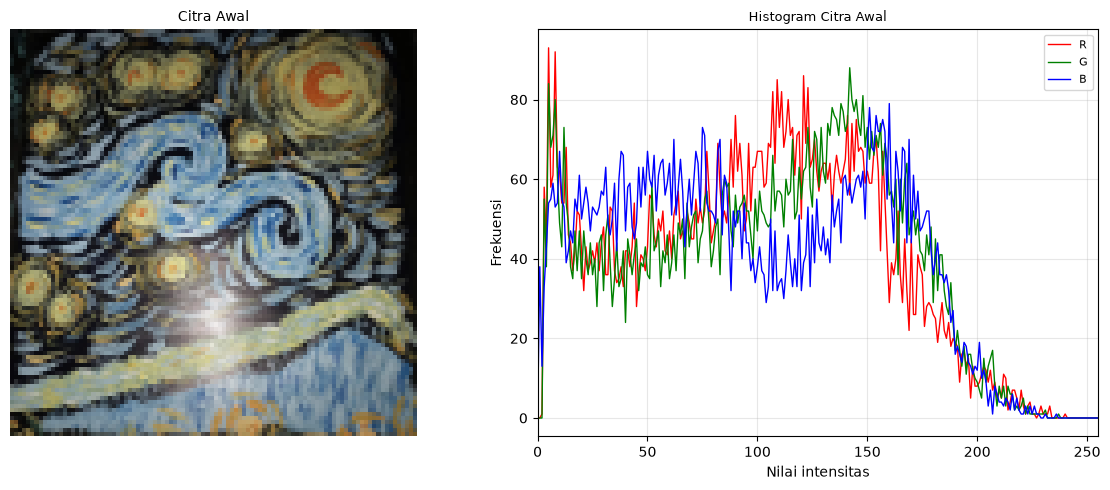


INFORMASI: Citra Awal
Ukuran citra   : lebar 100 x tinggi 100 x 3 kanal
Nilai minimum  : 1
Nilai maksimum : 240

--- Citra Awal (100 x 100) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0         (12,16,17)     (13,15,17)        (4,8,8)     (18,22,21)     (10,12,11)     (18,18,16)
y=1         (11,14,15)     (13,17,18)     (12,19,20)     (21,31,28)     (11,13,12)        (9,9,7)
y=2            (4,7,8)     (10,16,17)     (14,22,24)      (9,16,15)        (8,9,8)        (9,9,7)
y=3            (5,6,6)     (11,17,17)     (18,27,28)     (17,24,22)        (8,9,8)        (6,6,6)
y=4            (4,5,5)     (10,15,15)     (34,52,50)     (15,24,23)        (8,9,9)        (6,6,6)
y=5            (5,8,7)      (8,12,11)     (36,55,54)     (30,41,43)        (8,9,9)        (7,9,8)

--- NILAI HISTOGRAM Citra Awal (nilai: jumlah piksel) ---
[R] 232 nilai berbeda, total 10000 piksel, puncak di 5 (93 piksel)
     2

In [5]:
info = baca_properti(FILE["tugas2"])
w, h = info["lebar"], info["tinggi"]            # w & h diambil dari PROPERTI citra
citra = baca_citra(FILE["tugas2"], "rgb")
print(f"w dari properti = {w}, h dari properti = {h} | ukuran matriks = {citra.shape[1]} x {citra.shape[0]}")

# CITRA AWAL + HISTOGRAM AWAL
tampil_awal(citra, "Citra Awal")

### Operasi 1 - Grayscale  `Ko = 0,299R + 0,587G + 0,114B`

Contoh piksel f(32,32) = (R=136, G=136, B=136)
Ko = 0.299*136 + 0.587*136 + 0.114*136 = 136.00 -> 136


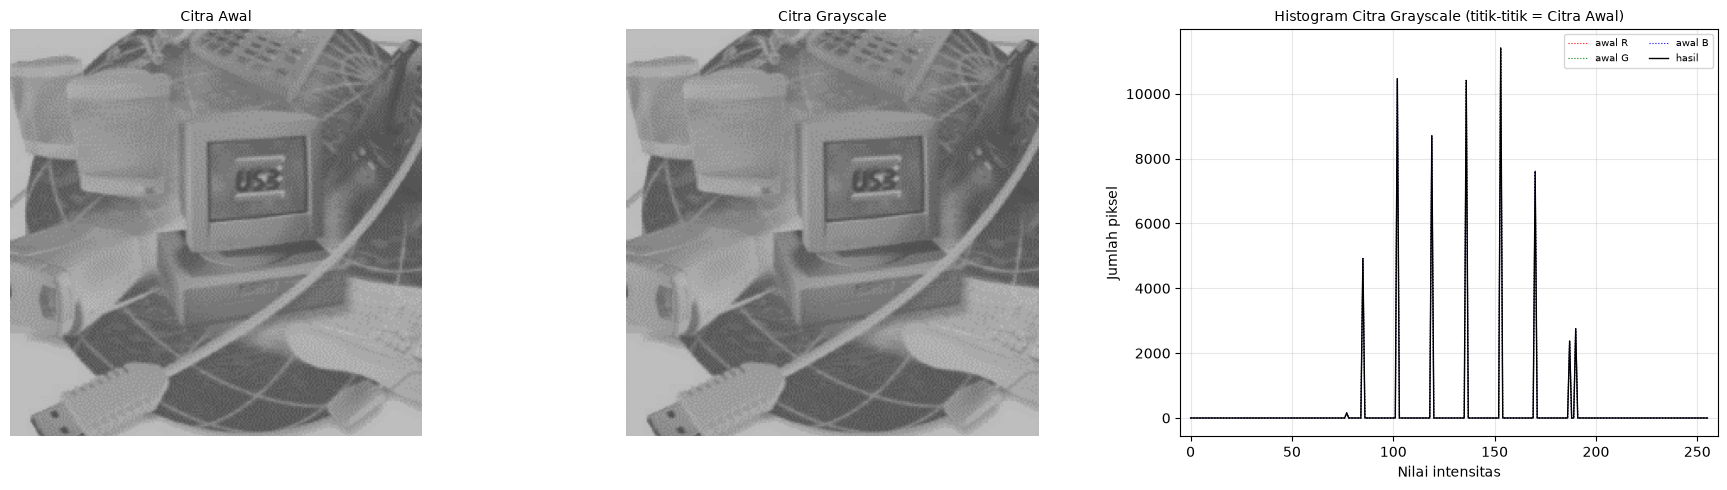


INFORMASI: Citra Awal
Ukuran citra   : lebar 244 x tinggi 241 x 3 kanal
Nilai minimum  : 77
Nilai maksimum : 190

INFORMASI: Citra Grayscale
Ukuran citra   : lebar 244 x tinggi 241 (1 kanal)
Nilai minimum  : 77
Nilai maksimum : 190

--- Citra Awal (244 x 241) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0      (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)
y=1      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=2      (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=3      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=4      (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=5      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)

--- Citra G

In [26]:
abu = grayscale(citra)
x0, y0 = w // 2, h // 2
R, G, B = (int(v) for v in citra[y0, x0])
print(f"Contoh piksel f({x0},{y0}) = (R={R}, G={G}, B={B})")
print(f"Ko = 0.299*{R} + 0.587*{G} + 0.114*{B} = {0.299*R + 0.587*G + 0.114*B:.2f} -> {abu[y0, x0]}")
tampil_operasi(citra, abu, "Citra Awal", "Citra Grayscale",
            txt=out("01_fungsi_grayscale.txt"), judul_txt="Grayscale Ko = 0.299R + 0.587G + 0.114B")

### Operasi 2 - Brightness  `Ko = Ki + C`  (histogram bergeser)

Contoh R di f(0,0): Ko = 187 + 60 = 247 -> 247 (di-clip bila > 255)


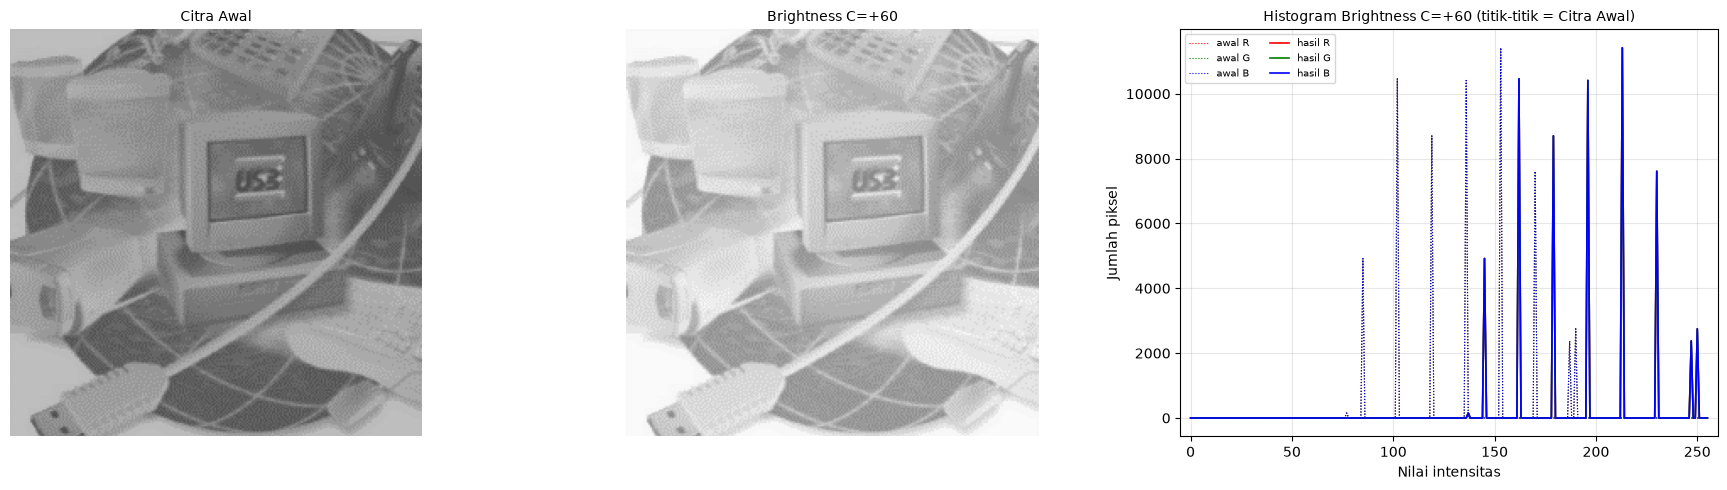


INFORMASI: Citra Awal
Ukuran citra   : lebar 244 x tinggi 241 x 3 kanal
Nilai minimum  : 77
Nilai maksimum : 190

INFORMASI: Brightness C=+60
Ukuran citra   : lebar 244 x tinggi 241 x 3 kanal
Nilai minimum  : 137
Nilai maksimum : 250

--- Citra Awal (244 x 241) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0      (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)
y=1      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=2      (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=3      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=4      (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=5      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)

--- Brigh

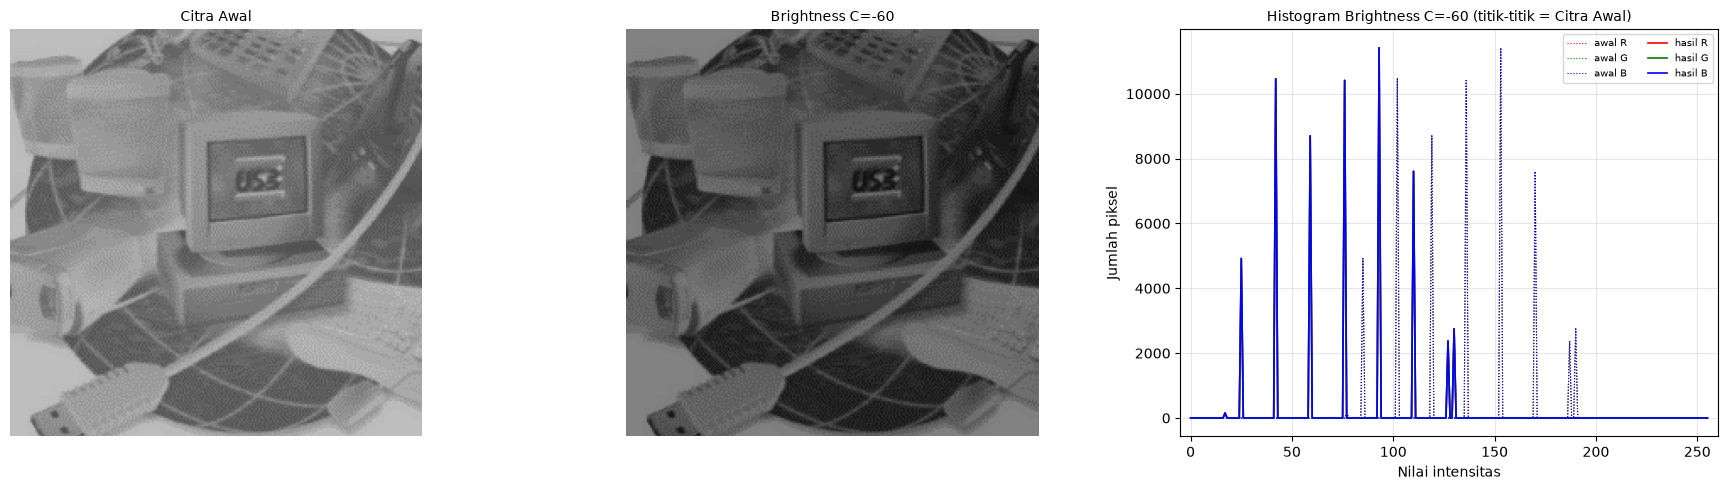


INFORMASI: Citra Awal
Ukuran citra   : lebar 244 x tinggi 241 x 3 kanal
Nilai minimum  : 77
Nilai maksimum : 190

INFORMASI: Brightness C=-60
Ukuran citra   : lebar 244 x tinggi 241 x 3 kanal
Nilai minimum  : 17
Nilai maksimum : 130

--- Citra Awal (244 x 241) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0      (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)
y=1      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=2      (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=3      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=4      (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=5      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)

--- Bright

In [27]:
C = 60
hasil_b = brightness(citra, C)
Ki = int(citra[0, 0, 0])
print(f"Contoh R di f(0,0): Ko = {Ki} + {C} = {Ki + C} -> {hasil_b[0, 0, 0]} (di-clip bila > 255)")
tampil_operasi(citra, hasil_b, "Citra Awal", f"Brightness C=+{C}",
            txt=out(f"02_fungsi_brightness_+{C}.txt"), judul_txt=f"Brightness Ko = Ki + {C}")
simpan_gambar(out(f"brightness_+{C}.png"), hasil_b)

hasil_g = brightness(citra, -C)
tampil_operasi(citra, hasil_g, "Citra Awal", f"Brightness C=-{C}",
            txt=out(f"02_fungsi_brightness_-{C}.txt"), judul_txt=f"Brightness Ko = Ki - {C}")
simpan_gambar(out(f"brightness_-{C}.png"), hasil_g)

### Operasi 3 - Contrast  `Ko = G(Ki − P) + P`  (histogram melebar / menyempit)


Contoh R di f(32,32): Ko = 1.8(136 - 128) + 128 = 142.4 -> 142


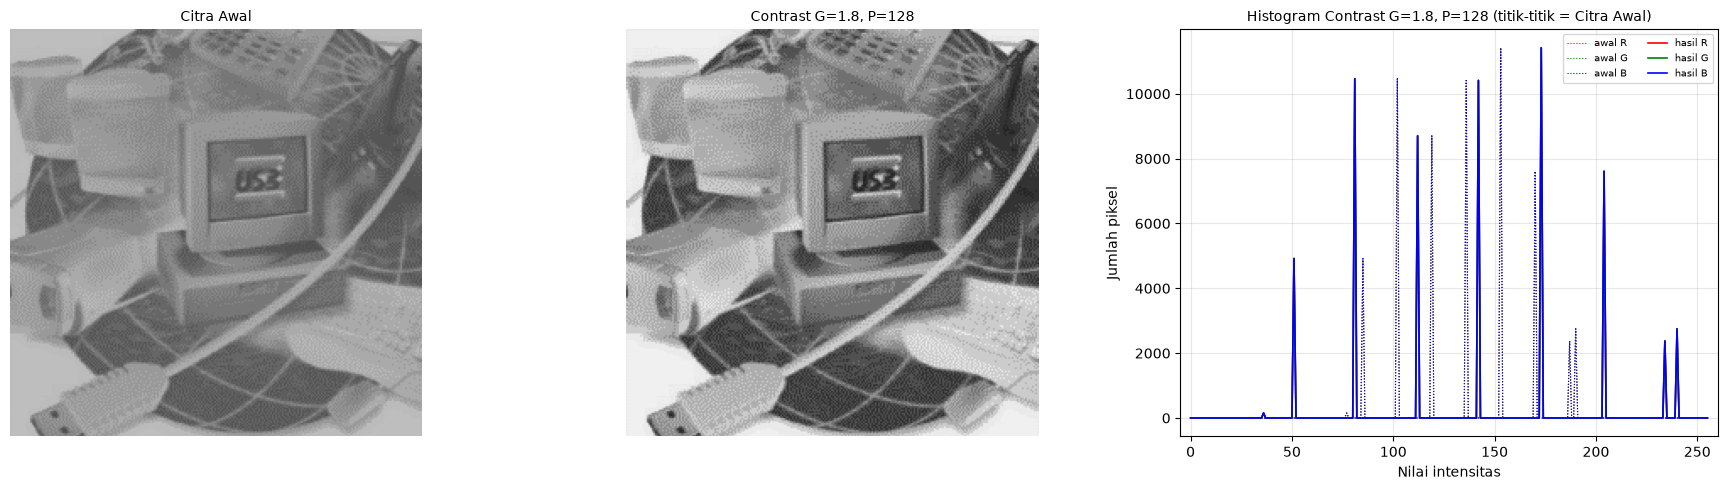


INFORMASI: Citra Awal
Ukuran citra   : lebar 244 x tinggi 241 x 3 kanal
Nilai minimum  : 77
Nilai maksimum : 190

INFORMASI: Contrast G=1.8, P=128
Ukuran citra   : lebar 244 x tinggi 241 x 3 kanal
Nilai minimum  : 36
Nilai maksimum : 240

--- Citra Awal (244 x 241) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0      (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)
y=1      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=2      (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=3      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=4      (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=5      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)

--- C

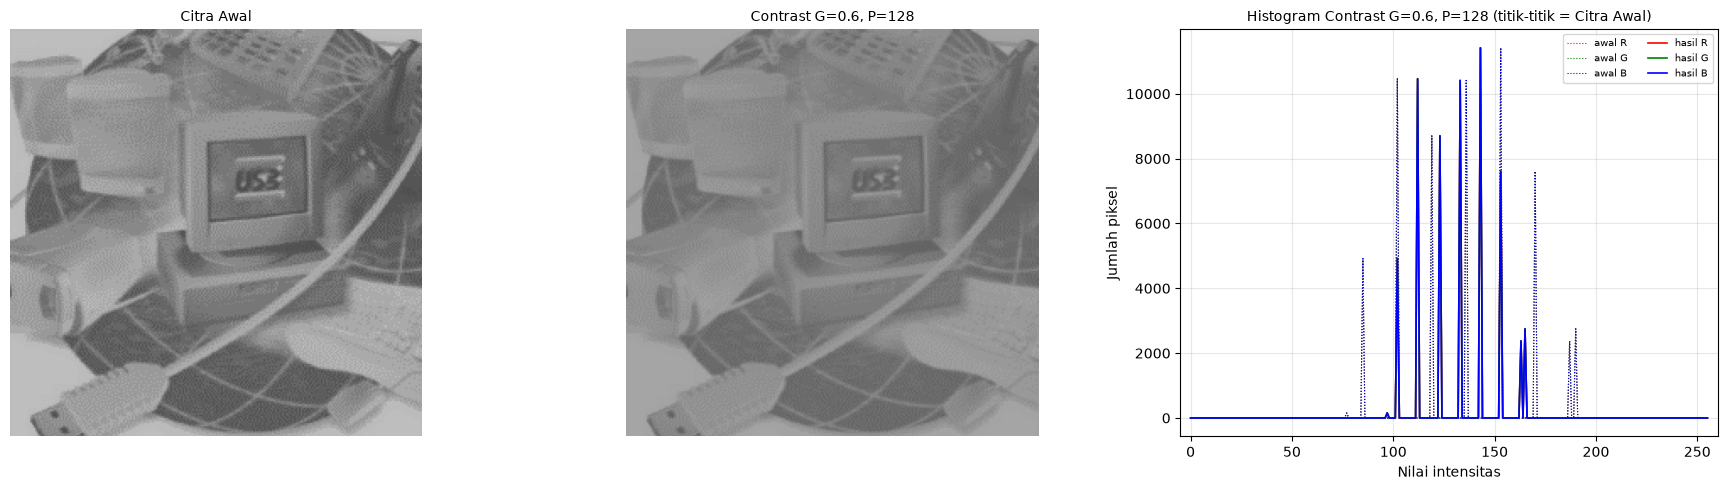


INFORMASI: Citra Awal
Ukuran citra   : lebar 244 x tinggi 241 x 3 kanal
Nilai minimum  : 77
Nilai maksimum : 190

INFORMASI: Contrast G=0.6, P=128
Ukuran citra   : lebar 244 x tinggi 241 x 3 kanal
Nilai minimum  : 97
Nilai maksimum : 165

--- Citra Awal (244 x 241) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0      (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)
y=1      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=2      (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=3      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=4      (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=5      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)

--- C

In [28]:
for G_ in (1.8, 0.6):
    hasil_c = contrast(citra, G=G_, P=128)
    Ki = int(citra[y0, x0, 0])
    print(f"\nContoh R di f({x0},{y0}): Ko = {G_}({Ki} - 128) + 128 = {G_ * (Ki - 128) + 128:.1f} -> {hasil_c[y0, x0, 0]}")
    tampil_operasi(citra, hasil_c, "Citra Awal", f"Contrast G={G_}, P=128",
                txt=out(f"03_fungsi_contrast_G{G_}.txt"), judul_txt=f"Contrast Ko = {G_}(Ki - 128) + 128")
    simpan_gambar(out(f"contrast_{G_}.png"), hasil_c)

### Negasi
Yang dicek: (1) properti awal vs hasil, (2) nilai R, G, B satu piksel sebelum & sesudah, (3) histogram hasil = histogram awal dibalik (`h_hasil[i] = h_awal[255−i]`), (4) rentang min–maks.

[Citra awal  ] resolusi 244 x 241 | kanal 3 | depth 24 bit/piksel | min 77 | max 190


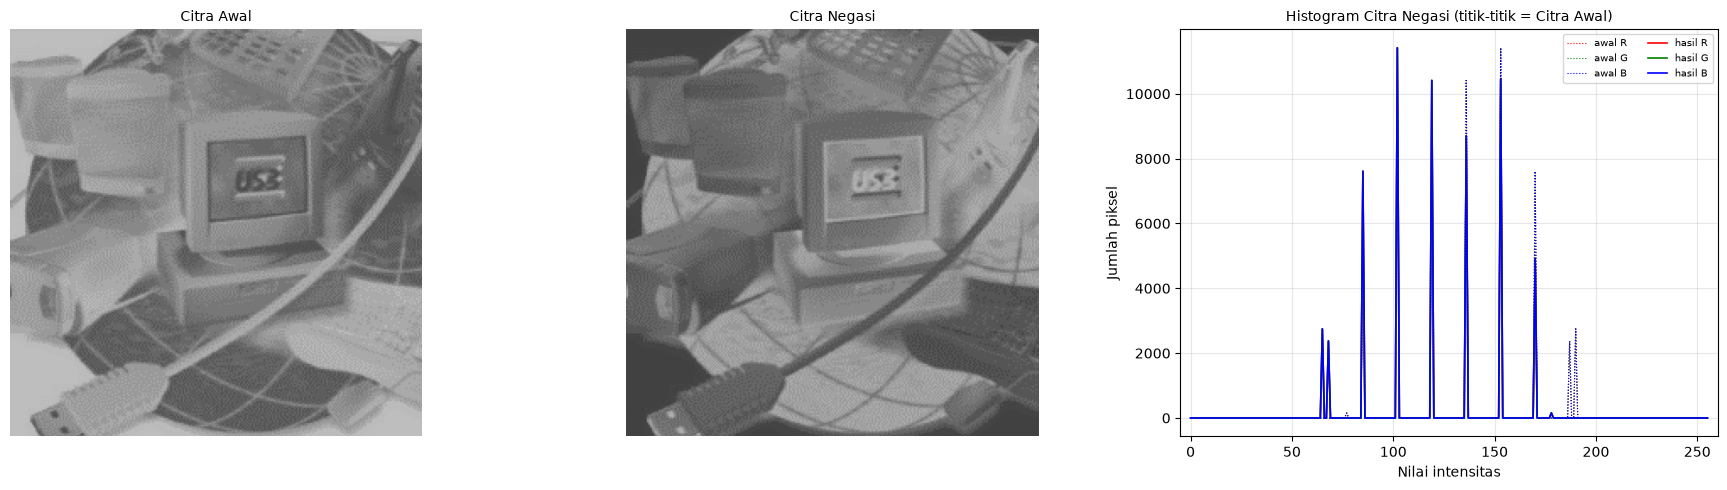


INFORMASI: Citra Awal
Ukuran citra   : lebar 244 x tinggi 241 x 3 kanal
Nilai minimum  : 77
Nilai maksimum : 190

INFORMASI: Citra Negasi
Ukuran citra   : lebar 244 x tinggi 241 x 3 kanal
Nilai minimum  : 65
Nilai maksimum : 178

--- Citra Awal (244 x 241) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0      (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)
y=1      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=2      (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=3      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=4      (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=5      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)

--- Citra Nega

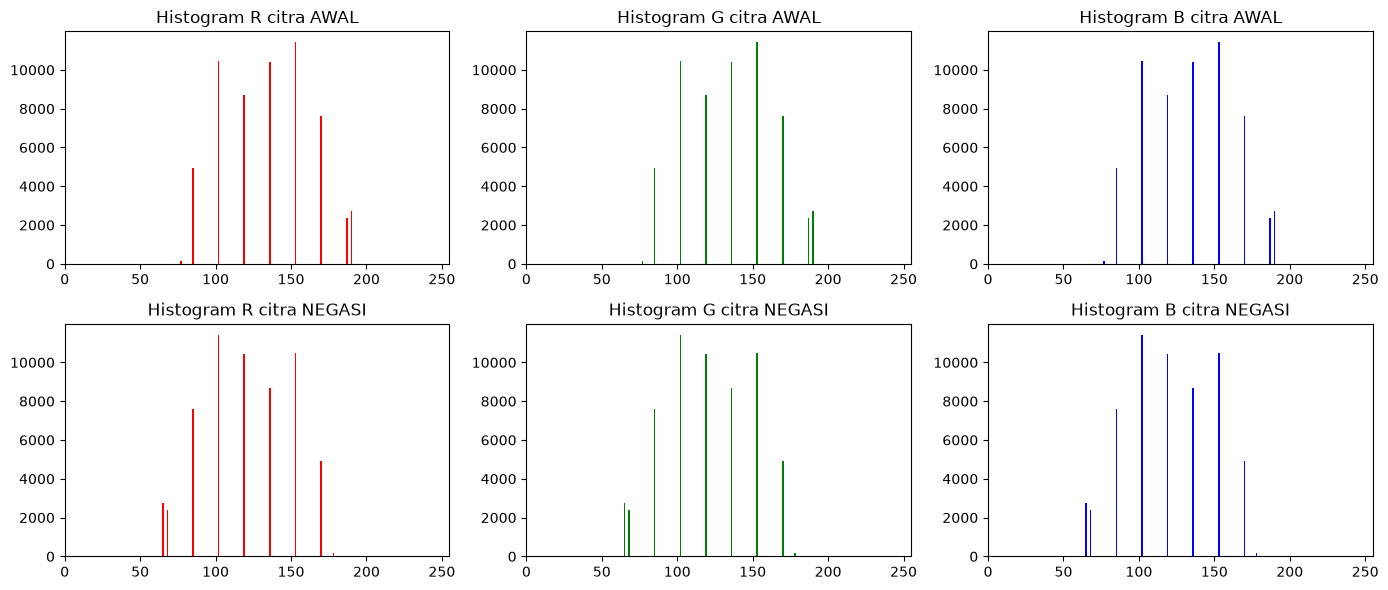

Gambar disimpan: hasil\negasi.png
[Citra awal  ] resolusi 244 x 241 | kanal 3 | depth 24 bit/piksel | min 77 | max 190
[Citra negasi] resolusi 244 x 241 | kanal 3 | depth 24 bit/piksel | min 65 | max 178

--- Nilai satu piksel f(x=0, y=0) ---
R: awal Ki = 187 -> hasil Ko =  68   (255 - 187 = 68)  OK
G: awal Ki = 187 -> hasil Ko =  68   (255 - 187 = 68)  OK
B: awal Ki = 187 -> hasil Ko =  68   (255 - 187 = 68)  OK

--- Histogram harus saling berkebalikan ---
R: h_hasil[i] == h_awal[255-i] untuk semua i -> OK | contoh: puncak awal di 153 (11417 piksel) -> di hasil pindah ke 102 (11417 piksel) | rentang awal [77..190] -> hasil [65..178]
G: h_hasil[i] == h_awal[255-i] untuk semua i -> OK | contoh: puncak awal di 153 (11417 piksel) -> di hasil pindah ke 102 (11417 piksel) | rentang awal [77..190] -> hasil [65..178]
B: h_hasil[i] == h_awal[255-i] untuk semua i -> OK | contoh: puncak awal di 153 (11417 piksel) -> di hasil pindah ke 102 (11417 piksel) | rentang awal [77..190] -> hasil [65..178

In [29]:
neg = negatif(citra)
properti_array(citra, "Citra awal  ")
tampil_operasi(citra, neg, "Citra Awal", "Citra Negasi",
            txt=out("04_fungsi_negatif.txt"), judul_txt="Negasi Ko = 255 - Ki")

# Histogram per kanal awal vs hasil, ditampilkan berdampingan supaya terlihat terbalik
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for k, warna in enumerate(["red", "green", "blue"]):
    ax[0, k].bar(np.arange(256), histogram(citra[:, :, k]), color=warna, width=1.0)
    ax[0, k].set_title(f"Histogram {'RGB'[k]} citra AWAL"); ax[0, k].set_xlim(0, 255)
    ax[1, k].bar(np.arange(256), histogram(neg[:, :, k]), color=warna, width=1.0)
    ax[1, k].set_title(f"Histogram {'RGB'[k]} citra NEGASI"); ax[1, k].set_xlim(0, 255)
plt.tight_layout(); plt.show()

simpan_gambar(out("negasi.png"), neg)
cek_negasi(citra, neg, titik=(0, 0))
cek_negasi(citra, neg, titik=(w // 2, h // 2))
simpan_ke_txt(out("negasi_matriks.txt"), "Negasi", [("citra awal", "Citra awal", citra), ("citra hasil", "Negasi", neg)])

### Thresholding - strategi pemilihan T
Rumus (pengambangan tunggal, buku): **Ko = 0 jika Ki < T ; Ko = 1 jika Ki ≥ T**.
Strategi: (1) lihat histogram dulu → di mana gumpalan gelap (objek/latar) dan terang; (2) **jangan 128** karena di tengah dan
hasilnya biasa saja; uji nilai **ekstrem** (mis. 30 dan 220) untuk melihat batas: T kecil → hampir semua putih, T besar → hampir semua hitam;
(3) pilih T di **lembah** histogram di antara dua puncak (atau otomatis: rata-rata / Otsu, lihat Tugas 7).

    T | % putih (Ki>=T) |  % hitam
   30 |         100.00% |    0.00%
   60 |         100.00% |    0.00%
  180 |           8.72% |   91.28%
  220 |           0.00% |  100.00%

T otomatis sederhana = rata-rata piksel = 135
Ki = 136, T = 30: 136 >= 30 -> Ko = 1
Ki = 136, T = 220: 136 < 220 -> Ko = 0


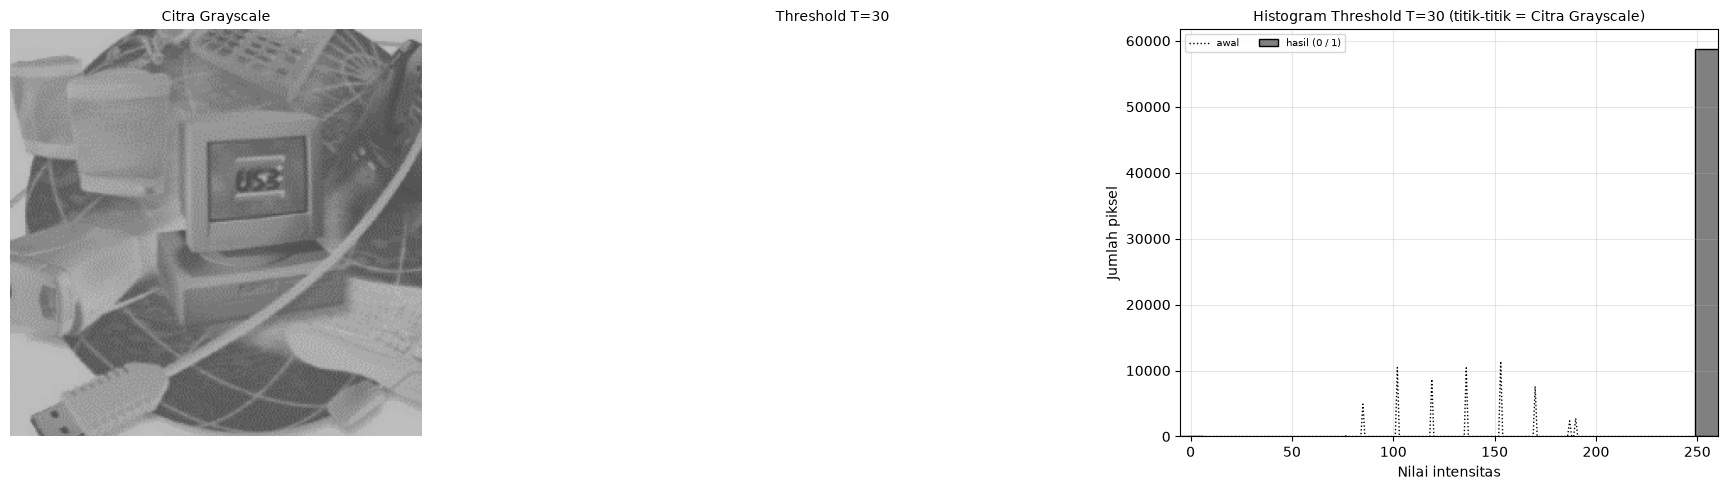


INFORMASI: Citra Grayscale
Ukuran citra   : lebar 244 x tinggi 241 (1 kanal)
Nilai minimum  : 77
Nilai maksimum : 190

INFORMASI: Threshold T=30
Ukuran citra   : lebar 244 x tinggi 241 (1 kanal)
Nilai minimum  : 1
Nilai maksimum : 1

--- Citra Grayscale (244 x 241) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0                187            187            187            187            187            187
y=1                187            190            190            190            190            190
y=2                190            190            190            190            190            190
y=3                187            190            190            190            190            190
y=4                190            190            190            190            190            190
y=5                187            190            190            190            190            190

--- T

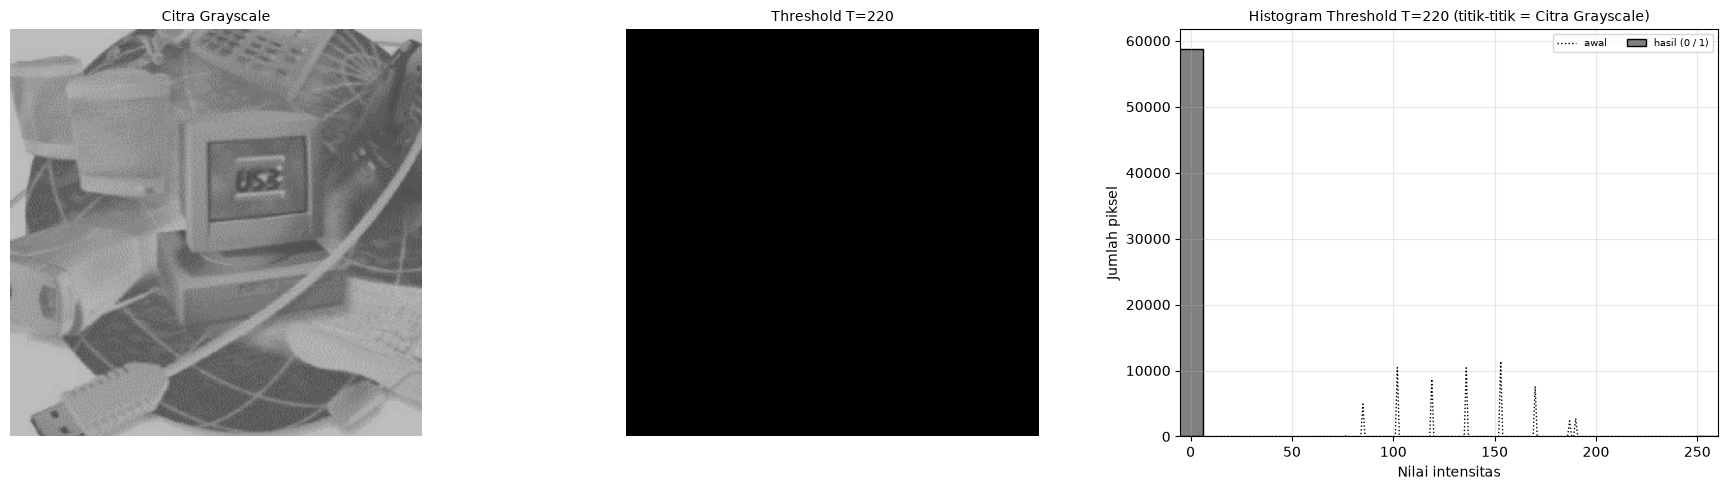


INFORMASI: Citra Grayscale
Ukuran citra   : lebar 244 x tinggi 241 (1 kanal)
Nilai minimum  : 77
Nilai maksimum : 190

INFORMASI: Threshold T=220
Ukuran citra   : lebar 244 x tinggi 241 (1 kanal)
Nilai minimum  : 0
Nilai maksimum : 0

--- Citra Grayscale (244 x 241) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0                187            187            187            187            187            187
y=1                187            190            190            190            190            190
y=2                190            190            190            190            190            190
y=3                187            190            190            190            190            190
y=4                190            190            190            190            190            190
y=5                187            190            190            190            190            190

--- 

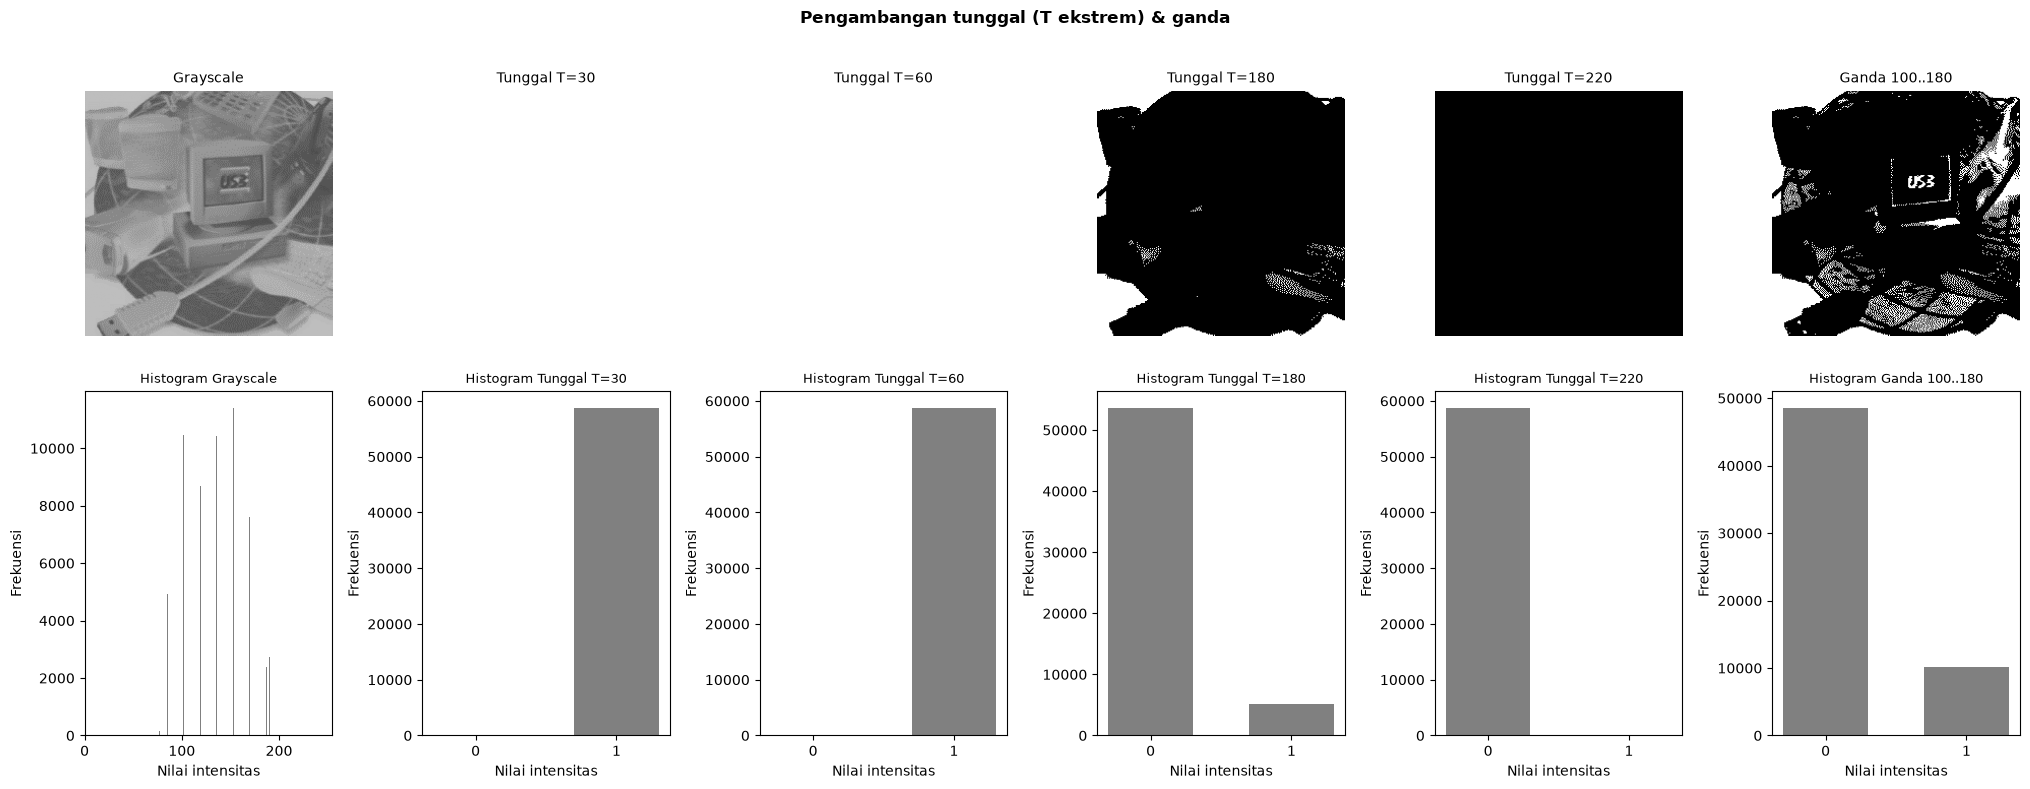


--- Grayscale (244 x 241) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0                187            187            187            187            187            187
y=1                187            190            190            190            190            190
y=2                190            190            190            190            190            190
y=3                187            190            190            190            190            190
y=4                190            190            190            190            190            190
y=5                187            190            190            190            190            190

--- Threshold T=30 (244 x 241) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0                  1              1              1              1        

In [30]:
ringkas_threshold(abu, [30, 60, 180, 220])
T_rata = threshold_rata_rata(abu)
print(f"\nT otomatis sederhana = rata-rata piksel = {T_rata}")

# Contoh hitung satu piksel
Ki = int(abu[y0, x0])
for T in (30, 220):
    print(f"Ki = {Ki}, T = {T}: {Ki} {'>=' if Ki >= T else '<'} {T} -> Ko = {1 if Ki >= T else 0}")

for T in (30, 220):
    tampil_operasi(abu, ambang_tunggal(abu, T), "Citra Grayscale", f"Threshold T={T}",
                txt=out(f"05_fungsi_threshold_T{T}.txt"), judul_txt=f"Threshold Ko = 0 jika Ki < {T}, 1 jika Ki >= {T}")

daftar = [("Grayscale", abu)]
for T in (30, 60, 180, 220):
    daftar.append((f"Tunggal T={T}", ambang_tunggal(abu, T)))
daftar.append(("Ganda 100..180", ambang_ganda(abu, 100, 180)))
tampil_citra_hist(daftar, "Pengambangan tunggal (T ekstrem) & ganda", lebar_kolom=3.4)
cetak_nilai([("Grayscale", abu), ("Threshold T=30", ambang_tunggal(abu, 30)), ("Threshold T=220", ambang_tunggal(abu, 220))])
for T in (60, 180):
    tulis_sebelum_sesudah(out(f"05_fungsi_threshold_T{T}.txt"), f"Threshold Ko = 0 jika Ki < {T}, 1 jika Ki >= {T}",
                        abu, ambang_tunggal(abu, T))
simpan_ke_txt(out("threshold_tugas2.txt"), "Threshold (0/1)",
            [("citra asli", "Grayscale", abu), ("citra hasil", "Tunggal T=180", ambang_tunggal(abu, 180))])

## Tugas 3 - Operasi geometri
| Operasi | Rumus |
|---|---|
| Cermin horizontal | x' = w − 1 − x, y' = y |
| Cermin vertikal | y' = h − 1 − y, x' = x |
| Rotasi 90° CW | w' = h, h' = w, x' = w' − 1 − y, y' = x |
| Rotasi 180° | x' = w − 1 − x, y' = h − 1 − y |
| Rotasi bebas (CCW) | x' = x cos θ + y sin θ, y' = −x sin θ + y cos θ, w' = \|w cos θ\| + \|h sin θ\|, h' = \|w sin θ\| + \|h cos θ\| |
| Cropping | x' = x − xL, y' = y − yT, w' = xR − xL, h' = yB − yT |
| Scaling | x' = Sh·x, y' = Sv·y, w' = Sh·w, h' = Sv·h |

Nama file      : image_rgb_1.bmp
Format         : BMP
Resolusi       : 64 x 64 piksel (lebar w x tinggi h)
Jumlah piksel  : 4,096
Depth color    : 24 bit/piksel
Jumlah warna   : 2^24 = 16,777,216
Memori data    : 64 x 64 x 24 bit = 12,288 byte (12.0 KB)
Ukuran file    : 12,342 byte
Resolusi cetak : 72 dpi
Titik (x=10, y=3) pada citra 64 x 64:
  cermin horizontal -> (53, 3)
  cermin vertikal   -> (10, 60)
  rotasi 90 CW      -> x' = w'-1-y = 64-1-3 = 60, y' = x = 10
  rotasi 180        -> (53, 60)
  rotasi bebas 25 CCW: w' = |64cos25|+|64sin25| = 85.1, h' = |64sin25|+|64cos25| = 85.1
Gambar disimpan: hasil\citra_asli.png
Gambar disimpan: hasil\pencerminan_horizontal.png
Gambar disimpan: hasil\pencerminan_vertikal.png
Gambar disimpan: hasil\pencerminan_kombinasi.png
Gambar disimpan: hasil\rotasi_90_cw.png
Gambar disimpan: hasil\rotasi_90_ccw.png
Gambar disimpan: hasil\rotasi_180.png
Gambar disimpan: hasil\rotasi_bebas_25_ccw.png
Gambar disimpan: hasil\rotasi_bebas_25_cw.png
Gambar disimp

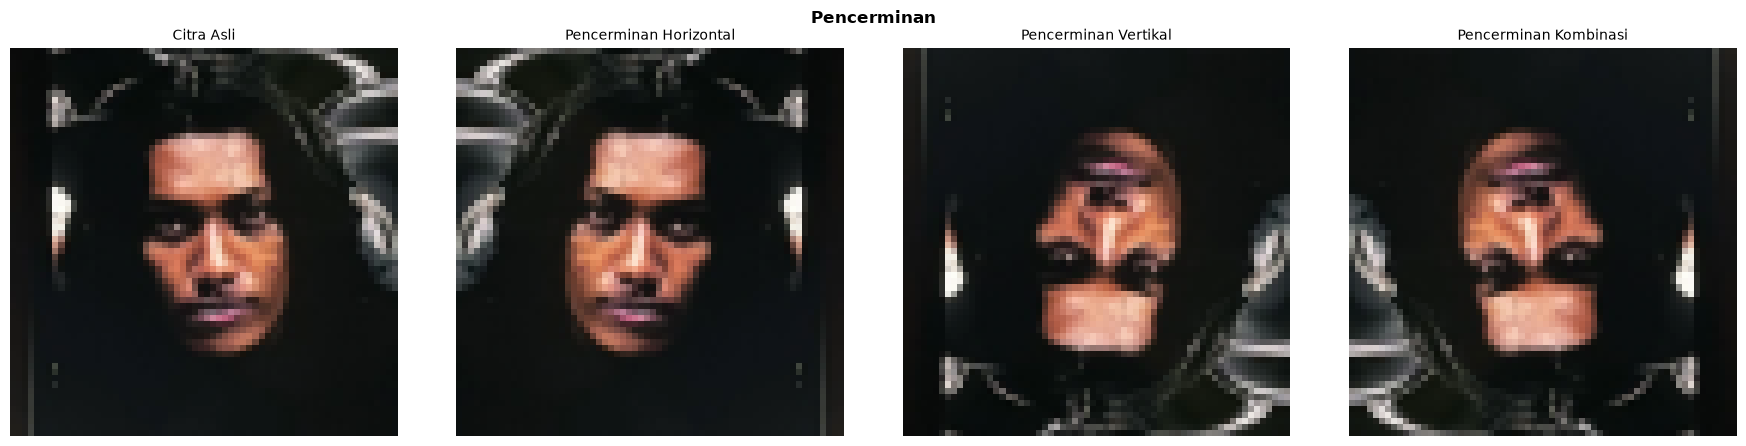

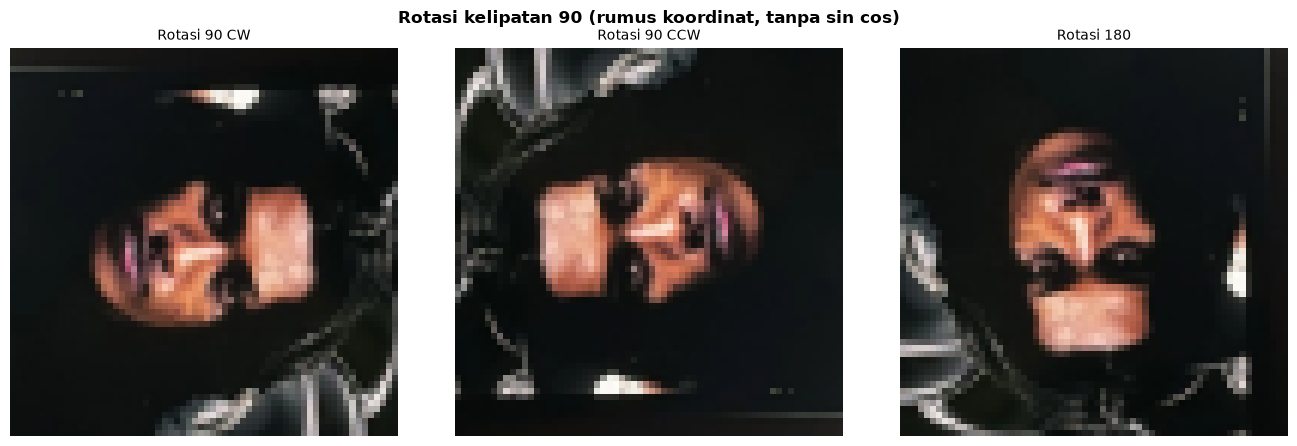

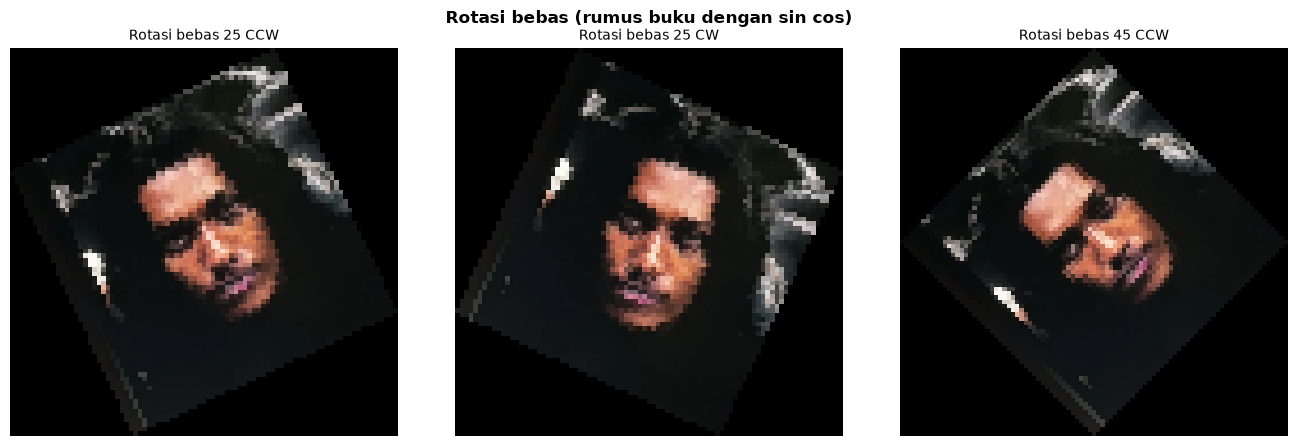

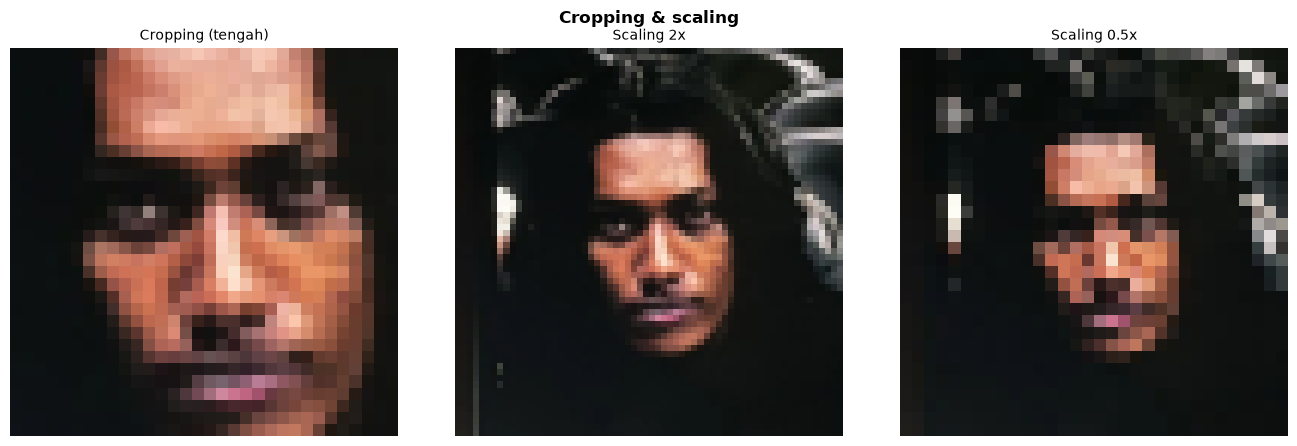

Citra Asli              : 64 x 64
Pencerminan Horizontal  : 64 x 64
Pencerminan Vertikal    : 64 x 64
Pencerminan Kombinasi   : 64 x 64
Rotasi 90 CW            : 64 x 64
Rotasi 90 CCW           : 64 x 64
Rotasi 180              : 64 x 64
Rotasi bebas 25 CCW     : 85 x 85
Rotasi bebas 25 CW      : 85 x 85
Rotasi bebas 45 CCW     : 91 x 91
Cropping (tengah)       : 32 x 32
Scaling 2x              : 128 x 128
Scaling 0.5x            : 32 x 32

rotasi_bebas(90, cw) == rotasi_90_cw : True
rotasi_bebas(180)    == rotasi_180   : True
Matriks piksel disimpan: hasil\hasil_operasi_geometri.txt
Nilai sebelum & sesudah disimpan: hasil\geo_pencerminan_horizontal.txt
Nilai sebelum & sesudah disimpan: hasil\geo_pencerminan_vertikal.txt
Nilai sebelum & sesudah disimpan: hasil\geo_pencerminan_kombinasi.txt
Nilai sebelum & sesudah disimpan: hasil\geo_rotasi_90_cw.txt
Nilai sebelum & sesudah disimpan: hasil\geo_rotasi_90_ccw.txt
Nilai sebelum & sesudah disimpan: hasil\geo_rotasi_180.txt
Nilai sebelum & s

In [31]:
info = baca_properti(FILE["geometri"])
w, h = info["lebar"], info["tinggi"]
citra_asli = baca_citra(FILE["geometri"], "rgb")

# Contoh perpindahan satu titik (bagus untuk dijelaskan saat demo)
x, y = 10, 3
print(f"Titik (x={x}, y={y}) pada citra {w} x {h}:")
print(f"  cermin horizontal -> ({w - 1 - x}, {y})")
print(f"  cermin vertikal   -> ({x}, {h - 1 - y})")
print(f"  rotasi 90 CW      -> x' = w'-1-y = {h}-1-{y} = {h - 1 - y}, y' = x = {x}")
print(f"  rotasi 180        -> ({w - 1 - x}, {h - 1 - y})")
t = math.radians(25)
print(f"  rotasi bebas 25 CCW: w' = |{w}cos25|+|{h}sin25| = {abs(w*math.cos(t)) + abs(h*math.sin(t)):.1f}, "
    f"h' = |{w}sin25|+|{h}cos25| = {abs(w*math.sin(t)) + abs(h*math.cos(t)):.1f}")

hasil_geo = [
    ("Citra Asli", citra_asli),
    ("Pencerminan Horizontal", pencerminan_horizontal(citra_asli)),
    ("Pencerminan Vertikal", pencerminan_vertikal(citra_asli)),
    ("Pencerminan Kombinasi", pencerminan_kombinasi(citra_asli)),
    ("Rotasi 90 CW", rotasi_90_cw(citra_asli)),
    ("Rotasi 90 CCW", rotasi_90_ccw(citra_asli)),
    ("Rotasi 180", rotasi_180(citra_asli)),
    ("Rotasi bebas 25 CCW", rotasi_bebas(citra_asli, 25, "ccw")),
    ("Rotasi bebas 25 CW", rotasi_bebas(citra_asli, 25, "cw")),
    ("Rotasi bebas 45 CCW", rotasi_bebas(citra_asli, 45, "ccw")),
    ("Cropping (tengah)", cropping(citra_asli, w // 4, h // 4, 3 * w // 4, 3 * h // 4)),
    ("Scaling 2x", scaling(citra_asli, 2, 2)),
    ("Scaling 0.5x", scaling(citra_asli, 0.5, 0.5)),
]
for judul, c in hasil_geo:
    simpan_gambar(out(judul.lower().replace(" ", "_") + ".png"), c)
tampil_citra_saja(hasil_geo[:4], "Pencerminan")
tampil_citra_saja(hasil_geo[4:7], "Rotasi kelipatan 90 (rumus koordinat, tanpa sin cos)")
tampil_citra_saja(hasil_geo[7:10], "Rotasi bebas (rumus buku dengan sin cos)")
tampil_citra_saja(hasil_geo[10:], "Cropping & scaling")
for judul, c in hasil_geo:
    print(f"{judul:<24}: {c.shape[1]} x {c.shape[0]}")

# Bukti: rotasi bebas 90/180 = hasil rumus tanpa sin cos
print("\nrotasi_bebas(90, cw) == rotasi_90_cw :", np.array_equal(rotasi_bebas(citra_asli, 90, "cw"), rotasi_90_cw(citra_asli)))
print("rotasi_bebas(180)    == rotasi_180   :", np.array_equal(rotasi_bebas(citra_asli, 180), rotasi_180(citra_asli)))
simpan_ke_txt(out("hasil_operasi_geometri.txt"), "Operasi Geometri",
            [("citra asli" if j == "Citra Asli" else "citra hasil", j, c) for j, c in hasil_geo])
for j, c in hasil_geo[1:]:
    tulis_sebelum_sesudah(out("geo_" + j.lower().replace(" ", "_").replace("(", "").replace(")", "") + ".txt"), j, citra_asli, c)
cetak_nilai([("Citra asli", citra_asli), ("Rotasi 90 CW", hasil_geo[4][1]), ("Rotasi 180", hasil_geo[6][1])], n=4)
cetak_nilai([("Citra asli pojok kanan atas", citra_asli)], n=4, x0=w - 4)

### Tugas 3B - Potong di titik tengah → putar bagian 1 → gabung dengan bagian 2
Arahan dosen (papan tulis): citra **1000 × 500**, dipotong **mendatar di tengah tinggi** (garis putus-putus, y = 500 / 2 = 250).
Bagian atas = baris 0..249, bagian bawah = baris 250..499. Bagian atas diputar 90°, lalu digabung dengan bagian bawah
sehingga bentuknya seperti huruf **L**. Posisi tempelan bisa **kiri, tengah, atau kanan**.

**Genap vs ganjil:** titik tengah = `ukuran // 2` (dibulatkan ke bawah).
- Genap (500): tengah 250 → 250 baris + 250 baris (sama besar).
- Ganjil (501): tengah 250 → 250 baris + **251** baris (baris tengah ikut bagian kedua).

In [32]:
# 1) Matriks kecil supaya jelas genap vs ganjil
for nama, m in (("GENAP (lebar 6)", np.arange(1, 25).reshape(4, 6)), ("GANJIL (lebar 7)", np.arange(1, 29).reshape(4, 7))):
    kiri, kanan, t = potong(m, "vertikal")
    print(f"\n{nama}: titik tengah = {m.shape[1]} // 2 = {t}")
    print("bagian 1 (kolom 0..%d):\n%s" % (t - 1, kiri))
    print("bagian 2 (kolom %d..%d):\n%s" % (t, m.shape[1] - 1, kanan))


GENAP (lebar 6): titik tengah = 6 // 2 = 3
bagian 1 (kolom 0..2):
[[ 1  2  3]
 [ 7  8  9]
 [13 14 15]
 [19 20 21]]
bagian 2 (kolom 3..5):
[[ 4  5  6]
 [10 11 12]
 [16 17 18]
 [22 23 24]]

GANJIL (lebar 7): titik tengah = 7 // 2 = 3
bagian 1 (kolom 0..2):
[[ 1  2  3]
 [ 8  9 10]
 [15 16 17]
 [22 23 24]]
bagian 2 (kolom 3..6):
[[ 4  5  6  7]
 [11 12 13 14]
 [18 19 20 21]
 [25 26 27 28]]


Ukuran contoh: 1000 x 500
Citra asal       : w = 1000, h = 500
Potong horizontal: di y = 250 (GENAP)
Bagian 1         : 1000 x 250   Bagian 2: 1000 x 250
Bagian 1 di-'90cw' -> 250 x 1000
Hasil gabung     : 1000 x 1250 (A di atas, rata kiri)


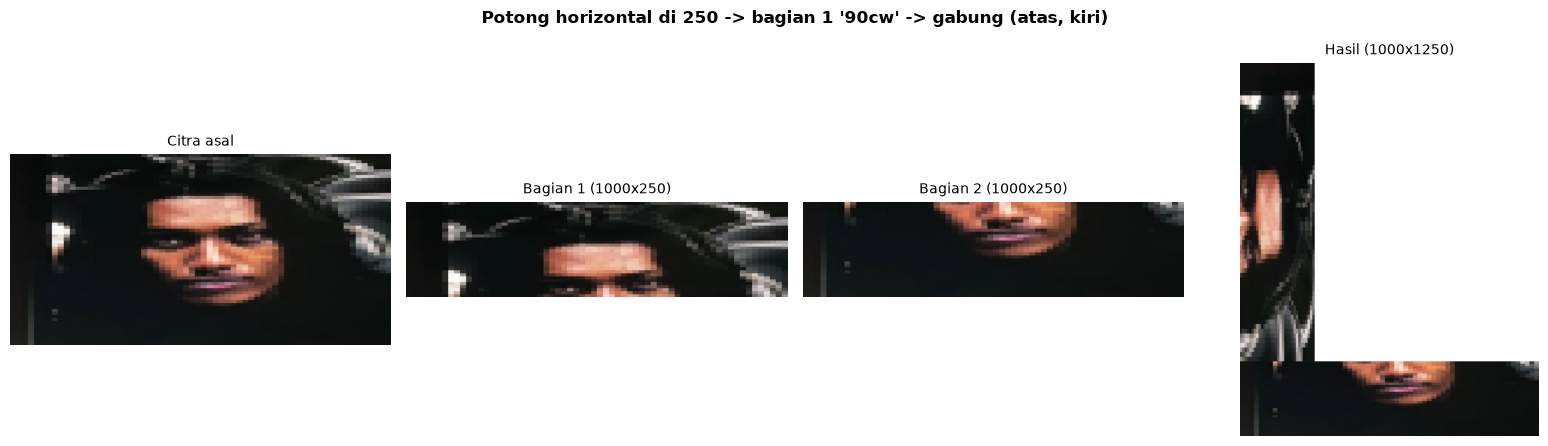

Gambar disimpan: hasil\potong_L_kiri.png
Matriks piksel disimpan: hasil\potong_putar_gabung_L.txt
Citra asal       : w = 1000, h = 500
Potong horizontal: di y = 250 (GENAP)
Bagian 1         : 1000 x 250   Bagian 2: 1000 x 250
Bagian 1 di-'90cw' -> 250 x 1000
Hasil gabung     : 1000 x 1250 (A di atas, rata tengah)
Citra asal       : w = 1000, h = 500
Potong horizontal: di y = 250 (GENAP)
Bagian 1         : 1000 x 250   Bagian 2: 1000 x 250
Bagian 1 di-'90cw' -> 250 x 1000
Hasil gabung     : 1000 x 1250 (A di atas, rata kanan)


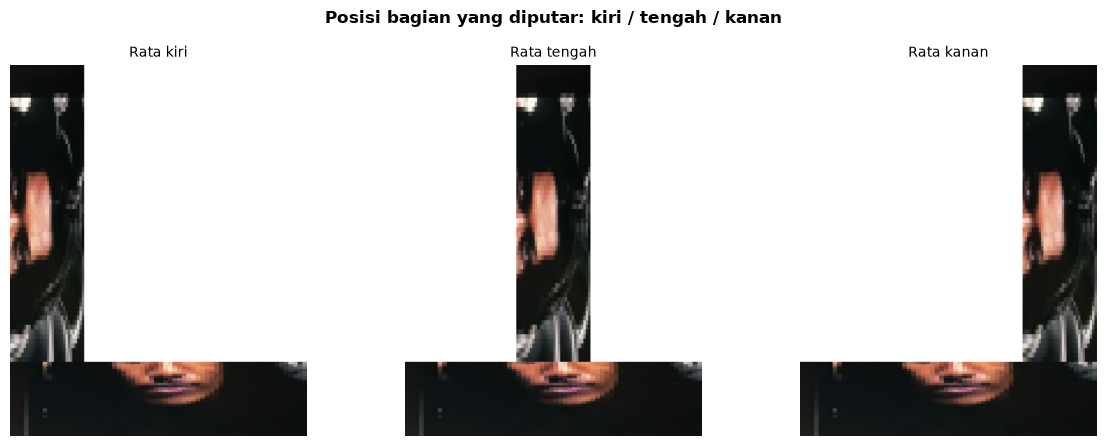

In [33]:
# 2) Seperti contoh papan tulis: citra 1000 x 500 (dibuat dari citra asli dengan rumus scaling)
info = baca_properti(FILE["geometri"], cetak=False)
contoh = scaling(citra_asli, 1000 / info["lebar"], 500 / info["tinggi"])
print("Ukuran contoh:", contoh.shape[1], "x", contoh.shape[0])

# potong mendatar di tengah tinggi, bagian ATAS diputar 90 CW, ditaruh DI ATAS bagian bawah, rata KIRI -> huruf L
b1, b2, L_kiri = potong_putar_gabung(contoh, arah="horizontal", bagian_diputar=1, cara_putar="90cw",
                                    letak="atas", rata="kiri")
simpan_gambar(out("potong_L_kiri.png"), L_kiri)
simpan_ke_txt(out("potong_putar_gabung_L.txt"), "Potong -> putar -> gabung (bentuk L)",
            [("citra hasil", "Bagian 1", b1), ("citra hasil", "Bagian 2", b2), ("citra hasil", "Gabungan L", L_kiri)])

# variasi posisi: tengah & kanan
_, _, L_tengah = potong_putar_gabung(contoh, "horizontal", None, 1, "90cw", "atas", "tengah", tampil=False)
_, _, L_kanan  = potong_putar_gabung(contoh, "horizontal", None, 1, "90cw", "atas", "kanan", tampil=False)
tampil_citra_saja([("Rata kiri", L_kiri), ("Rata tengah", L_tengah), ("Rata kanan", L_kanan)],
                "Posisi bagian yang diputar: kiri / tengah / kanan", lebar_kolom=4)

Citra asal       : w = 64, h = 64
Potong vertikal  : di x = 32 (GENAP)
Bagian 1         : 32 x 64   Bagian 2: 32 x 64
Bagian 1 di-'90cw' -> 64 x 32
Hasil gabung     : 96 x 64 (A di kiri, rata atas)


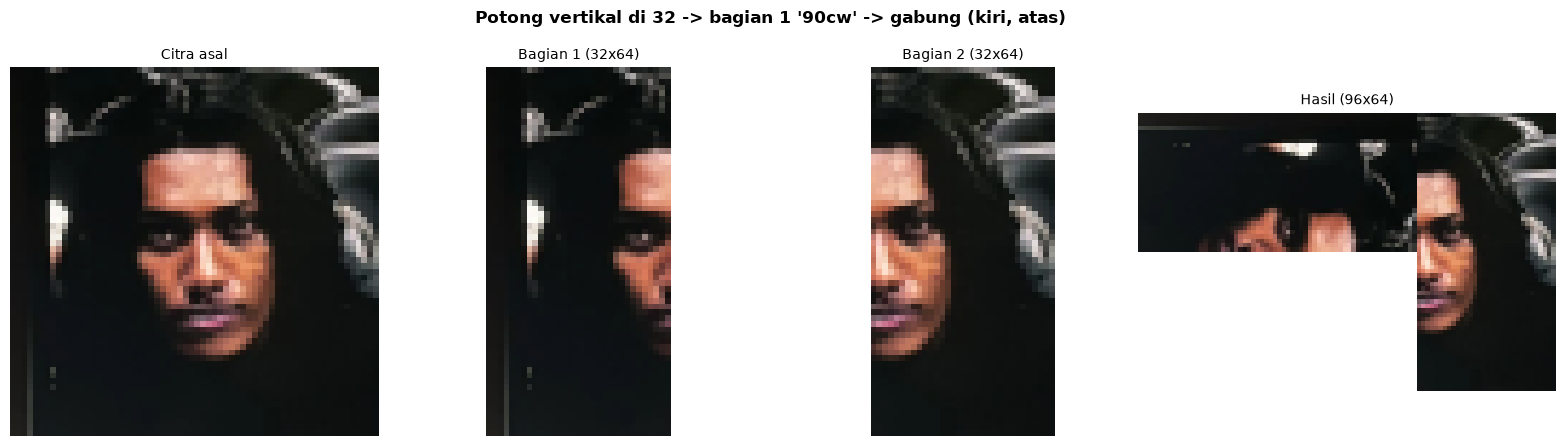

Gambar disimpan: hasil\potong_vertikal_gabung.png
Matriks piksel disimpan: hasil\potong_vertikal_gabung.txt
Citra asal       : w = 63, h = 64
Potong vertikal  : di x = 31 (GANJIL)
Bagian 1         : 31 x 64   Bagian 2: 32 x 64
Bagian 1 di-'90cw' -> 64 x 31
Hasil gabung     : 96 x 64 (A di kiri, rata atas)


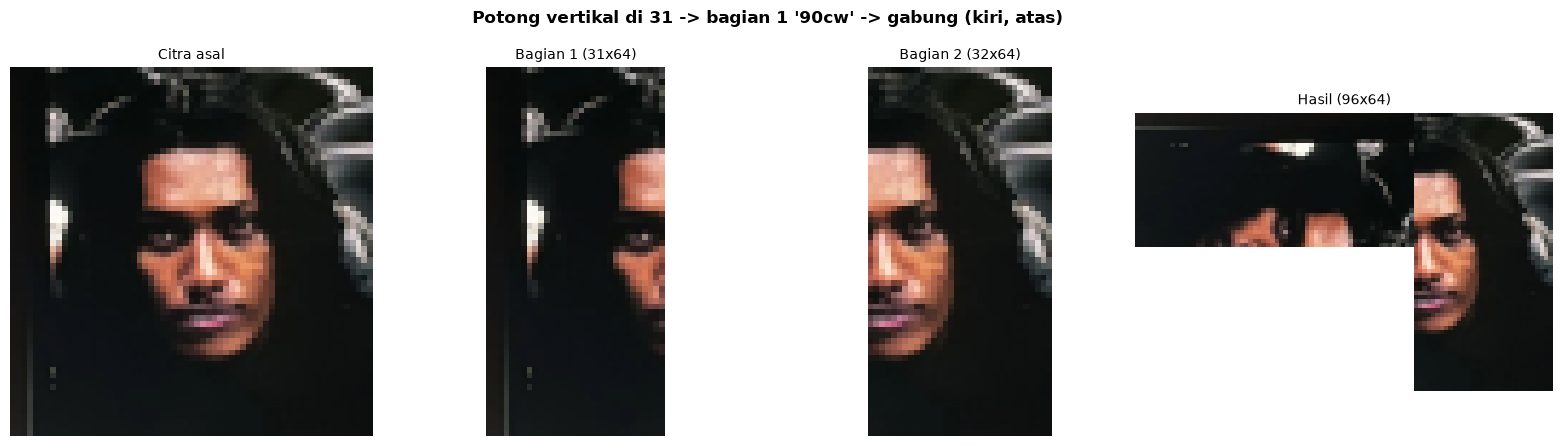

In [ ]:
# 3) Versi potong VERTIKAL di tengah lebar (kiri | kanan) pada citra asli,
#    bagian 1 (kiri) diputar 90 CW lalu ditempel di kiri bagian 2.
#    Karena rasionya sama (citra persegi), hasil gabung rapi tanpa sisa.
b1, b2, gabung_v = potong_putar_gabung(citra_asli, arah="vertikal", bagian_diputar=1,
                                    cara_putar="90cw", letak="kiri", rata="atas")
simpan_gambar(out("potong_vertikal_gabung.png"), gabung_v)
simpan_ke_txt(out("potong_vertikal_gabung.txt"), "Potong vertikal -> putar bagian 1 -> gabung",
            [("citra asli", "Citra asli", citra_asli), ("citra hasil", "Bagian 1", b1), ("citra hasil", "Bagian 2", b2),
            ("citra hasil", "Gabungan", gabung_v)])

# 4) Uji lebar GANJIL pada citra: potong 1 kolom dari kanan supaya lebarnya ganjil
ganjil = cropping(citra_asli, 0, 0, citra_asli.shape[1] - 1, citra_asli.shape[0])
_ = potong_putar_gabung(ganjil, arah="vertikal", cara_putar="90cw", letak="kiri", rata="atas")

## Tugas 4 - Operasi multi image: blending, deteksi gerakan, logika
Citra B disamakan ukurannya dengan A memakai rumus scaling (bukan `resize`).

Contoh R di (0,0): C = 0.4*176 + 0.6*150 = 160.4 -> 160


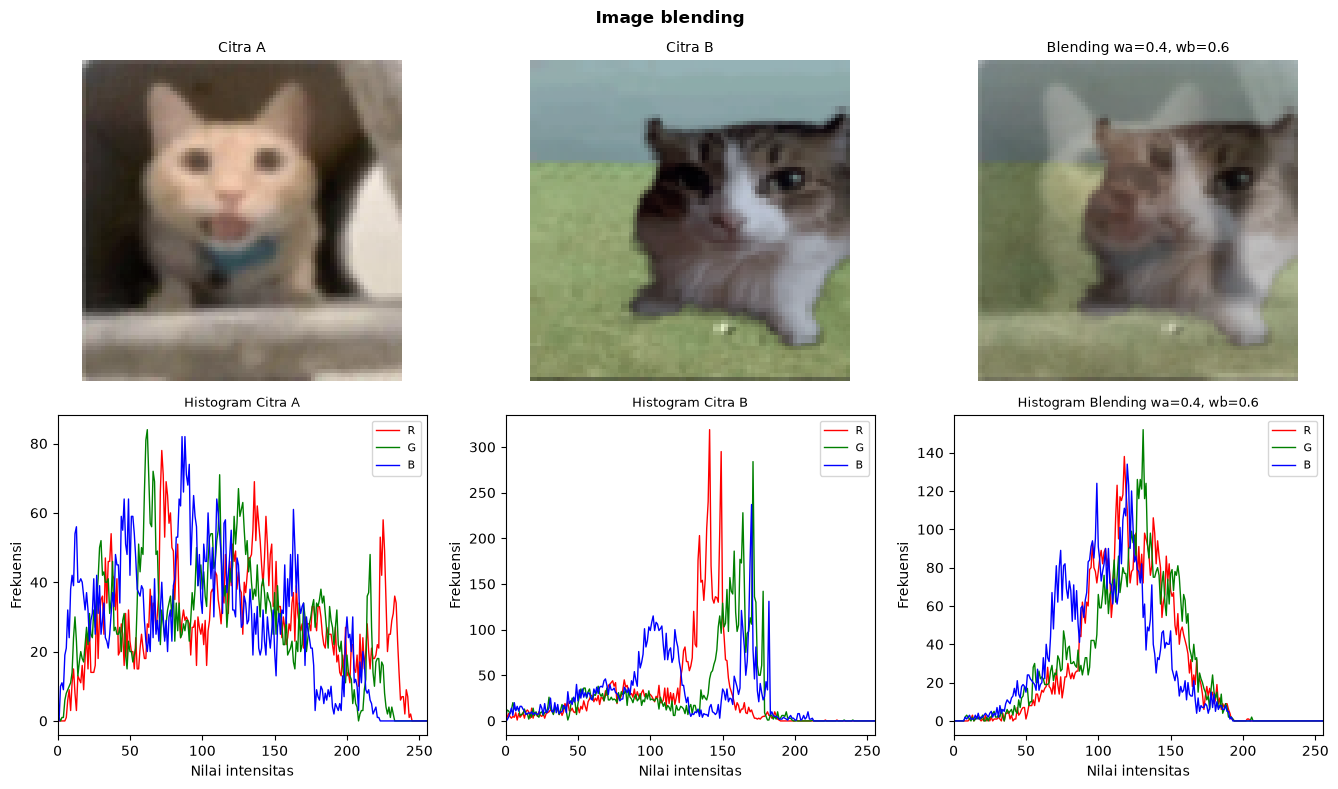

Gambar disimpan: hasil\hasil_blending.png

--- Citra A (84 x 84) | nilai f(x,y) untuk x=0..3, y=0..3 ---
                    x=0            x=1            x=2            x=3
y=0      (176,176,176)  (142,142,142)  (107,107,107)     (90,90,89)
y=1      (139,139,139)  (108,108,107)     (86,87,83)     (78,76,72)
y=2      (105,105,105)     (79,79,78)     (74,74,70)     (75,72,67)
y=3         (96,96,96)     (73,73,73)     (72,70,70)     (73,69,68)

--- Citra B (84 x 84) | nilai f(x,y) untuk x=0..3, y=0..3 ---
                    x=0            x=1            x=2            x=3
y=0      (150,165,169)  (150,165,169)  (149,165,170)  (148,167,173)
y=1      (150,165,169)  (150,165,169)  (149,165,170)  (148,167,173)
y=2      (149,169,172)  (149,169,172)  (148,169,173)  (148,171,175)
y=3      (149,172,173)  (149,172,173)  (147,172,174)  (147,172,174)

--- Blending (84 x 84) | nilai f(x,y) untuk x=0..3, y=0..3 ---
                    x=0            x=1            x=2            x=3
y=0      (160,169

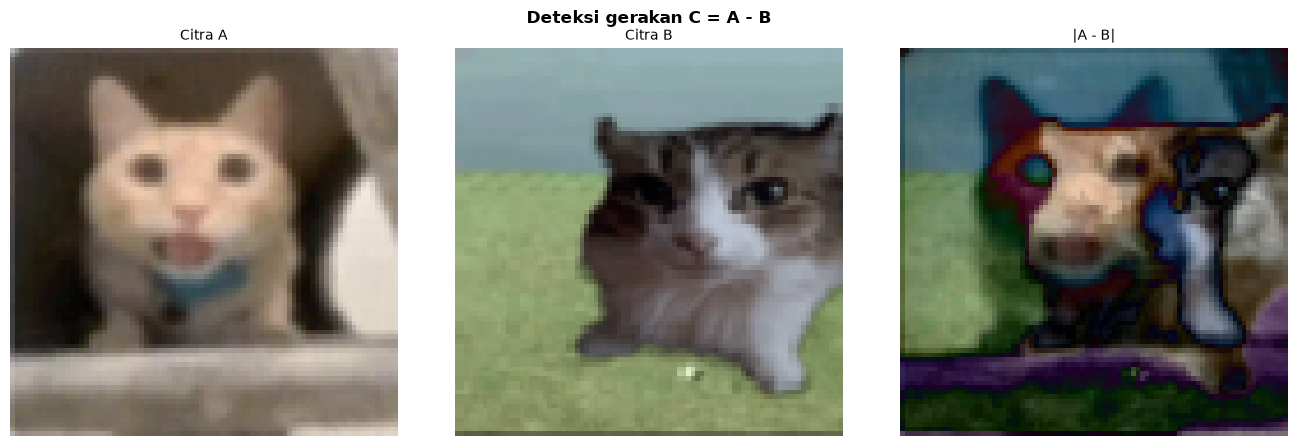

Gambar disimpan: hasil\hasil_gerakan.png

--- Selisih A - B (bertanda) (84 x 84) | nilai f(x,y) untuk x=0..3, y=0..3 ---
                    x=0            x=1            x=2            x=3
y=0          (26,11,7)   (-8,-23,-27)  (-42,-58,-63)  (-58,-77,-84)
y=1      (-11,-26,-30)  (-42,-57,-62)  (-63,-78,-87) (-70,-91,-101)
y=2      (-44,-64,-67)  (-70,-90,-94) (-74,-95,-103) (-73,-99,-108)
y=3      (-53,-76,-77) (-76,-99,-100)(-75,-102,-104)(-74,-103,-106)

--- |A - B| (84 x 84) | nilai f(x,y) untuk x=0..3, y=0..3 ---
                    x=0            x=1            x=2            x=3
y=0          (26,11,7)      (8,23,27)     (42,58,63)     (58,77,84)
y=1         (11,26,30)     (42,57,62)     (63,78,87)    (70,91,101)
y=2         (44,64,67)     (70,90,94)    (74,95,103)    (73,99,108)
y=3         (53,76,77)    (76,99,100)   (75,102,104)   (74,103,106)
Matriks piksel disimpan: hasil\hasil_deteksi_gerakan.txt


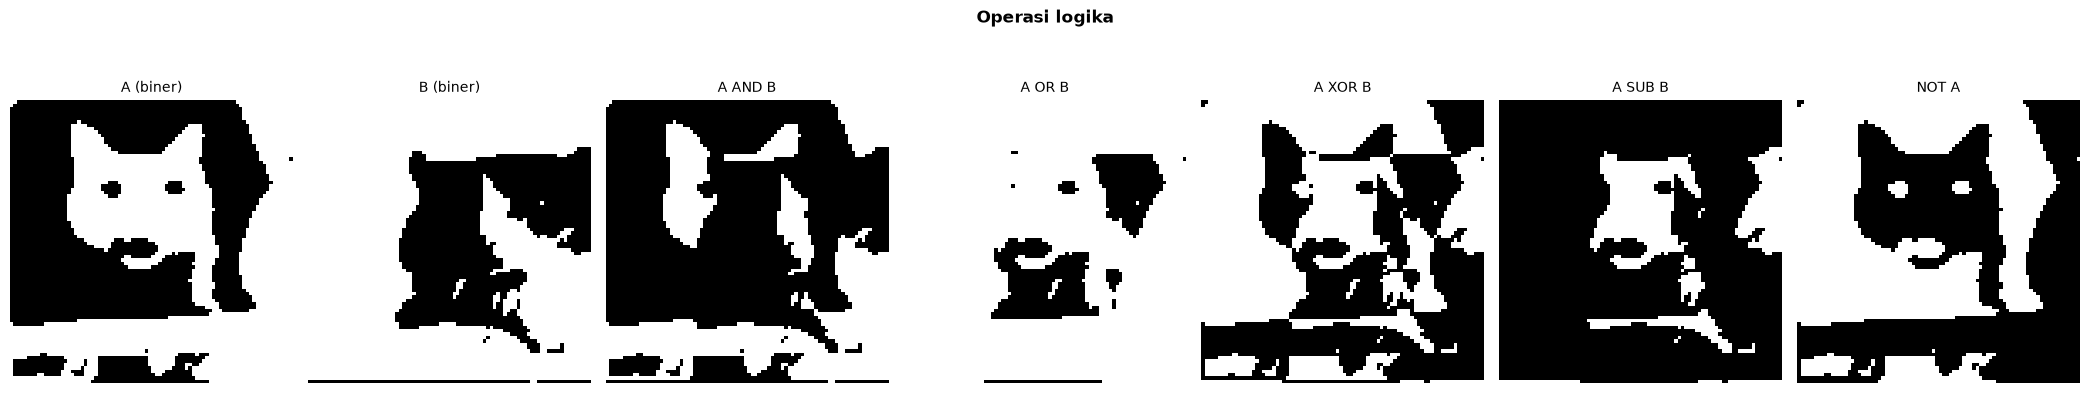


--- A (biner) (84 x 84) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0                255            255              0              0              0              0
y=1                255              0              0              0              0              0
y=2                  0              0              0              0              0              0
y=3                  0              0              0              0              0              0
y=4                  0              0              0              0              0              0
y=5                  0              0              0              0              0              0

--- B (biner) (84 x 84) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0                255            255            255            255            255  

In [34]:
citra_a = baca_citra(FILE["citra_a"], "rgb")
citra_b = baca_citra(FILE["citra_b"], "rgb")
citra_b = ubah_ukuran(citra_b, citra_a.shape[1], citra_a.shape[0])

wa, wb = 0.4, 0.6
c_blend = blending(citra_a, citra_b, wa, wb)
ra, rb = int(citra_a[0, 0, 0]), int(citra_b[0, 0, 0])
print(f"Contoh R di (0,0): C = {wa}*{ra} + {wb}*{rb} = {wa*ra + wb*rb:.1f} -> {c_blend[0,0,0]}")
tampil_citra_hist([("Citra A", citra_a), ("Citra B", citra_b), (f"Blending wa={wa}, wb={wb}", c_blend)], "Image blending")
simpan_gambar(out("hasil_blending.png"), c_blend)
cetak_nilai([("Citra A", citra_a), ("Citra B", citra_b), ("Blending", c_blend)], n=4)
simpan_ke_txt(out("hasil_blending.txt"), "1. Image Blending C = wa*A + wb*B",
            [("citra asli", "Citra A", citra_a), ("citra asli", "Citra B", citra_b), ("citra hasil", "Blending", c_blend)])

selisih, c_gerak = deteksi_gerakan(citra_a, citra_b)
berubah = int(np.where(mutlak(selisih).sum(axis=2) > 0, 1, 0).sum())
print(f"Piksel yang berubah (selisih != 0): {berubah} dari {selisih.shape[0] * selisih.shape[1]}")
tampil_citra_saja([("Citra A", citra_a), ("Citra B", citra_b), ("|A - B|", c_gerak)], "Deteksi gerakan C = A - B")
simpan_gambar(out("hasil_gerakan.png"), c_gerak)
cetak_nilai([("Selisih A - B (bertanda)", selisih), ("|A - B|", c_gerak)], n=4)
simpan_ke_txt(out("hasil_deteksi_gerakan.txt"), "2. Deteksi Gerakan C = A - B",
            [("citra asli", "Citra A", citra_a), ("citra asli", "Citra B", citra_b), ("citra hasil", "|A - B|", c_gerak)])

abu_a, abu_b = grayscale(citra_a), grayscale(citra_b)
biner_a = ambang_tunggal(abu_a, threshold_otsu(abu_a)[0] + 1) * 255
biner_b = ambang_tunggal(abu_b, threshold_otsu(abu_b)[0] + 1) * 255
logika = [("A (biner)", biner_a), ("B (biner)", biner_b),
        ("A AND B", logika_and(biner_a, biner_b)), ("A OR B", logika_or(biner_a, biner_b)),
        ("A XOR B", logika_xor(biner_a, biner_b)), ("A SUB B", logika_sub(biner_a, biner_b)),
        ("NOT A", logika_not(biner_a))]
tampil_citra_saja(logika, "Operasi logika", lebar_kolom=3)
cetak_nilai(logika[:4], n=6)
simpan_ke_txt(out("hasil_operasi_logika.txt"), "3. Operasi Logika",
            [("citra asli" if j.startswith(("A (", "B (")) else "citra hasil", j, c) for j, c in logika])

## Tugas 5 - Operasi global: ekualisasi histogram
`Ko = round( Ci · (2^k − 1) / (w · h) )`, Ci = distribusi kumulatif. Citra warna: rumus diterapkan ke tiap kanal R, G, B.

Nama file      : low_contrast.bmp
Format         : BMP
Resolusi       : 244 x 241 piksel (lebar w x tinggi h)
Jumlah piksel  : 58,804
Depth color    : 24 bit/piksel
Jumlah warna   : 2^24 = 16,777,216
Memori data    : 244 x 241 x 24 bit = 176,412 byte (172.3 KB)
Ukuran file    : 176,466 byte
Resolusi cetak : 144 dpi


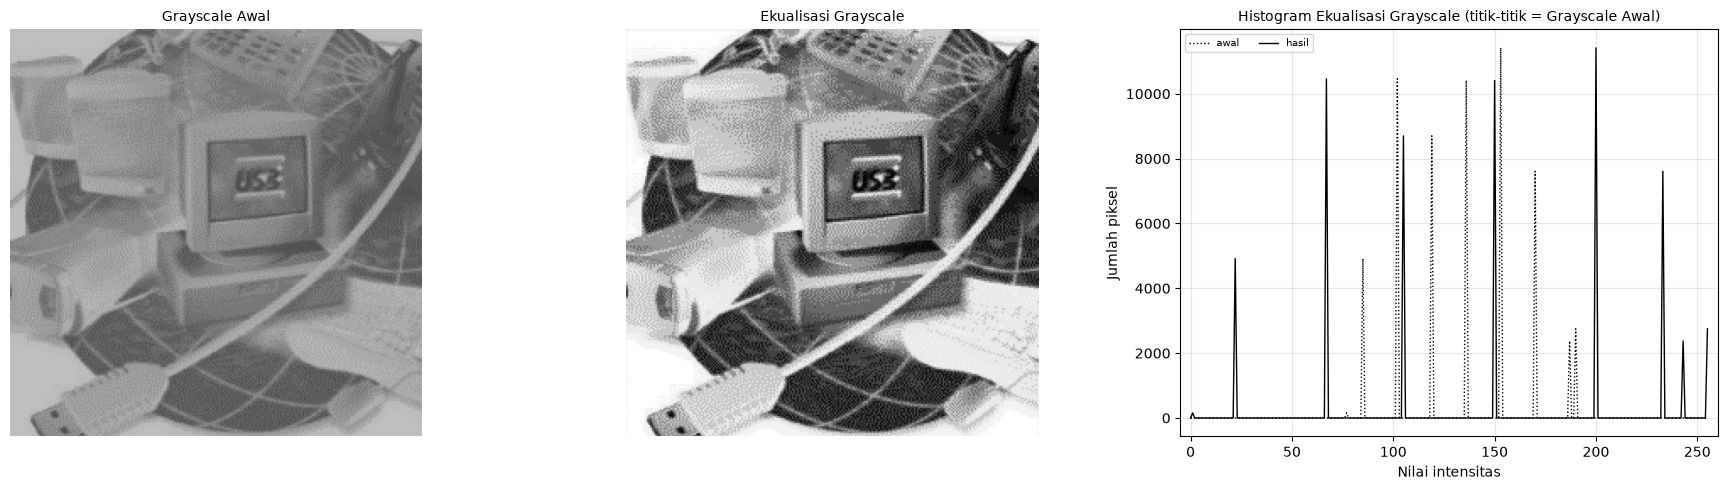


INFORMASI: Grayscale Awal
Ukuran citra   : lebar 244 x tinggi 241 (1 kanal)
Nilai minimum  : 77
Nilai maksimum : 190

INFORMASI: Ekualisasi Grayscale
Ukuran citra   : lebar 244 x tinggi 241 (1 kanal)
Nilai minimum  : 1
Nilai maksimum : 255

--- Grayscale Awal (244 x 241) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0                187            187            187            187            187            187
y=1                187            190            190            190            190            190
y=2                190            190            190            190            190            190
y=3                187            190            190            190            190            190
y=4                190            190            190            190            190            190
y=5                187            190            190            190            190            190


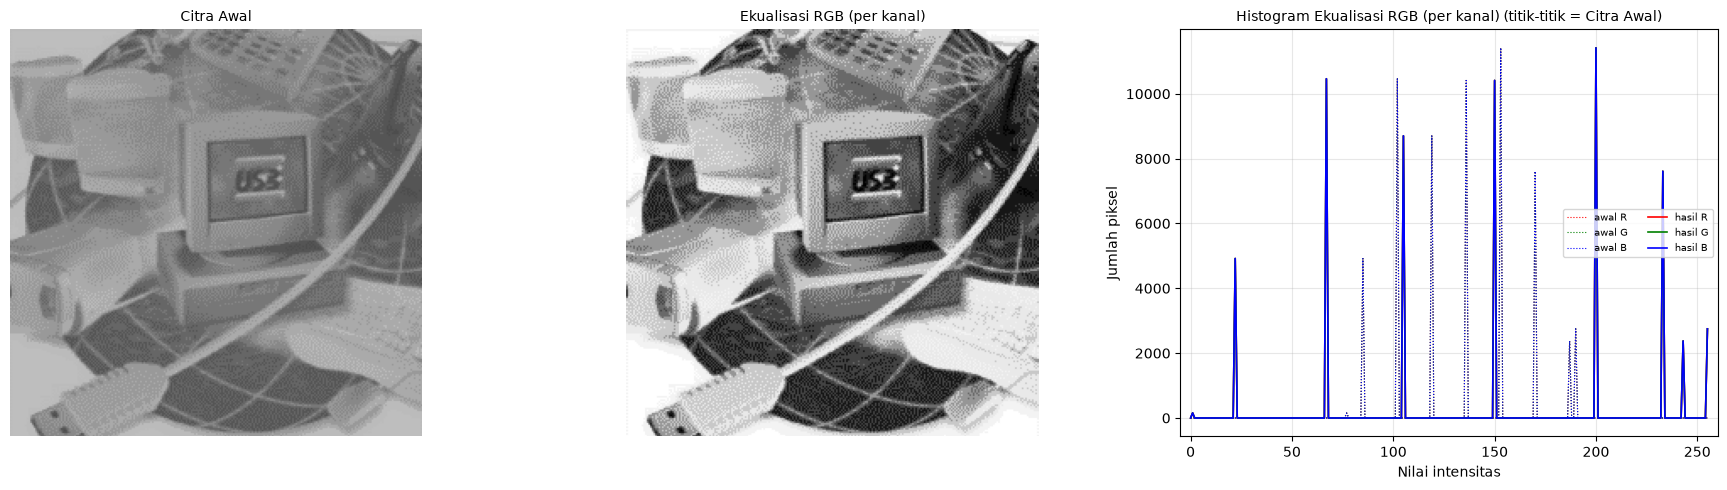


INFORMASI: Citra Awal
Ukuran citra   : lebar 244 x tinggi 241 x 3 kanal
Nilai minimum  : 77
Nilai maksimum : 190

INFORMASI: Ekualisasi RGB (per kanal)
Ukuran citra   : lebar 244 x tinggi 241 x 3 kanal
Nilai minimum  : 1
Nilai maksimum : 255

--- Citra Awal (244 x 241) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0      (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)  (187,187,187)
y=1      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=2      (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=3      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=4      (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)
y=5      (187,187,187)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)  (190,190,190)

-

In [35]:
info = baca_properti(FILE["ekualisasi"])
citra = baca_citra(FILE["ekualisasi"], "rgb")
abu = grayscale(citra)
hasil_abu = ekualisasi(abu)
hasil_rgb = ekualisasi_citra(citra)

tampil_operasi(abu, hasil_abu, "Grayscale Awal", "Ekualisasi Grayscale")
tampil_operasi(citra, hasil_rgb, "Citra Awal", "Ekualisasi RGB (per kanal)")
print(f"Rentang gray sebelum: {abu.min()}..{abu.max()}  ->  sesudah: {hasil_abu.min()}..{hasil_abu.max()}")
simpan_gambar(out("hasil_ekualisasi_gray.png"), hasil_abu)
simpan_gambar(out("hasil_ekualisasi_rgb.png"), hasil_rgb)
tulis_sebelum_sesudah(out("hasil_ekualisasi_gray.txt"), "Ekualisasi histogram (grayscale)", abu, hasil_abu)
tulis_sebelum_sesudah(out("hasil_ekualisasi_rgb.txt"), "Ekualisasi histogram (per kanal R, G, B)", citra, hasil_rgb)

# Contoh buku: 2 4 3 1 3 6 4 3 1 0 3 2 (k = 3 bit -> 2^3-1 = 7)
_ = tabel_ekualisasi([2, 4, 3, 1, 3, 6, 4, 3, 1, 0, 3, 2], k=3, judul="Contoh di buku")

## Tugas 6 - Operasi bertetangga
Operator memakai tetangga `p1..p9` (`p5` = titik yang diproses). Jendela 3x3 tanpa padding → **bingkai paling luar tidak diproses**, hasil berukuran (h−2) x (w−2).

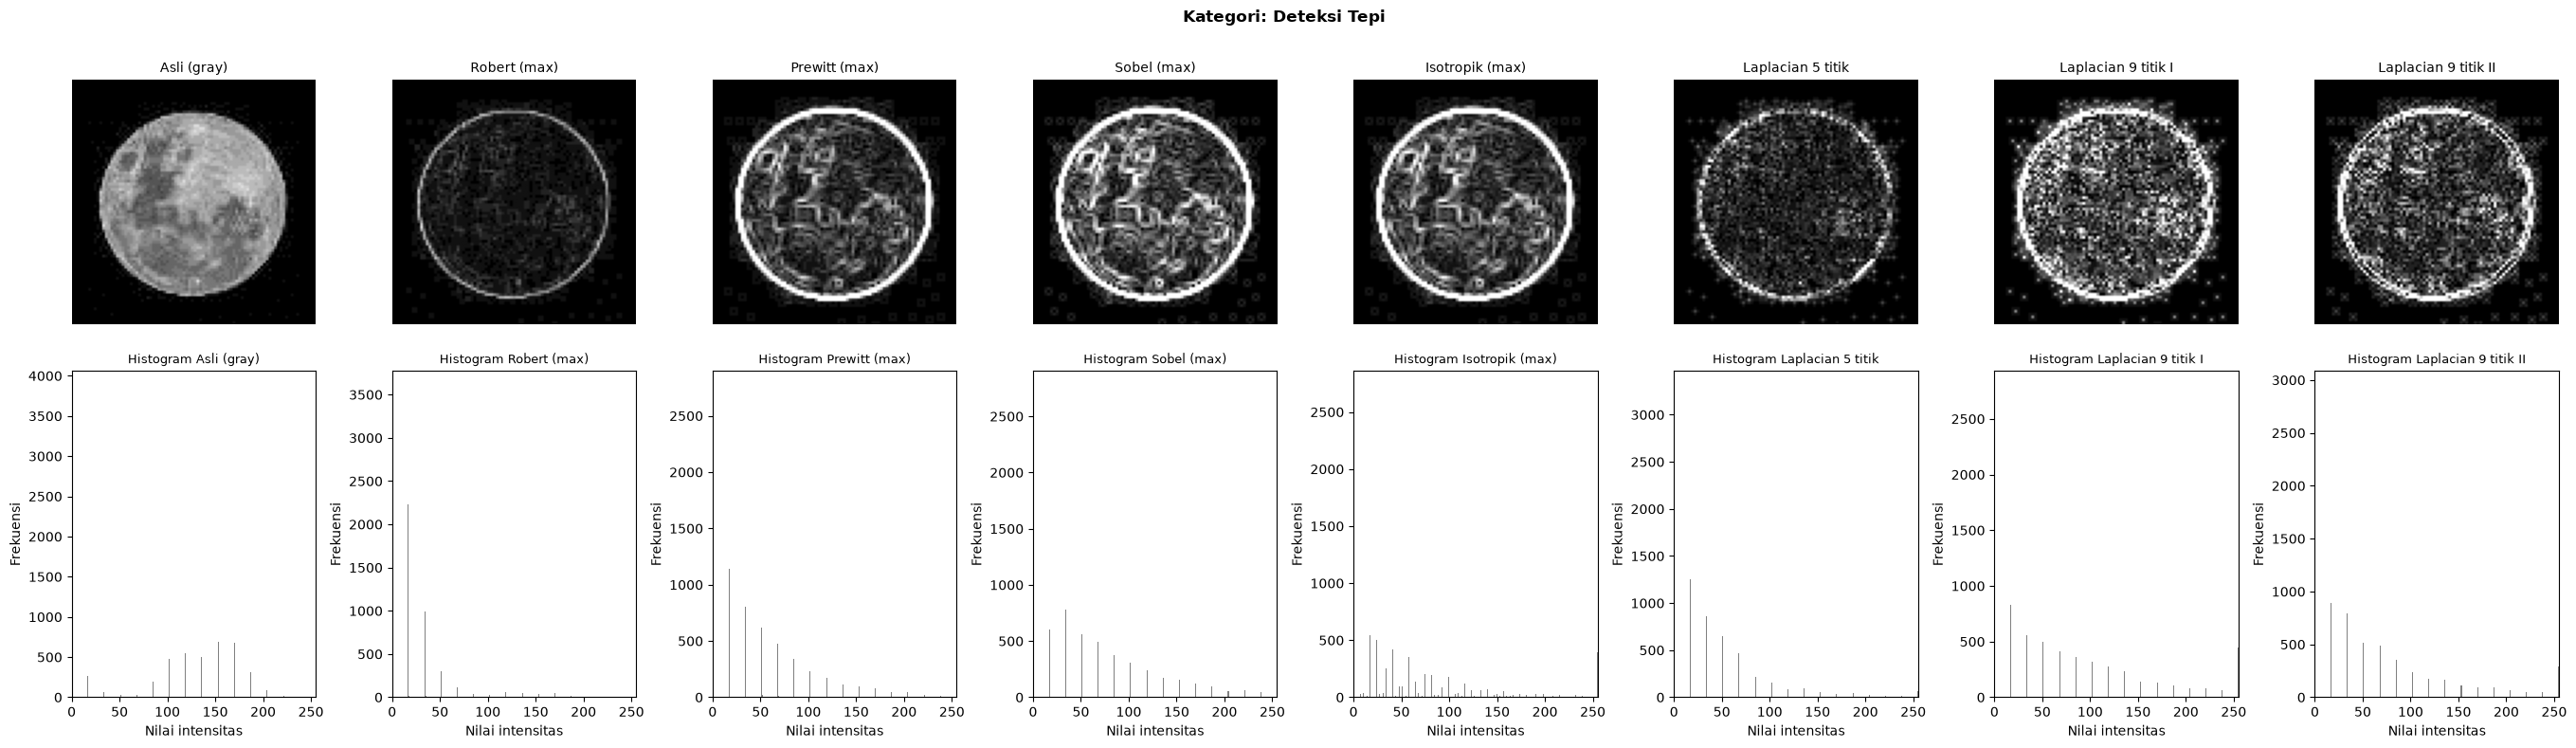

Gambar disimpan: hasil\Deteksi_Tepi_Robert_max.png
Gambar disimpan: hasil\Deteksi_Tepi_Prewitt_max.png
Gambar disimpan: hasil\Deteksi_Tepi_Sobel_max.png
Gambar disimpan: hasil\Deteksi_Tepi_Isotropik_max.png
Gambar disimpan: hasil\Deteksi_Tepi_Laplacian_5_titik.png
Gambar disimpan: hasil\Deteksi_Tepi_Laplacian_9_titik_I.png
Gambar disimpan: hasil\Deteksi_Tepi_Laplacian_9_titik_II.png


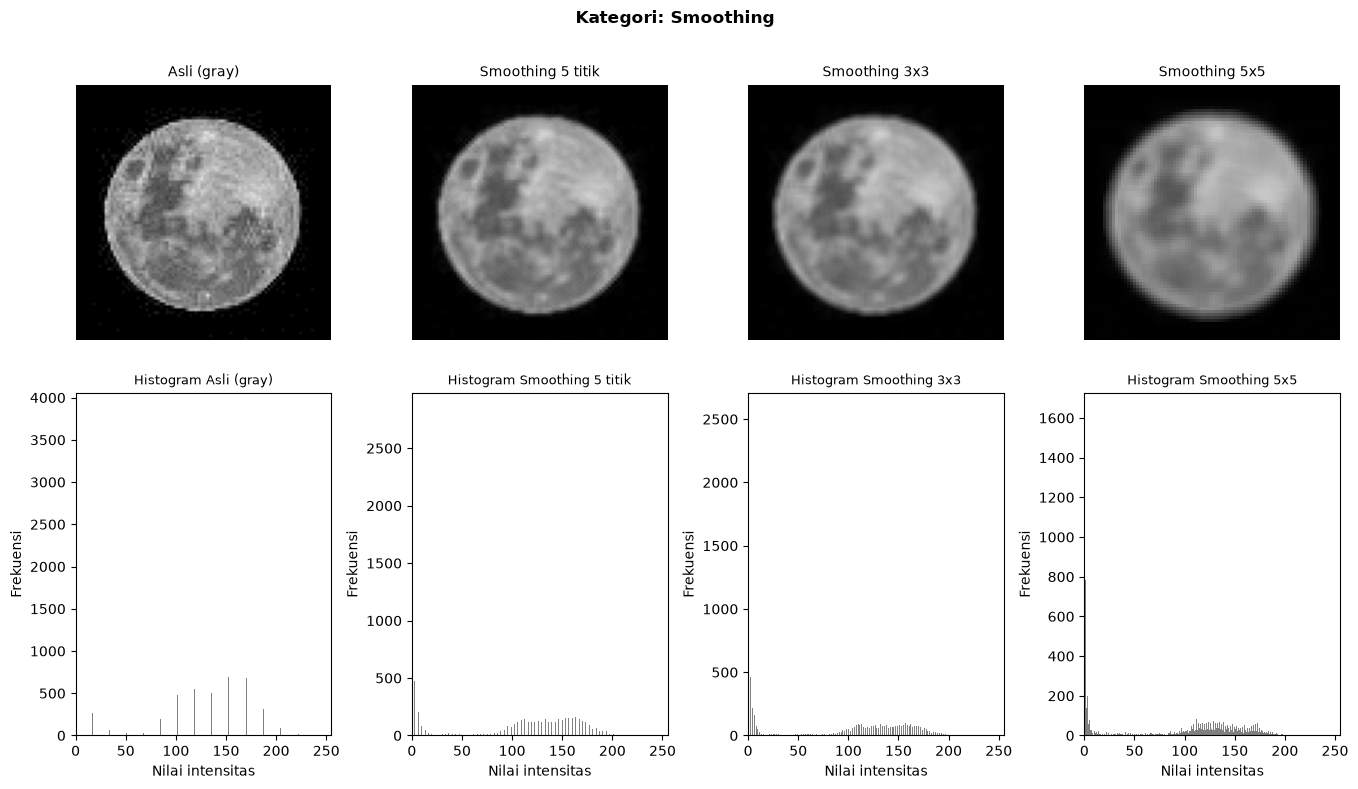

Gambar disimpan: hasil\Smoothing_Smoothing_5_titik.png
Gambar disimpan: hasil\Smoothing_Smoothing_3x3.png
Gambar disimpan: hasil\Smoothing_Smoothing_5x5.png


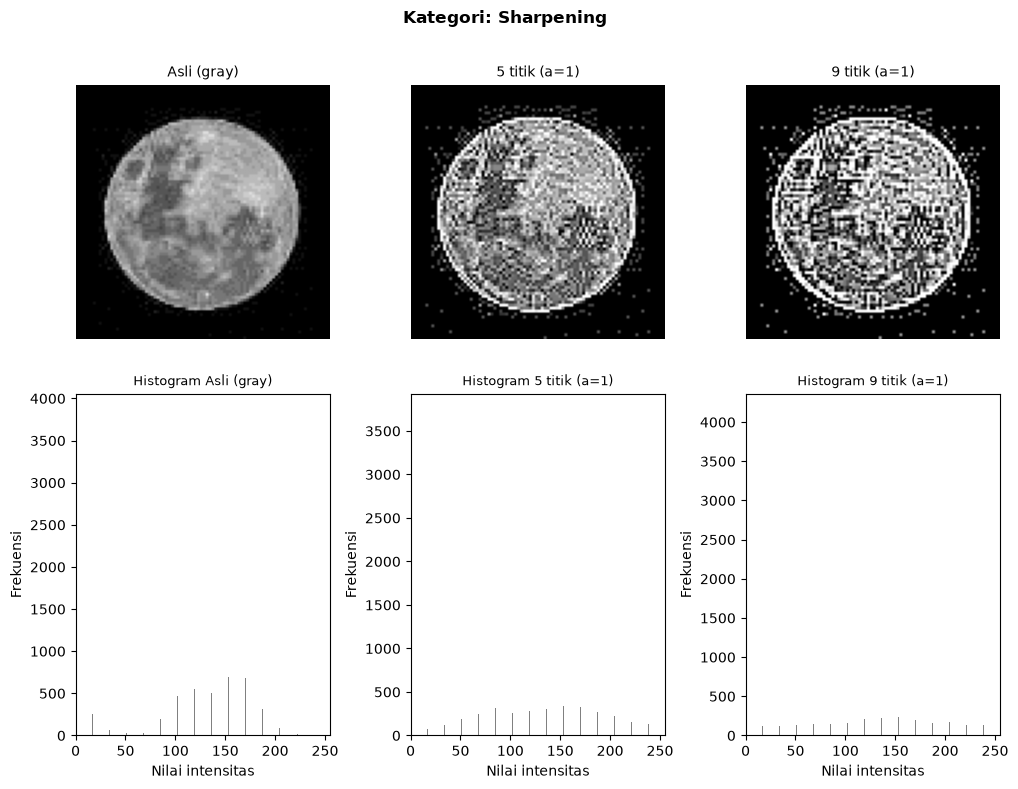

Gambar disimpan: hasil\Sharpening_5_titik_a1.png
Gambar disimpan: hasil\Sharpening_9_titik_a1.png


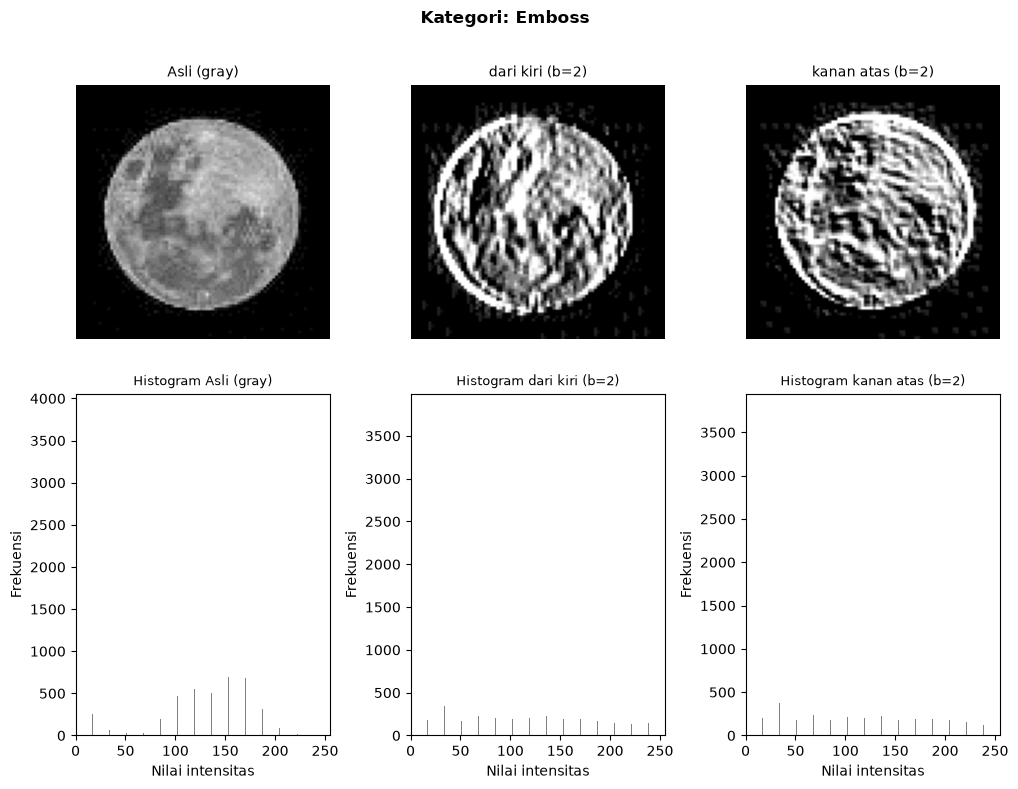

Gambar disimpan: hasil\Emboss_dari_kiri_b2.png
Gambar disimpan: hasil\Emboss_kanan_atas_b2.png


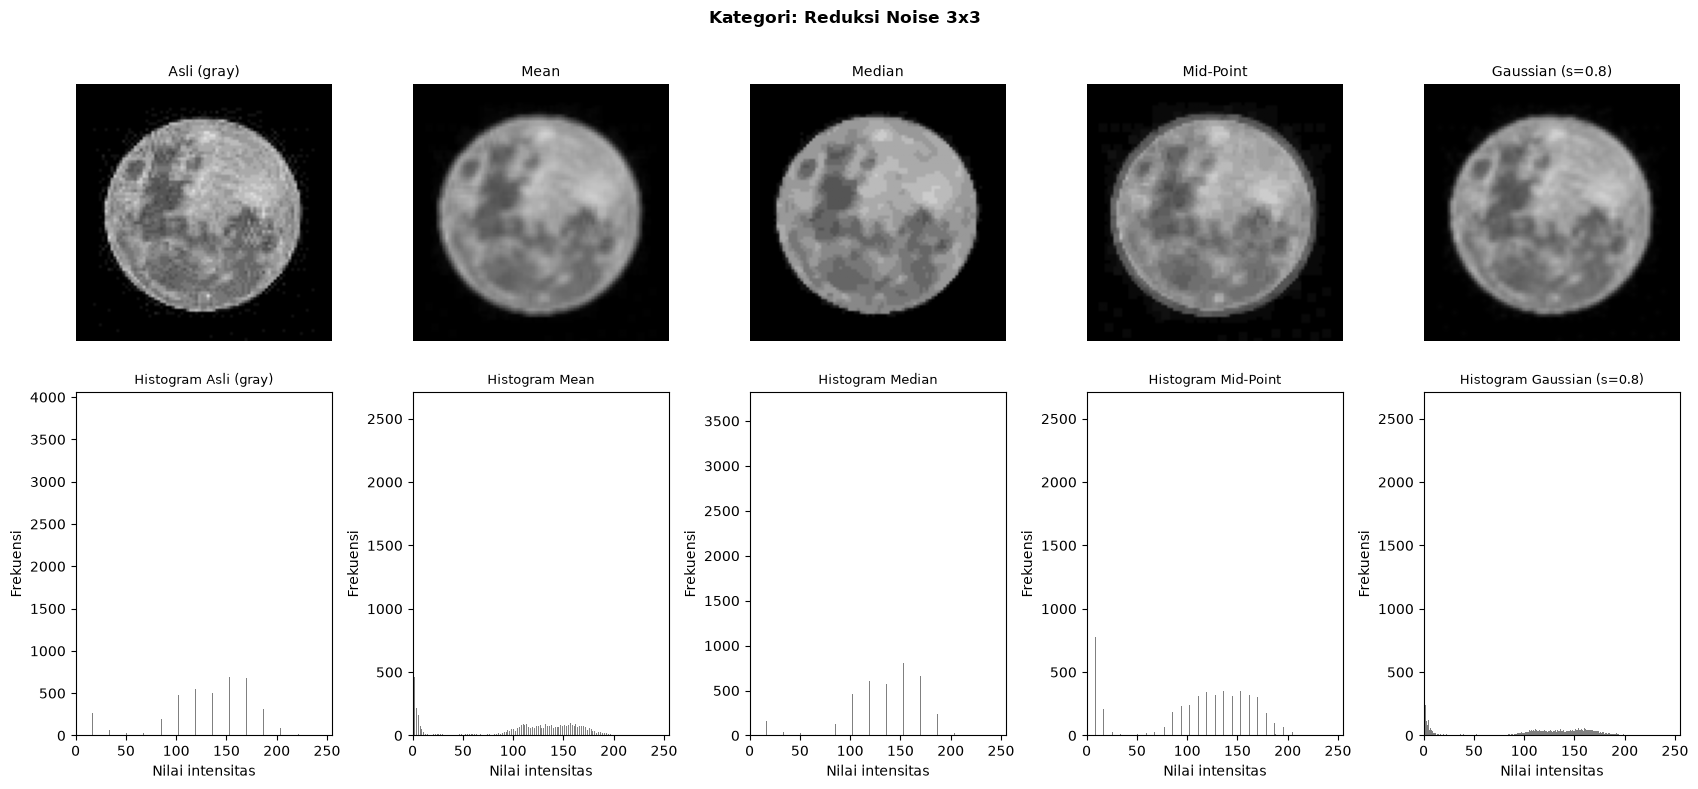

Gambar disimpan: hasil\Reduksi_Noise_3x3_Mean.png
Gambar disimpan: hasil\Reduksi_Noise_3x3_Median.png
Gambar disimpan: hasil\Reduksi_Noise_3x3_Mid-Point.png
Gambar disimpan: hasil\Reduksi_Noise_3x3_Gaussian_s0.8.png
Matriks piksel disimpan: hasil\hasil_matriks_tetangga.txt

--- Grayscale (asli) (88 x 88) | nilai f(x,y) untuk x=0..4, y=0..4 ---
                    x=0            x=1            x=2            x=3            x=4
y=0                  0              0              0              0              0
y=1                  0              0              0              0              0
y=2                  0              0              0              0              0
y=3                  0              0              0              0              0
y=4                  0              0              0              0              0

--- Robert (max) (87 x 87) | nilai f(x,y) untuk x=0..4, y=0..4 ---
                    x=0            x=1            x=2            x=3            x=4
y=0

In [36]:
citra_t = baca_citra(FILE["tetangga"], "rgb")
abu = grayscale(citra_t)
q1, q2, q3, q4 = ekstrak_tetangga_2x2(abu)
p1, p2, p3, p4, p5, p6, p7, p8, p9 = ekstrak_tetangga_3x3(abu)
alpha_val, beta_val, sigma_val = 1, 2, 0.8

daftar_operasi = [
    ("Deteksi Tepi", [
        ("Robert (max)", operator_robert(q1, q2, q3, q4)),
        ("Prewitt (max)", operator_prewitt(p1, p2, p3, p4, p6, p7, p8, p9)),
        ("Sobel (max)", operator_sobel(p1, p2, p3, p4, p6, p7, p8, p9)),
        ("Isotropik (max)", operator_isotropik(p1, p2, p3, p4, p6, p7, p8, p9)),
        ("Laplacian 5 titik", operator_laplacian_5(p2, p4, p5, p6, p8)),
        ("Laplacian 9 titik I", operator_laplacian_9_1(p1, p2, p3, p4, p5, p6, p7, p8, p9)),
        ("Laplacian 9 titik II", operator_laplacian_9_2(p1, p2, p3, p4, p5, p6, p7, p8, p9)),
    ]),
    ("Smoothing", [
        ("Smoothing 5 titik", operator_smoothing_5(p2, p4, p5, p6, p8)),
        ("Smoothing 3x3", operator_smoothing_9(p1, p2, p3, p4, p5, p6, p7, p8, p9)),
        ("Smoothing 5x5", operator_smoothing_25(abu)),
    ]),
    ("Sharpening", [
        (f"5 titik (a={alpha_val})", operator_sharpening_5(p2, p4, p5, p6, p8, alpha_val)),
        (f"9 titik (a={alpha_val})", operator_sharpening_9(p1, p2, p3, p4, p5, p6, p7, p8, p9, alpha_val)),
    ]),
    ("Emboss", [
        (f"dari kiri (b={beta_val})", operator_emboss_kiri(p1, p3, p4, p5, p6, p7, p9, beta_val)),
        (f"kanan atas (b={beta_val})", operator_emboss_kanan(p2, p3, p4, p5, p6, p7, p8, beta_val)),
    ]),
    ("Reduksi Noise 3x3", [
        ("Mean", operator_mean(p1, p2, p3, p4, p5, p6, p7, p8, p9)),
        ("Median", operator_median(p1, p2, p3, p4, p5, p6, p7, p8, p9)),
        ("Mid-Point", operator_midpoint(p1, p2, p3, p4, p5, p6, p7, p8, p9)),
        (f"Gaussian (s={sigma_val})", operator_gaussian(abu, sigma_val)),
    ]),
]
data_txt = [("citra asli", "Grayscale", abu)]
for kategori, daftar in daftar_operasi:
    tampil = [("Asli (gray)", abu)] + [(j, ke_uint8(m)) for j, m in daftar]
    tampil_citra_hist(tampil, f"Kategori: {kategori}", lebar_kolom=3.4)
    for j, m in daftar:
        simpan_gambar(out(f"{kategori}_{j}.png".replace(" ", "_").replace("(", "").replace(")", "").replace("=", "")), ke_uint8(m))
        data_txt.append(("citra hasil", f"{kategori}: {j}", ke_uint8(m)))
simpan_ke_txt(out("hasil_matriks_tetangga.txt"), "Operasi Bertetangga", data_txt)
cetak_nilai([("Grayscale (asli)", abu)] + [(j, ke_uint8(m)) for j, m in daftar_operasi[0][1][:2]], n=5)
print("Catatan: hasil 3x3 berukuran (h-2) x (w-2), jadi f(0,0) hasil = piksel asli f(1,1).")

### Tugas 6B - Deteksi tepi yang bagus: RGB → grayscale → biner → tepi
Pada citra grayscale, Robert/Sobel menghasilkan garis **tebal dan bergradasi** (banyak nilai abu-abu).
Kalau citra dibinerkan dulu, nilainya hanya 0/1, sehingga perubahan nilai hanya terjadi tepat di batas objek → **garis tipis 1 piksel**.
Citra dengan warna solid (latar polos) akan sangat jelas tepinya tanpa usaha ekstra.
Pembanding: tepi morfologi (A − erosi A) dan Canny manual (Gaussian → Sobel → non-maximum suppression → ambang ganda → hysteresis).

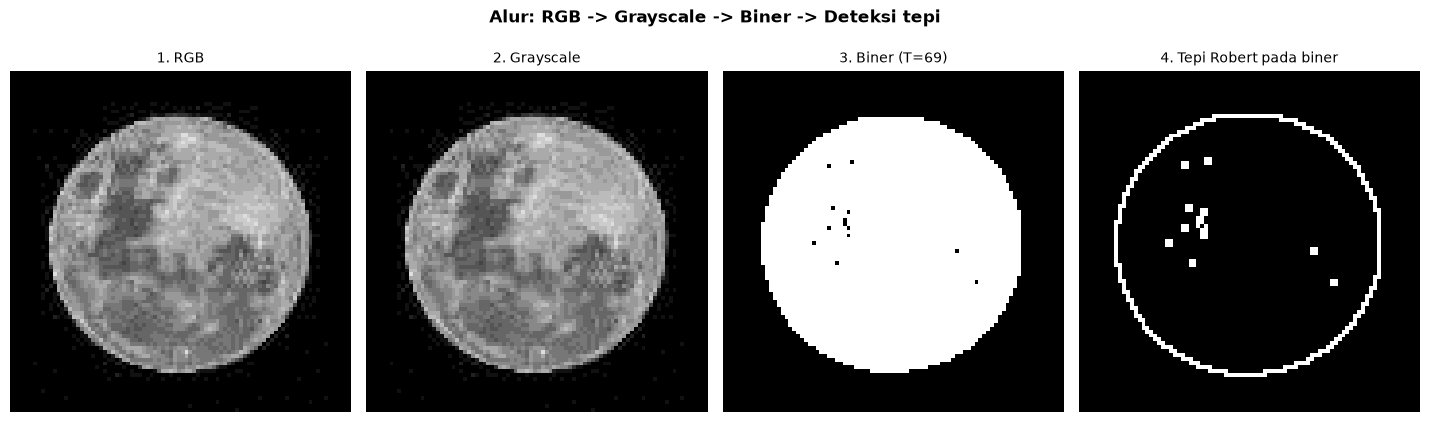

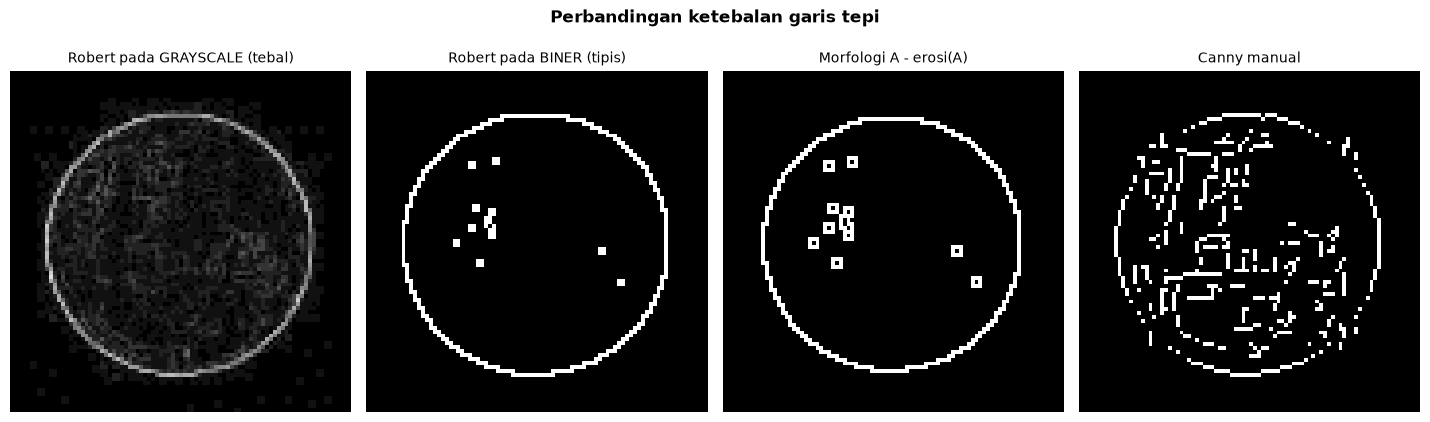

Jumlah piksel yang dianggap tepi:
  Robert grayscale (>0) : 3977
  Robert biner          : 314
  Morfologi             : 351
  Canny manual          : 518
Matriks piksel disimpan: hasil\hasil_tepi_biner.txt
Gambar disimpan: hasil\tepi_robert_biner.png
Gambar disimpan: hasil\tepi_morfologi.png
Gambar disimpan: hasil\tepi_canny.png


In [37]:
abu8 = grayscale(citra_t)
t_otsu, _ = threshold_otsu(abu8)
biner = ambang_tunggal(abu8, t_otsu + 1)                  # 0/1

robert_gray = ke_uint8(operator_robert(*ekstrak_tetangga_2x2(abu8)))
robert_biner = tepi_dari_biner(biner)
morf = tepi_morfologi(biner)
canny = canny_manual(abu8, sigma=1.0, rendah=30, tinggi=80)

tampil_citra_saja([("1. RGB", citra_t), ("2. Grayscale", abu8), (f"3. Biner (T={t_otsu + 1})", biner),
                ("4. Tepi Robert pada biner", robert_biner)],
                "Alur: RGB -> Grayscale -> Biner -> Deteksi tepi", lebar_kolom=3.6)
tampil_citra_saja([("Robert pada GRAYSCALE (tebal)", robert_gray), ("Robert pada BINER (tipis)", robert_biner),
                ("Morfologi A - erosi(A)", morf), ("Canny manual", canny)],
                "Perbandingan ketebalan garis tepi", lebar_kolom=3.6)
print("Jumlah piksel yang dianggap tepi:")
print(f"  Robert grayscale (>0) : {int(np.where(robert_gray > 0, 1, 0).sum())}")
print(f"  Robert biner          : {int(robert_biner.sum())}")
print(f"  Morfologi             : {int(morf.sum())}")
print(f"  Canny manual          : {int(canny.sum())}")
simpan_ke_txt(out("hasil_tepi_biner.txt"), "RGB -> Gray -> Biner -> Tepi",
            [("citra asli", "Grayscale", abu8), ("citra hasil", "Biner", biner), ("citra hasil", "Tepi Robert biner", robert_biner),
            ("citra hasil", "Tepi morfologi", morf), ("citra hasil", "Tepi Canny", canny)])
for j, c in [("tepi_robert_biner", robert_biner), ("tepi_morfologi", morf), ("tepi_canny", canny)]:
    simpan_gambar(out(j + ".png"), c)

### Tugas 6C - Pertanyaan dosen: elemen 3x3, nilai mana yang berubah? Bagaimana dapat nilai tepi?
Kernel di papan tulis: `[[0,-1,0],[-1,0,-1],[0,-1,0]]` dioperasikan ke citra (sum of products).

In [38]:
M = MATRIKS_BUKU
print("Citra 5x5:\n", M)

def demo_kernel(nama, kernel):
    print("\n" + "=" * 64 + f"\n{nama}\n" + "=" * 64)
    print("Kernel:\n", np.array(kernel), "\nJumlah bobot =", np.array(kernel).sum())
    dalam = konvolusi(M, kernel, "valid")
    print("Hanya 3x3 piksel DALAM yang berubah (kernel muat penuh):\n", dalam)
    print("Citra setelah operasi, bingkai luar tetap nilai asli:\n", kembalikan_bingkai(M, dalam))
    print("Kalau pakai padding replicate, ke-25 piksel ikut dihitung:\n", konvolusi(M, kernel, "replicate"))

demo_kernel("Kernel papan tulis", [[0, -1, 0], [-1, 0, -1], [0, -1, 0]])
demo_kernel("Laplacian 5 titik (jumlah bobot 0 -> nilai TEPI)", [[0, -1, 0], [-1, 4, -1], [0, -1, 0]])

# Versi morfologi (elemen penstruktur 3x3 pada citra biner)
A = np.array([[0,0,0,0,0,0,0],
            [0,1,1,1,1,1,0],
            [0,1,1,1,1,1,0],
            [0,1,1,1,1,1,0],
            [0,1,1,1,1,1,0],
            [0,0,0,0,0,0,0]], dtype=np.uint8)
print("\nCitra biner A:\n", A)
print("Erosi A (SE 3x3): hanya piksel yang 8 tetangganya semua 1 yang tetap 1\n", erosi(A))
print("Dilasi A: piksel 0 yang punya tetangga 1 berubah jadi 1\n", dilasi(A))
print("Tepi = A - erosi(A) -> garis tepi 1 piksel:\n", tepi_morfologi(A))

Citra 5x5:
 [[250 240 200 200 180]
 [240 200 180 150 150]
 [180 160 160 150 120]
 [180 140 120 120 100]
 [160 130 100  80  60]]

Kernel papan tulis
Kernel:
 [[ 0 -1  0]
 [-1  0 -1]
 [ 0 -1  0]] 
Jumlah bobot = -4
Hanya 3x3 piksel DALAM yang berubah (kernel muat penuh):
 [[-820. -710. -680.]
 [-680. -610. -550.]
 [-590. -520. -450.]]
Citra setelah operasi, bingkai luar tetap nilai asli:
 [[ 250.  240.  200.  200.  180.]
 [ 240. -820. -710. -680.  150.]
 [ 180. -680. -610. -550.  120.]
 [ 180. -590. -520. -450.  100.]
 [ 160.  130.  100.   80.   60.]]
Kalau pakai padding replicate, ke-25 piksel ikut dihitung:
 [[-980. -890. -820. -730. -710.]
 [-870. -820. -710. -680. -600.]
 [-760. -680. -610. -550. -520.]
 [-660. -590. -520. -450. -400.]
 [-630. -530. -430. -360. -300.]]

Laplacian 5 titik (jumlah bobot 0 -> nilai TEPI)
Kernel:
 [[ 0 -1  0]
 [-1  4 -1]
 [ 0 -1  0]] 
Jumlah bobot = 0
Hanya 3x3 piksel DALAM yang berubah (kernel muat penuh):
 [[-20.  10. -80.]
 [-40.  30.  50.]
 [-30. -40

## Tugas 7 - Thresholding
**Global:** manual (nilai ekstrem), rata-rata, histogram analysis (lembah), Otsu. **Lokal (adaptif):** mean, Gaussian. Semua dengan rumus; hasil 0 = hitam, 1 = putih.

[1] Manual - persentase putih untuk T ekstrem:
    T | % putih (Ki>=T) |  % hitam
   30 |          28.17% |   71.83%
   60 |          19.38% |   80.62%
  180 |           3.64% |   96.36%
  220 |           0.56% |   99.44%
[2] Rata-rata         : T = 41
[3] Histogram analysis: puncak 17 & 190 -> lembah T = 176
[4] Otsu              : varian antar-kelas maks pada t = 84 -> T = 85


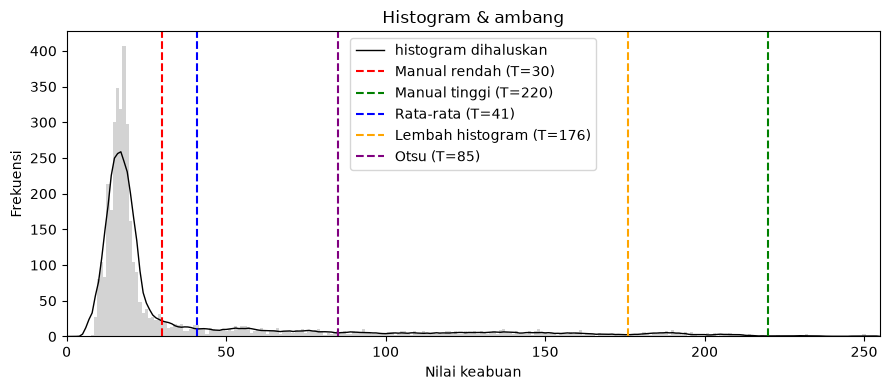

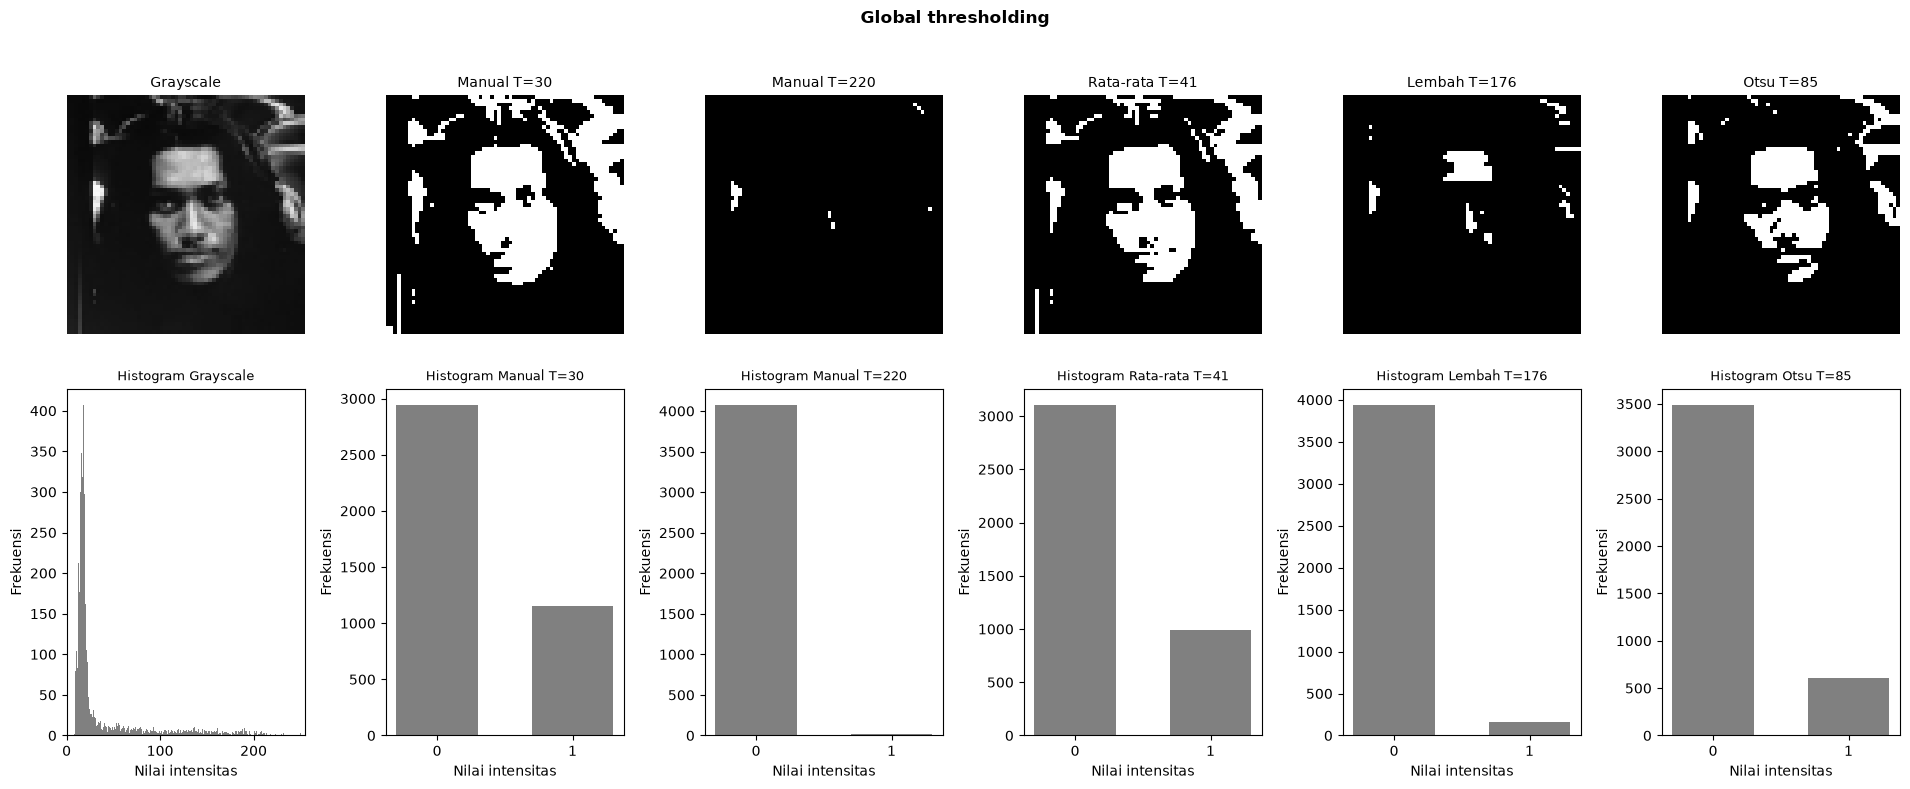

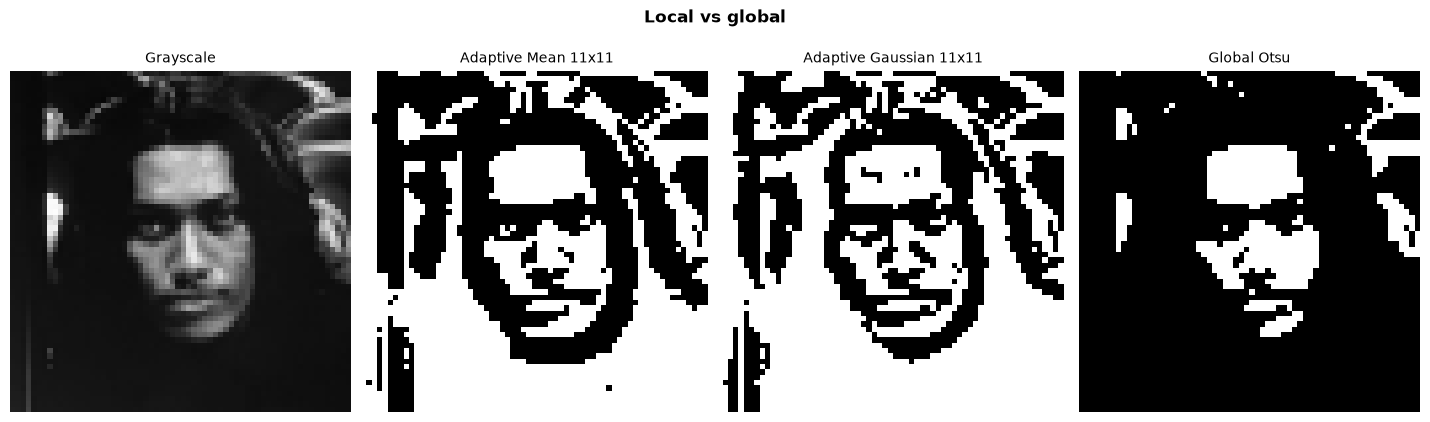


--- Grayscale (64 x 64) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0                 10             10             10             10              9             10
y=1                 11             10             10             10              8              9
y=2                 12             11             10              9              9              9
y=3                 12             11             10              9              9              9
y=4                 12             11             10              9              9             10
y=5                 12             11             10             10              9              9

--- Manual T=30 (64 x 64) | nilai f(x,y) untuk x=0..5, y=0..5 ---
                    x=0            x=1            x=2            x=3            x=4            x=5
y=0                  0              0              0              0              0

In [39]:
citra_th = baca_citra(FILE["threshold"], "rgb")
abu = grayscale(citra_th)

print("[1] Manual - persentase putih untuk T ekstrem:")
ringkas_threshold(abu, [30, 60, 180, 220])
T_rata = threshold_rata_rata(abu)
T_hist, hs, (pk1, pk2) = threshold_histogram_analysis(abu)
t_otsu, var_otsu = threshold_otsu(abu)
print(f"[2] Rata-rata         : T = {T_rata}")
print(f"[3] Histogram analysis: puncak {pk1} & {pk2} -> lembah T = {T_hist}")
print(f"[4] Otsu              : varian antar-kelas maks pada t = {t_otsu} -> T = {t_otsu + 1}")
plot_histogram_ambang(abu, {"Manual rendah": 30, "Manual tinggi": 220, "Rata-rata": T_rata,
                            "Lembah histogram": T_hist, "Otsu": t_otsu + 1}, hs=hs)

hasil_global = [("Grayscale", abu), ("Manual T=30", ambang_tunggal(abu, 30)), ("Manual T=220", ambang_tunggal(abu, 220)),
                (f"Rata-rata T={T_rata}", ambang_tunggal(abu, T_rata)),
                (f"Lembah T={T_hist}", ambang_tunggal(abu, T_hist)), (f"Otsu T={t_otsu + 1}", ambang_tunggal(abu, t_otsu + 1))]
tampil_citra_hist(hasil_global, "Global thresholding", lebar_kolom=3.2)

c_mean, _ = threshold_adaptive_mean(abu, 11, 2)
c_gauss, _ = threshold_adaptive_gaussian(abu, 11, 2)
tampil_citra_saja([("Grayscale", abu), ("Adaptive Mean 11x11", c_mean), ("Adaptive Gaussian 11x11", c_gauss),
                (f"Global Otsu", ambang_tunggal(abu, t_otsu + 1))], "Local vs global", lebar_kolom=3.6)
cetak_nilai(hasil_global[:3], n=6)
simpan_ke_txt(out("hasil_operasi_thresholding.txt"), "Tugas 7 - Thresholding",
            [("citra input" if j == "Grayscale" else "citra hasil", j, c) for j, c in hasil_global]
            + [("citra hasil", "Adaptive Mean", c_mean), ("citra hasil", "Adaptive Gaussian", c_gauss)])
for j, c in hasil_global[1:] + [("adaptive_mean", c_mean), ("adaptive_gauss", c_gauss)]:
    simpan_gambar(out("threshold_" + j.replace(" ", "_").replace("=", "") + ".png"), c)

## Studi kasus
- **Foto blur** → penajaman (citra asli + citra tepi). Kalau juga ada noise: **reduksi noise dulu → baru sharpen** (kalau dibalik, noise ikut dipertajam).
- **Foto bernoise** → median (bagus untuk bintik salt & pepper) → sharpening ringan.
- **Kontras tidak seimbang** → ekualisasi histogram.

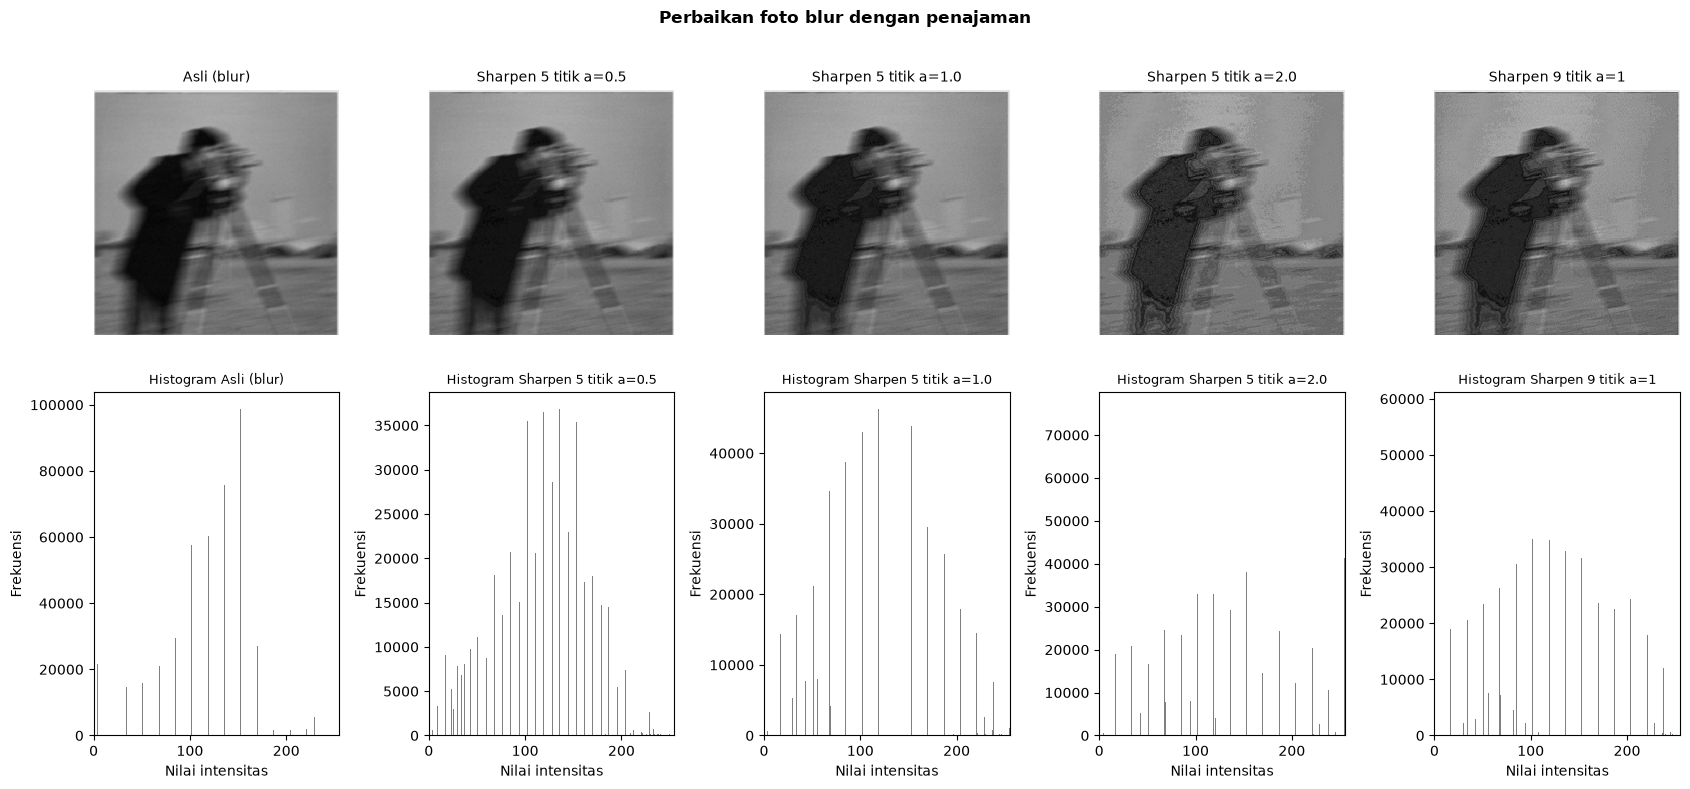

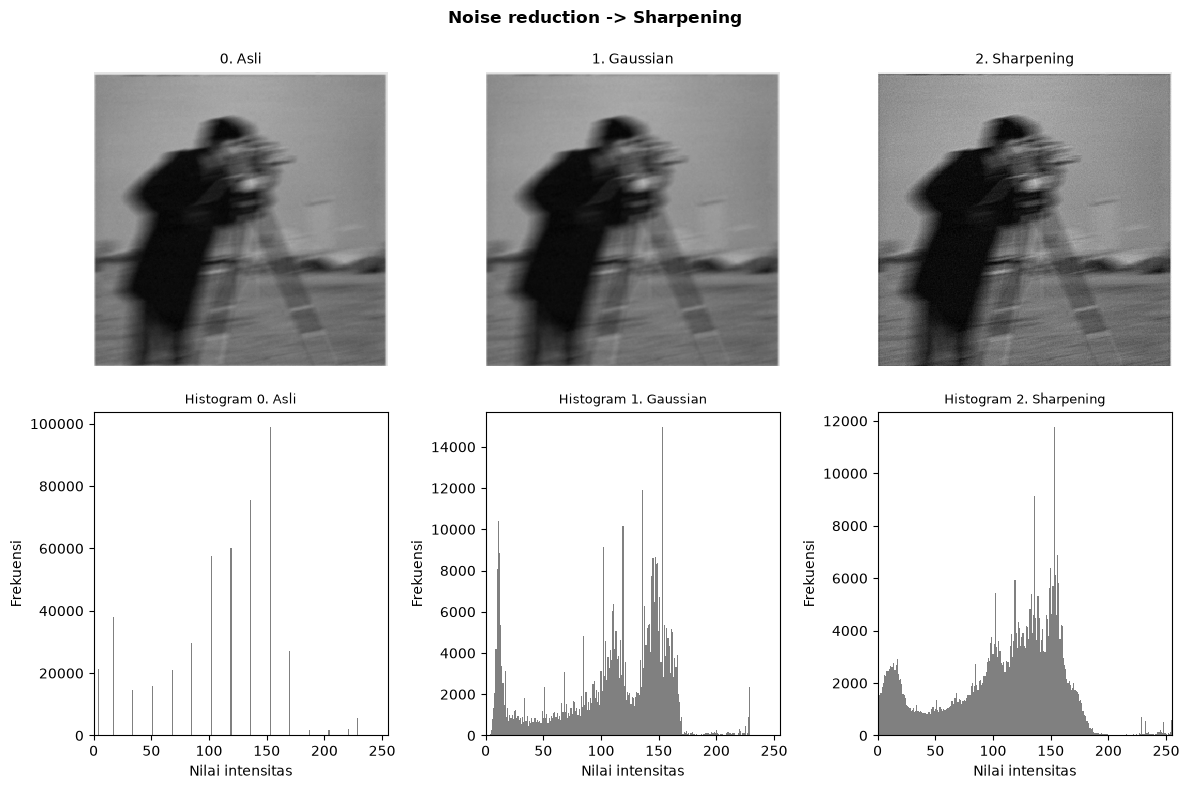

Gambar disimpan: hasil\blur_pipeline.png
Matriks piksel disimpan: hasil\hasil_pipeline_perbaikan_blur.txt


In [40]:
abu_blur = baca_citra(FILE["blur"], "gray")
p = ekstrak_tetangga_3x3(abu_blur)
varian = [("Asli (blur)", abu_blur)]
for a in (0.5, 1.0, 2.0):
    varian.append((f"Sharpen 5 titik a={a}", ke_uint8(operator_sharpening_5(p[1], p[3], p[4], p[5], p[7], a))))
varian.append(("Sharpen 9 titik a=1", ke_uint8(operator_sharpening_9(*p, 1.0))))
tampil_citra_hist(varian, "Perbaikan foto blur dengan penajaman", lebar_kolom=3.4)

# Pipeline: Gaussian (kurangi noise) -> sharpening
gs = ke_uint8(operator_gaussian(abu_blur, 0.8))
sh = ke_uint8(operator_sharpening_9(*ekstrak_tetangga_3x3(gs), 1.0))
tampil_citra_hist([("0. Asli", abu_blur), ("1. Gaussian", gs), ("2. Sharpening", sh)],
                "Noise reduction -> Sharpening", lebar_kolom=4)
simpan_gambar(out("blur_pipeline.png"), sh)
simpan_ke_txt(out("hasil_pipeline_perbaikan_blur.txt"), "Studi kasus blur: Gaussian -> Sharpening",
            [("citra asli", "Asli", abu_blur), ("citra hasil", "Gaussian", gs), ("citra hasil", "Sharpening", sh)])

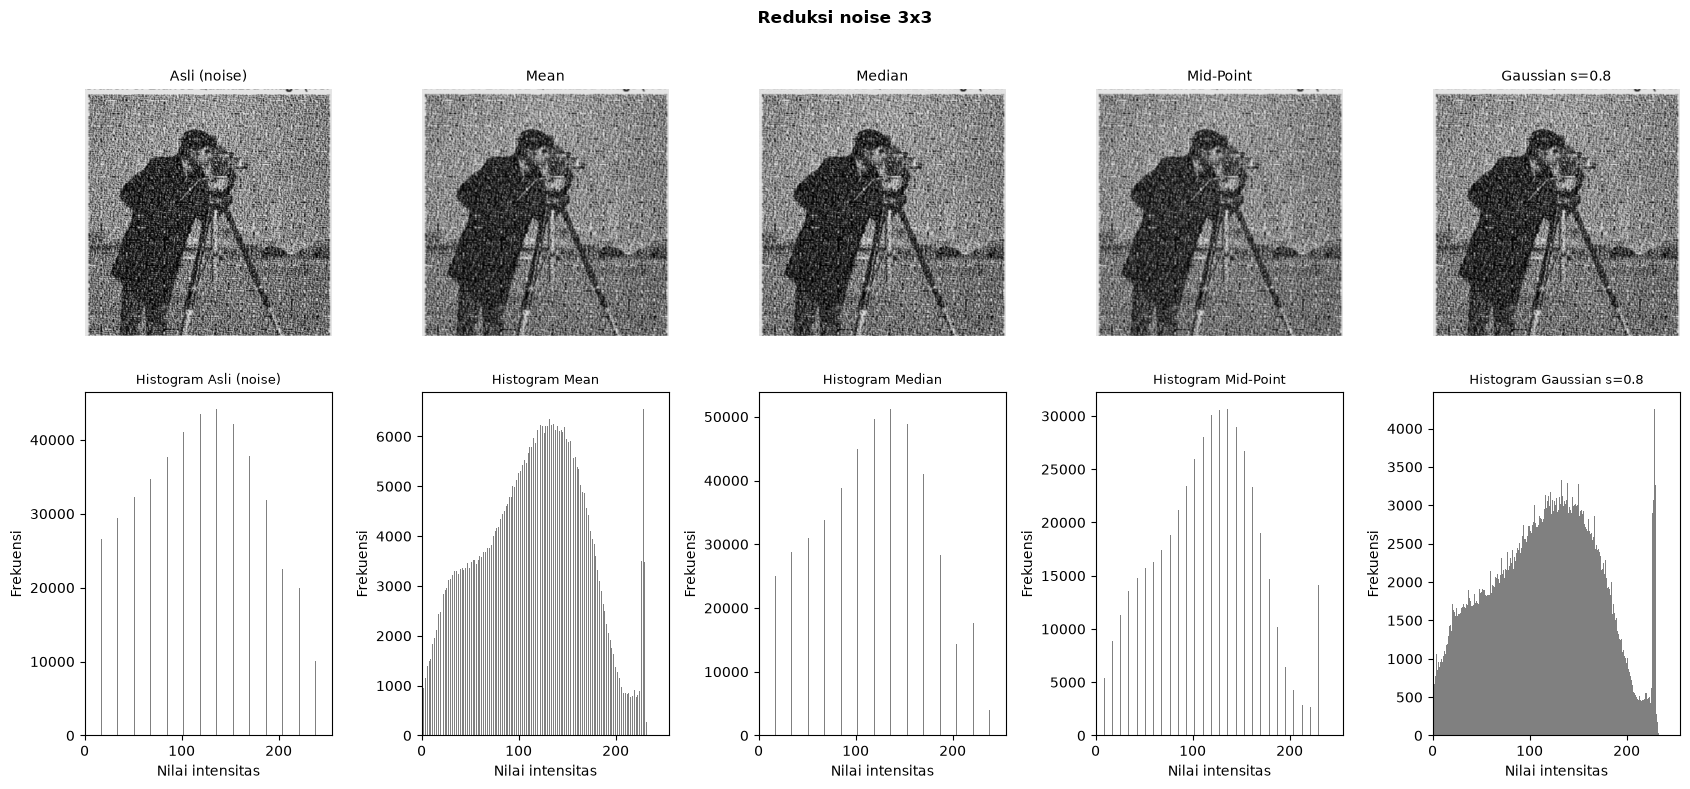

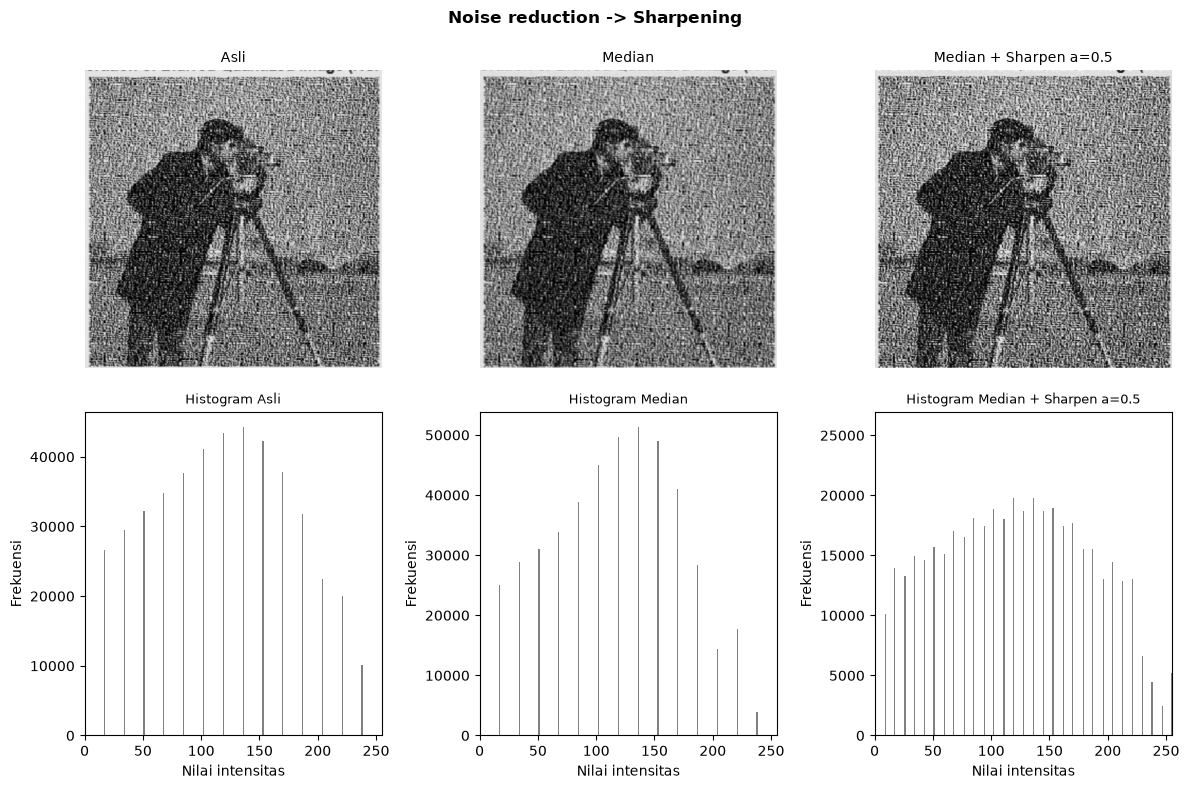

Gambar disimpan: hasil\noise_median_sharpen.png
Matriks piksel disimpan: hasil\hasil_pipeline_noise.txt


In [41]:
abu_noise = baca_citra(FILE["noise"], "gray")
p = ekstrak_tetangga_3x3(abu_noise)
filter_noise = [("Asli (noise)", abu_noise), ("Mean", ke_uint8(operator_mean(*p))),
                ("Median", ke_uint8(operator_median(*p))), ("Mid-Point", ke_uint8(operator_midpoint(*p))),
                ("Gaussian s=0.8", ke_uint8(operator_gaussian(abu_noise, 0.8)))]
tampil_citra_hist(filter_noise, "Reduksi noise 3x3", lebar_kolom=3.4)
med = filter_noise[2][1]
akhir = ke_uint8(operator_sharpening_5(*[ekstrak_tetangga_3x3(med)[i] for i in (1, 3, 4, 5, 7)], 0.5))
tampil_citra_hist([("Asli", abu_noise), ("Median", med), ("Median + Sharpen a=0.5", akhir)],
                "Noise reduction -> Sharpening", lebar_kolom=4)
simpan_gambar(out("noise_median_sharpen.png"), akhir)
simpan_ke_txt(out("hasil_pipeline_noise.txt"), "Studi kasus noise: Median -> Sharpening",
            [("citra asli", "Asli", abu_noise), ("citra hasil", "Median", med), ("citra hasil", "Median + Sharpen", akhir)])

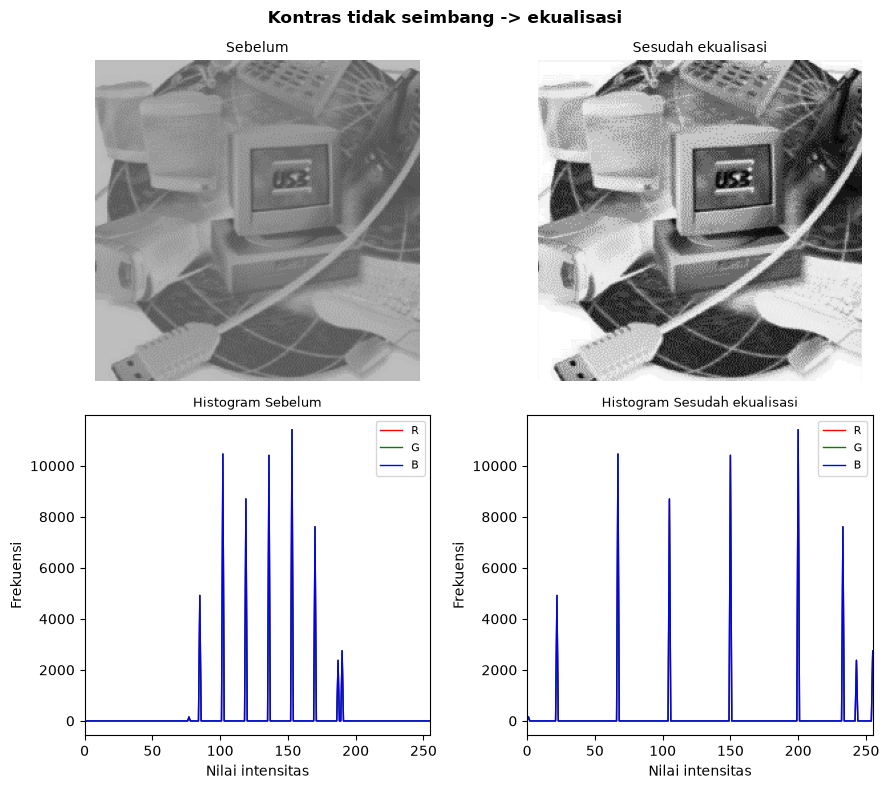

Gambar disimpan: hasil\kontras_ekualisasi.png
Nilai sebelum & sesudah disimpan: hasil\hasil_kontras_ekualisasi.txt


In [42]:
citra_k = baca_citra(FILE["kontras"], "rgb")
hasil_k = ekualisasi_citra(citra_k)
tampil_citra_hist([("Sebelum", citra_k), ("Sesudah ekualisasi", hasil_k)], "Kontras tidak seimbang -> ekualisasi")
simpan_gambar(out("kontras_ekualisasi.png"), hasil_k)
tulis_sebelum_sesudah(out("hasil_kontras_ekualisasi.txt"), "Studi kasus kontras: ekualisasi", citra_k, hasil_k)

## Latihan TES TULIS — hex → desimal → ekualisasi (soal Tugas PCD 3 no. 3)
Cara manual: 2 digit heksa = digit1 × 16 + digit2 (A=10 … F=15). Contoh `A3 = 10×16 + 3 = 163`.

Contoh: A3 = 163 | biner: 10100011 | 7F = 127
Matriks desimal:
 [[163 164 171 154 144 167 177 162]
 [127 130 139 140 118 119 144 148]
 [100 112 111 117 115 141 177 188]
 [ 95 103  92  81  99 126 170 181]
 [123  90 118 107  88  96 126 198]
 [221 125  98  73  84 112 113 205]
 [242 163 121 131 137 172 108 154]
 [242 159 148 207 206 212 164 187]]
=== Soal hex 8x8 ===
n = w x h = 64 piksel, k = 8 bit -> 2^k - 1 = 255
  Ki  Frek   Ci    Ci*(2^k-1)/(w*h)    Ko
  73     1    1  1*255/64 =    3.98     4
  81     1    2  2*255/64 =    7.97     8
  84     1    3  3*255/64 =   11.95    12
  88     1    4  4*255/64 =   15.94    16
  90     1    5  5*255/64 =   19.92    20
  92     1    6  6*255/64 =   23.91    24
  95     1    7  7*255/64 =   27.89    28
  96     1    8  8*255/64 =   31.88    32
  98     1    9  9*255/64 =   35.86    36
  99     1   10  10*255/64 =   39.84    40
 100     1   11  11*255/64 =   43.83    44
 103     1   12  12*255/64 =   47.81    48
 107     1   13  13*255/64 =   51.8

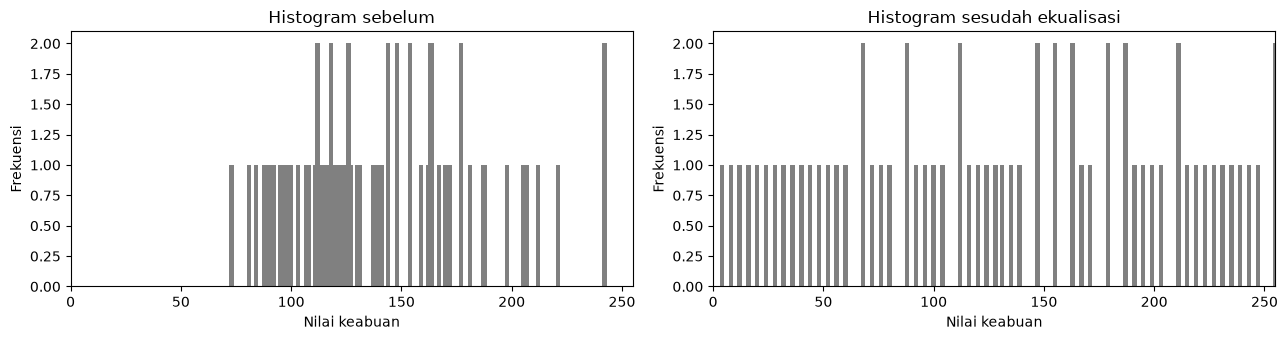

In [43]:
HEX = '''A3 A4 AB 9A 90 A7 B1 A2
7F 82 8B 8C 76 77 90 94
64 70 6F 75 73 8D B1 BC
5F 67 5C 51 63 7E AA B5
7B 5A 76 6B 58 60 7E C6
DD 7D 62 49 54 70 71 CD
F2 A3 79 83 89 AC 6C 9A
F2 9F 94 CF CE D4 A4 BB'''
mat = np.array([[hex_ke_desimal(h) for h in baris.split()] for baris in HEX.splitlines()])
print("Contoh: A3 =", hex_ke_desimal("A3"), "| biner:", desimal_ke_biner(163), "| 7F =", hex_ke_desimal("7F"))
print("Matriks desimal:\n", mat)
hasil_eq = tabel_ekualisasi(mat, k=8, judul="Soal hex 8x8")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].bar(np.arange(256), histogram(mat), width=2, color="gray"); ax[0].set_title("Histogram sebelum")
ax[1].bar(np.arange(256), histogram(hasil_eq), width=2, color="gray"); ax[1].set_title("Histogram sesudah ekualisasi")
for a in ax: a.set_xlim(0, 255); a.set_xlabel("Nilai keabuan"); a.set_ylabel("Frekuensi")
plt.tight_layout(); plt.show()

## SEL PERKIRAAN DEMO UTS
Saat demo dosen biasanya memberi studi kasus (mis. "citra diputar", "dipotong di titik ...", "deteksi tepinya").
Cukup ubah variabel di bawah. Semua fungsi sudah ada di Sel 1, jadi tidak perlu menulis ulang.

Nama file      : image_rgb_1.bmp
Format         : BMP
Resolusi       : 64 x 64 piksel (lebar w x tinggi h)
Jumlah piksel  : 4,096
Depth color    : 24 bit/piksel
Jumlah warna   : 2^24 = 16,777,216
Memori data    : 64 x 64 x 24 bit = 12,288 byte (12.0 KB)
Ukuran file    : 12,342 byte
Resolusi cetak : 72 dpi
Citra asal       : w = 64, h = 64
Potong horizontal: di y = 32 (GENAP)
Bagian 1         : 64 x 32   Bagian 2: 64 x 32
Bagian 1 di-'90cw' -> 32 x 64
Hasil gabung     : 64 x 96 (A di atas, rata kiri)


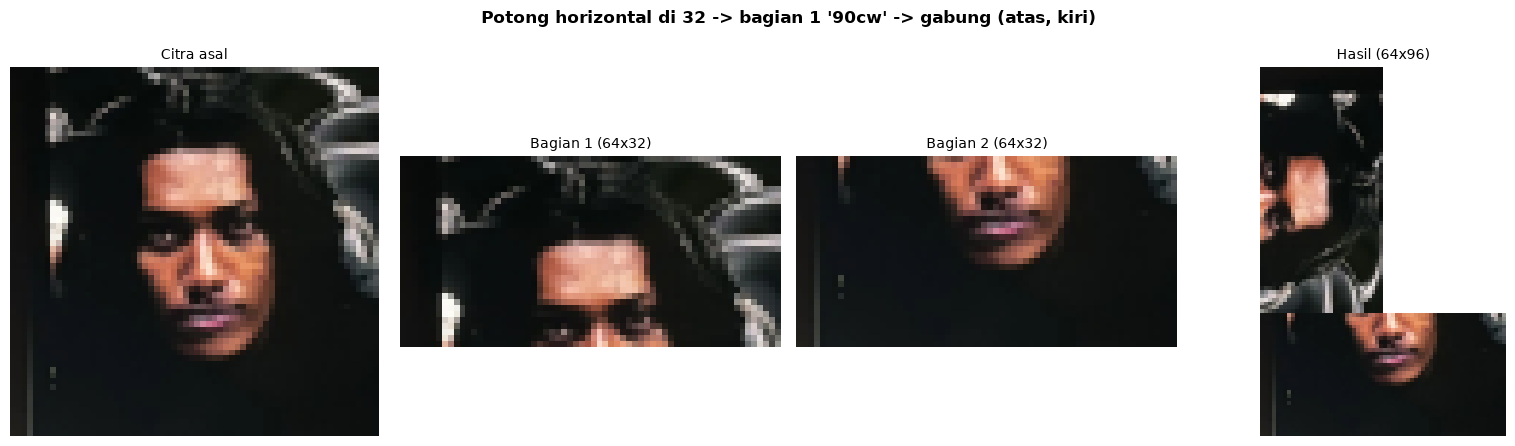

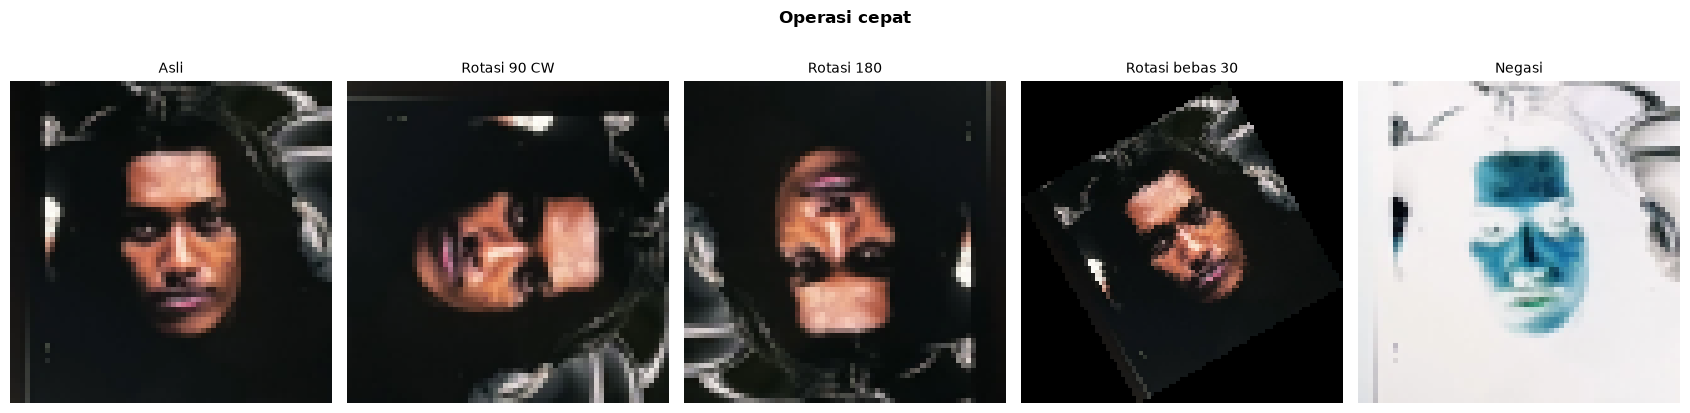

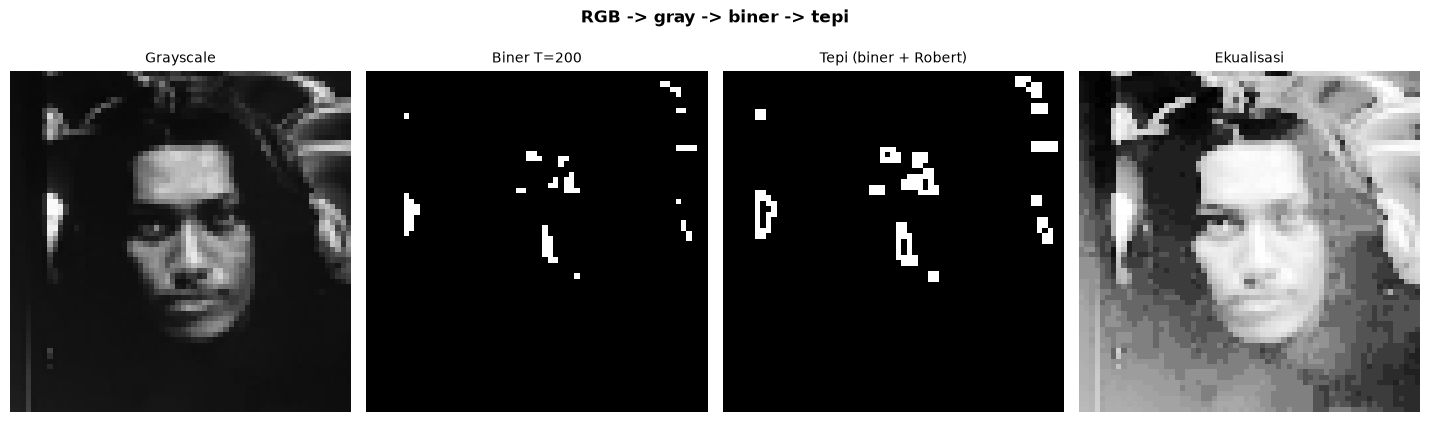

In [44]:
# ==================== UBAH DI SINI ====================
NAMA_FILE   = FILE["geometri"]   # file dari dosen, mis. "soal.jpg"
ARAH_POTONG = "horizontal"       # "horizontal" (atas/bawah) atau "vertikal" (kiri/kanan)
TITIK       = None               # None = tengah; atau angka, mis. 300
DIPUTAR     = 1                  # bagian yang diputar: 1 atau 2
CARA_PUTAR  = "90cw"             # "90cw" | "90ccw" | "180" | "flip_h" | "flip_v" | angka mis. 30
LETAK       = "atas"             # posisi bagian 1 thd bagian 2: "atas" | "bawah" | "kiri" | "kanan"
RATA        = "kiri"             # atas/bawah -> "kiri"|"tengah"|"kanan" ; kiri/kanan -> "atas"|"tengah"|"bawah"
SUDUT_BEBAS = 30                 # rotasi bebas (derajat, CCW)
T_MANUAL    = 200                # threshold manual (pilih ekstrem, bukan 128)
# ======================================================

info = baca_properti(NAMA_FILE)
img = baca_citra(NAMA_FILE, "rgb")
abu = grayscale(img)

_ = potong_putar_gabung(img, ARAH_POTONG, TITIK, DIPUTAR, CARA_PUTAR, LETAK, RATA)
tampil_citra_saja([("Asli", img), ("Rotasi 90 CW", rotasi_90_cw(img)), ("Rotasi 180", rotasi_180(img)),
                (f"Rotasi bebas {SUDUT_BEBAS}", rotasi_bebas(img, SUDUT_BEBAS)), ("Negasi", negatif(img))],
                "Operasi cepat", lebar_kolom=3.4)
biner = ambang_tunggal(abu, T_MANUAL)
tampil_citra_saja([("Grayscale", abu), (f"Biner T={T_MANUAL}", biner), ("Tepi (biner + Robert)", tepi_dari_biner(biner)),
                ("Ekualisasi", ekualisasi(abu))], "RGB -> gray -> biner -> tepi", lebar_kolom=3.6)